# Libraries

In [31]:
#### libraries ####
import os
import mne
import numpy as np
import matplotlib.pyplot as plt
import pickle
import pandas as pd


from scipy import signal
from scipy.io import wavfile

# from pybv import write_brainvision
from pyprep.prep_pipeline import PrepPipeline
from mne_icalabel import label_components

# autoreject
from autoreject import AutoReject
from autoreject import get_rejection_threshold

# working directory
work_dir = '/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/'

# read in participant file
df = pd.read_csv(work_dir + 'data_analysis/participants_include.txt', delimiter = '\t')
include_ppts = df[df['include']==1]['participant'].astype(str).tolist()
include_ppts = [x for x in include_ppts if x.split('_')[0]=='VOT']

# create a montage file for the pipeline
montage = mne.channels.make_standard_montage("standard_1020")

# Raw data quality check

Extracting parameters from /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal//data_raw/eeg_brainvision/CUE2024_0075_F0.vhdr...
Setting channel info structure...
Reading 0 ... 2013779  =      0.000 ...  4027.558 secs...
<Info | 8 non-empty values
 bads: []
 ch_names: Fp1, Fz, F3, F7, FT9, FC5, FC1, C3, T7, CP5, CP1, Pz, P3, P7, ...
 chs: 31 EEG
 custom_ref_applied: False
 dig: 34 items (3 Cardinal, 31 EEG)
 highpass: 0.0 Hz
 lowpass: 140.0 Hz
 meas_date: 2025-11-20 11:54:24 UTC
 nchan: 31
 projs: []
 sfreq: 500.0 Hz
>
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 0.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Filter length: 3301 samples (6.

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.3s


Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).


/opt/anaconda3/lib/python3.12/site-packages/mne/viz/utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


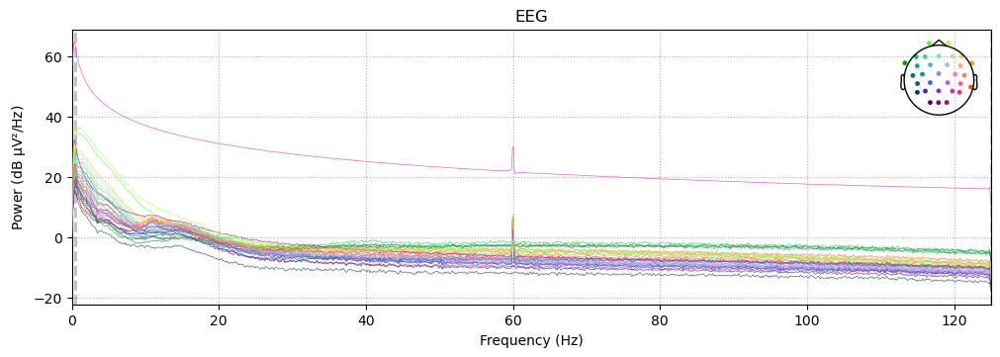

/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_72426/2100180444.py:34: RuntimeWarning: More events than default colors available. You should pass a list of unique colors.
  fig = mne.viz.plot_events(


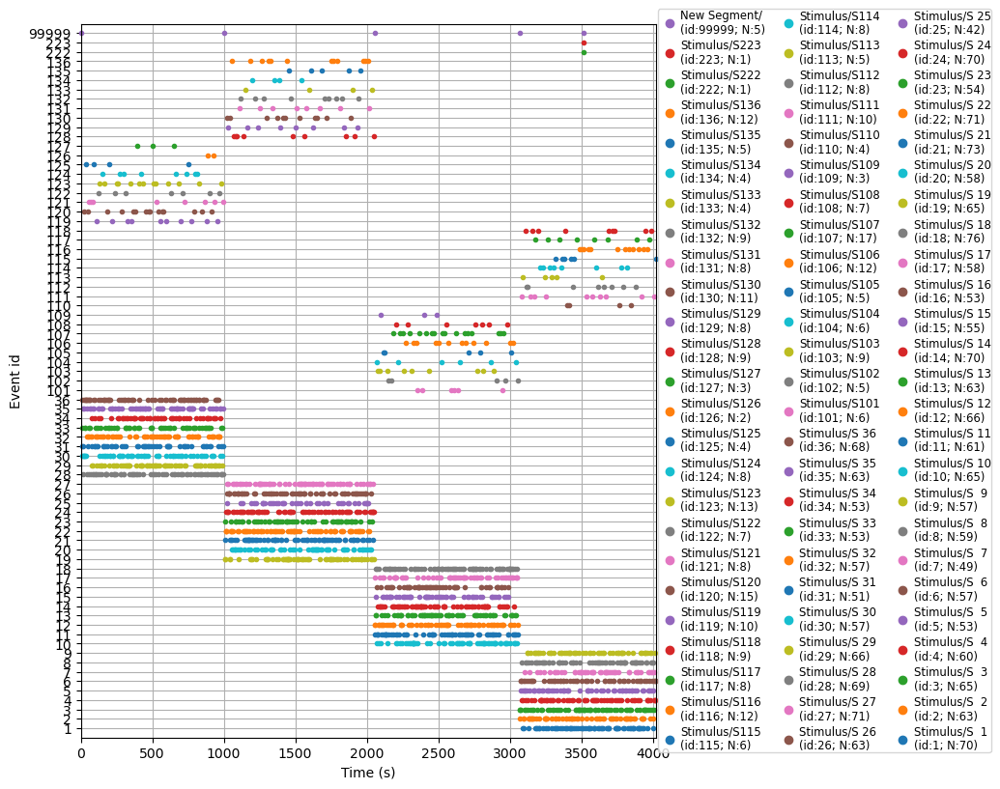

Not setting metadata
2491 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 2491 events and 301 original time points ...
1 bad epochs dropped
Not setting metadata
2490 matching events found
No baseline correction applied
0 projection items activated
combining channels using "mean"


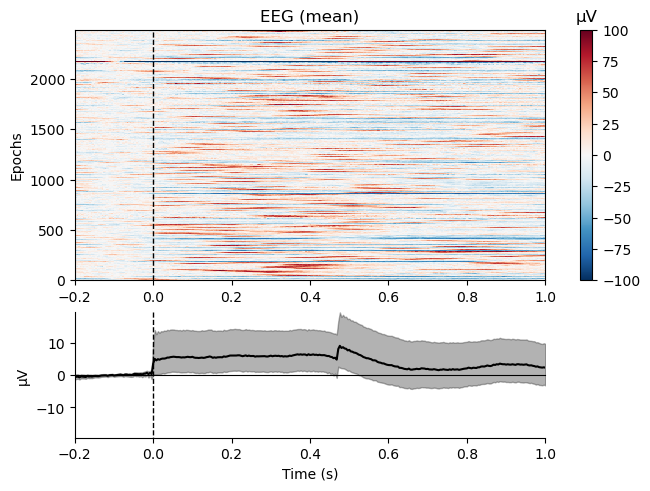

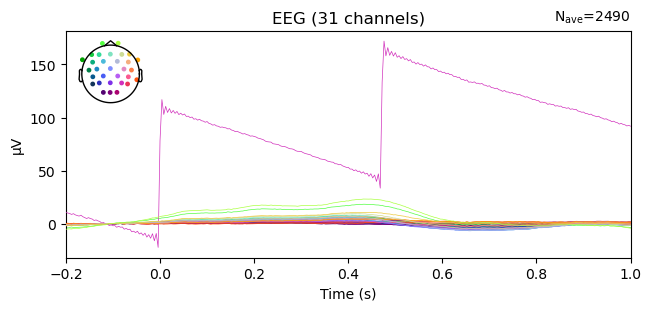

In [73]:
# directory
input_dir = work_dir + '/data_raw/eeg_brainvision/'

# file name
file = 'CUE2024_0075_F0.vhdr'

# read in file
raw = mne.io.read_raw_brainvision(input_dir + file, preload = True)

# drop the audio channel in data
raw.drop_channels(['StimTrak'])

# set montage
raw.set_montage('standard_1020')

# # drop channels
# raw.drop_channels(['P4'])

# check information
print(raw.info)

# filter
raw.filter(l_freq = 0.5, h_freq = None)

# resample
raw.resample(sfreq = 250)

# plot spectrum of raw EEG
raw.compute_psd().plot()
plt.show()

# event distributions
events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
fig = mne.viz.plot_events(
    events_from_annot, event_id=event_dict, sfreq=raw.info["sfreq"], first_samp=raw.first_samp
)


# segmentation for ERP
epochs = mne.Epochs(
    raw,
    events = events_from_annot, event_id = event_dict,
    tmin = -0.2, tmax = 1,
    # apply baseline correction
    # baseline = None,
    # remove epochs that meet the rejection criteria
    reject = None,
    preload = True,
)

# plot epochs
epochs.plot_image(combine="mean", vmin=-100, vmax=100)

# butterfly
epochs.average().plot()
plt.show()

# Save as EEGLAB file
# file = 'CUE2024_0008_VOT_corr_prep_ica.fif'

# # read in file
# raw = mne.io.read_raw_fif(input_dir + file, preload = True)

# # save
# mne.export.export_raw(output_dir + "CUE2024_0008_VOT_corr_prep_ica.set", 
#                       raw, fmt='auto', physical_range='auto', add_ch_type=False, overwrite=True, verbose=None)

## if needed, plot a spectrum for each channel

Fp1
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


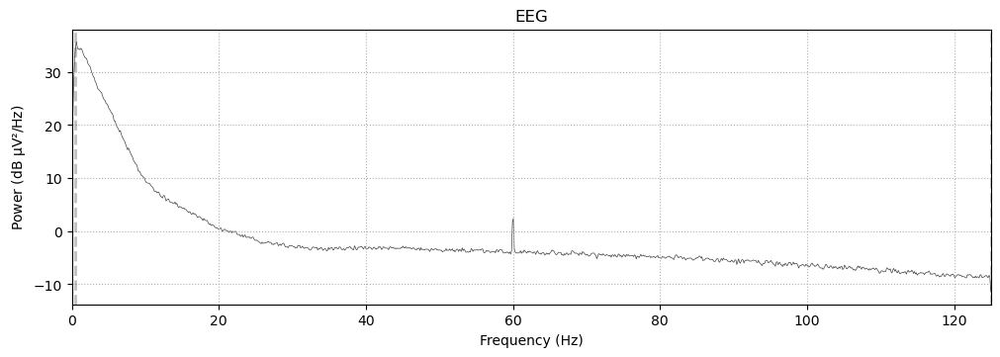

Fz
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


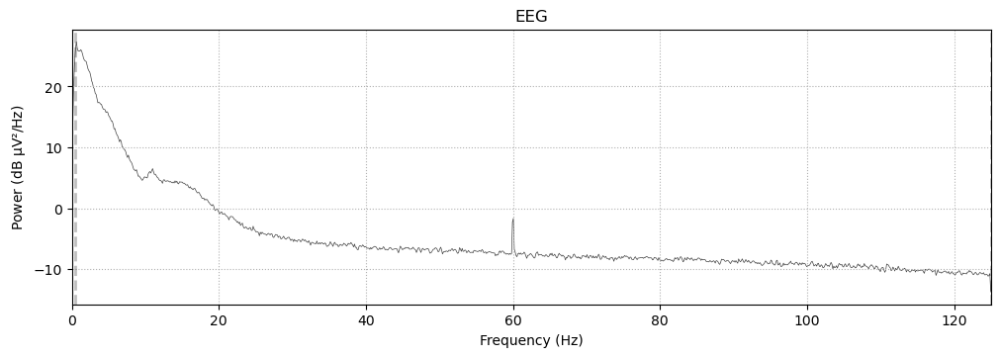

F3
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


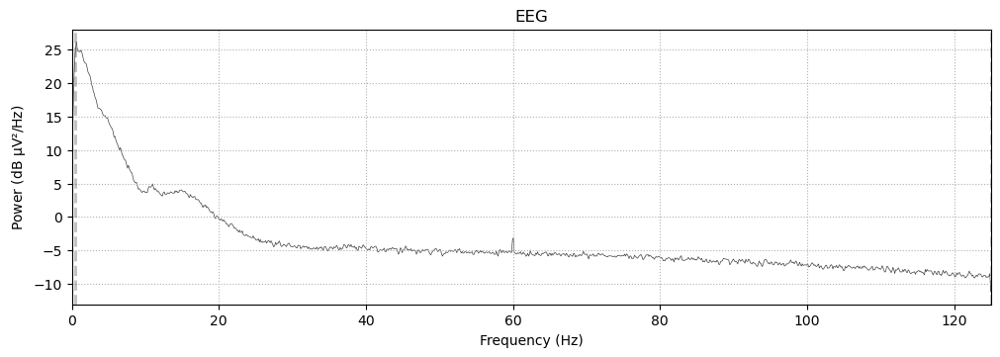

F7
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


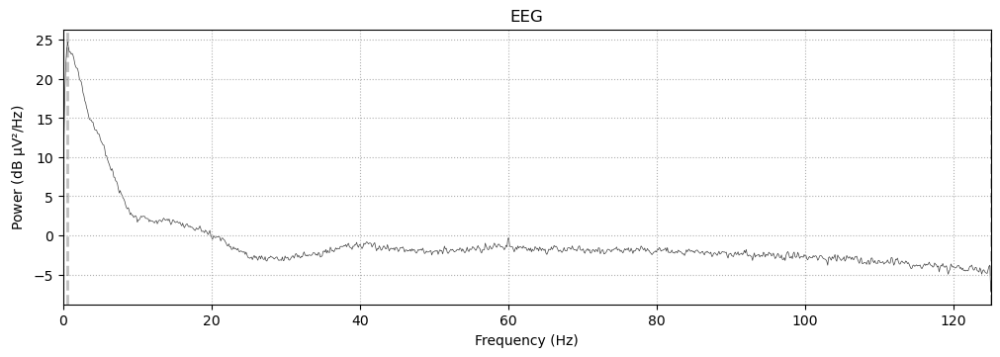

FT9
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


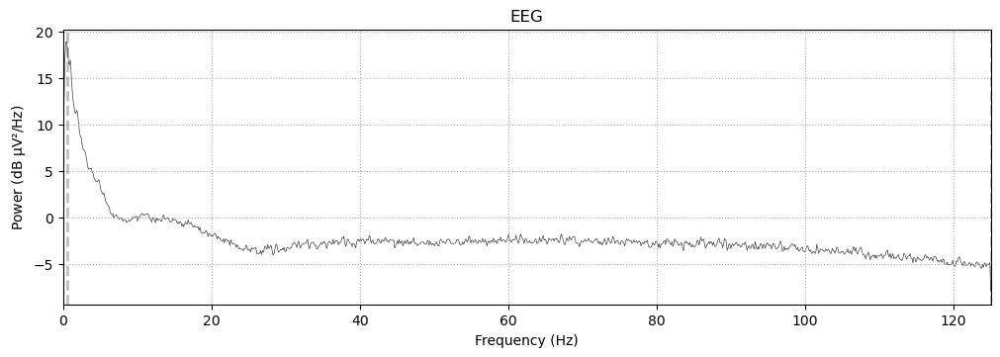

FC5
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


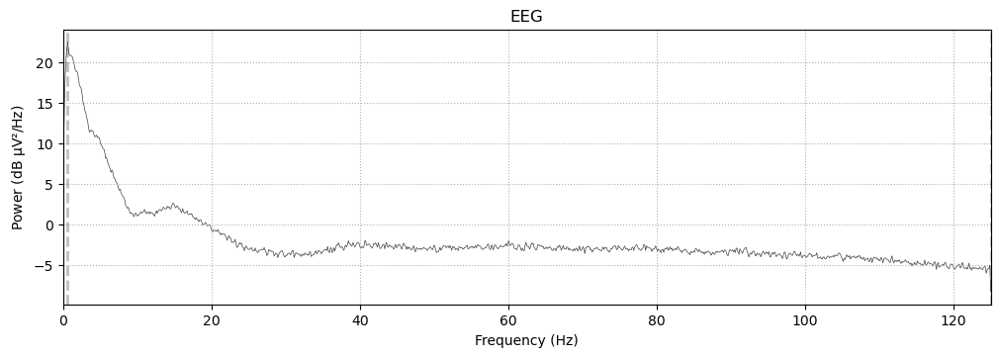

FC1
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


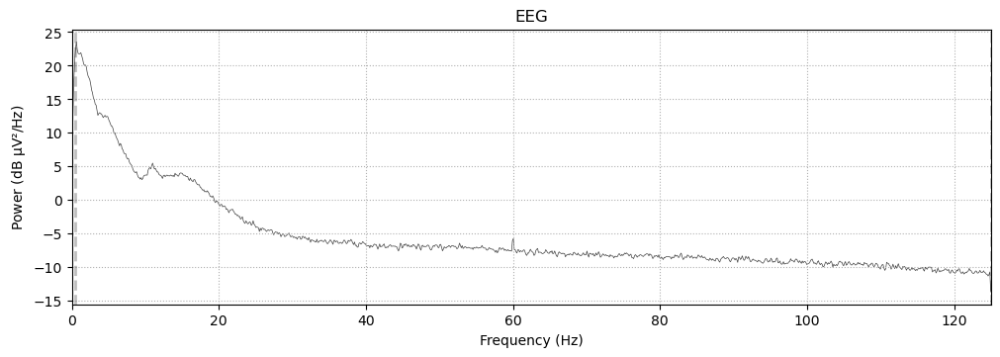

C3
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


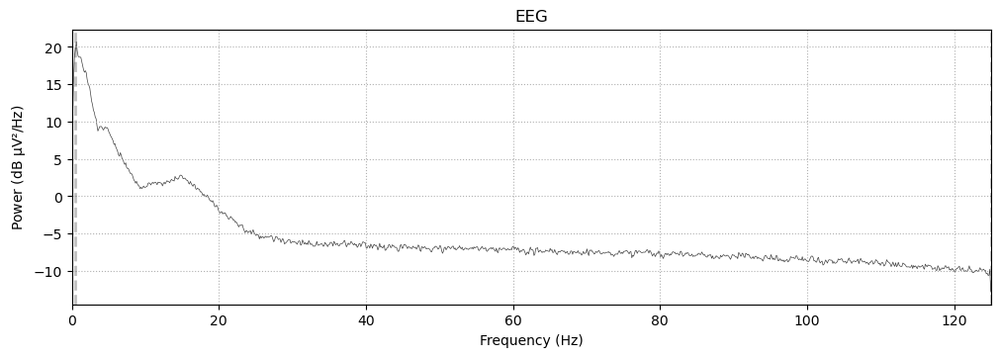

T7
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


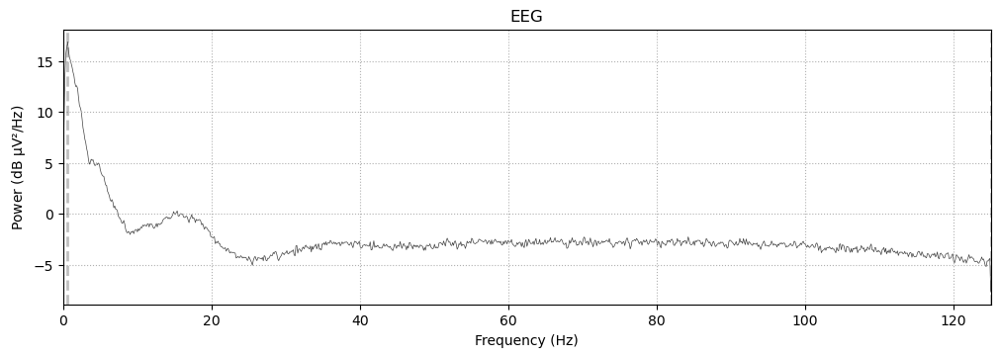

CP5
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


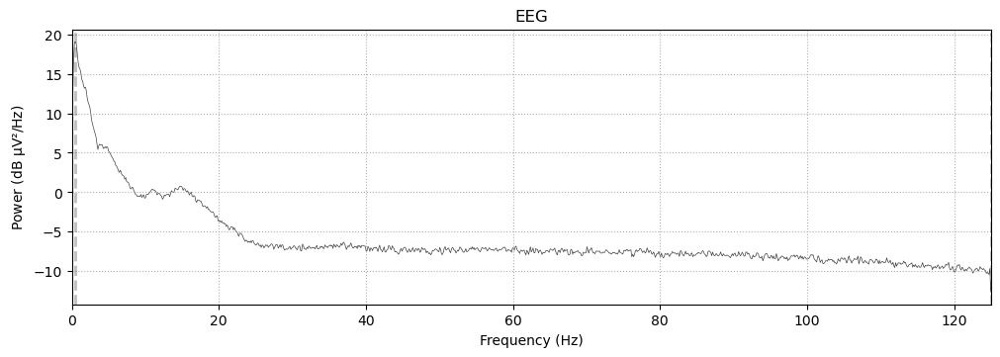

CP1
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


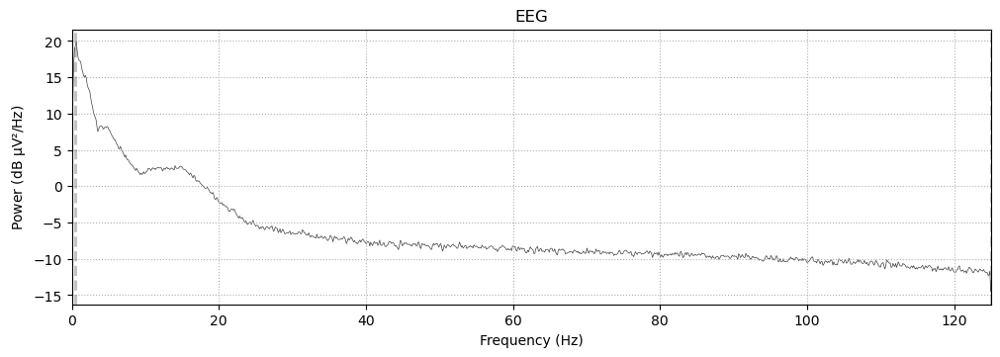

Pz
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


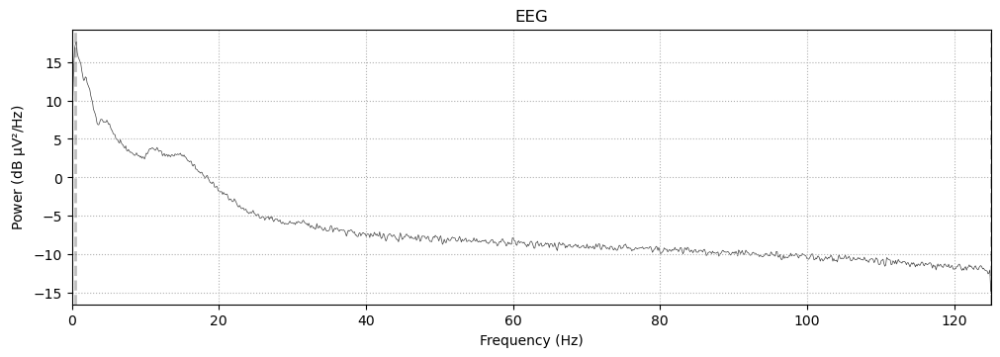

P3
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


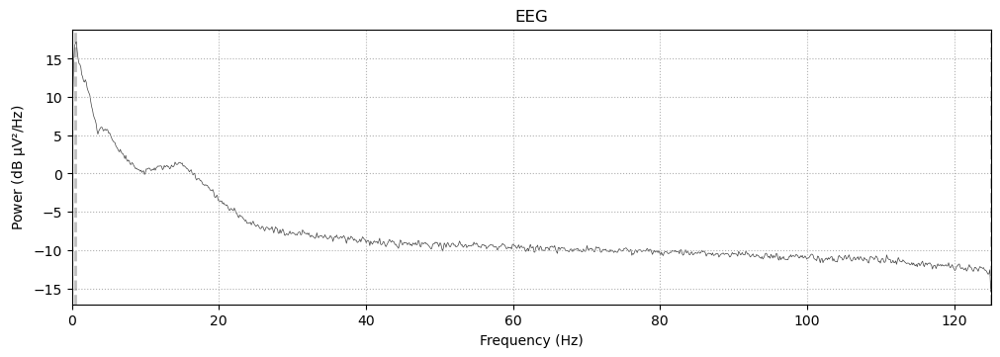

P7
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


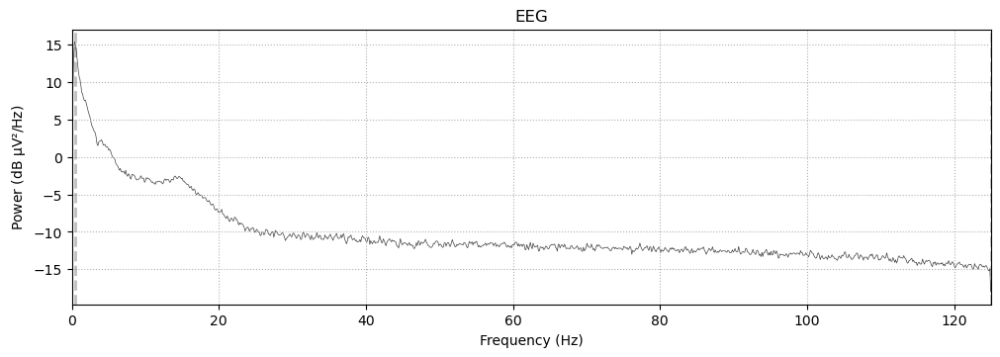

O1
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


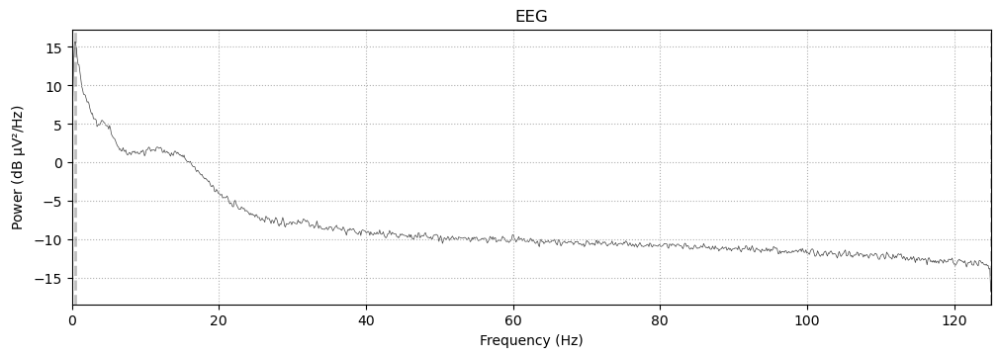

Oz
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


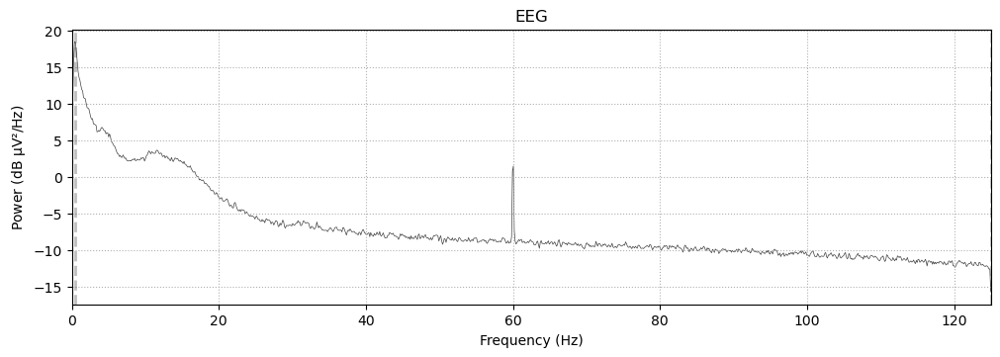

O2
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


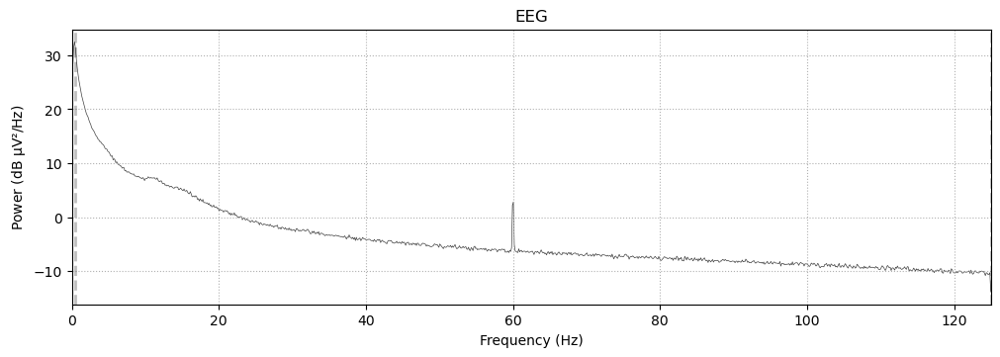

P4
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


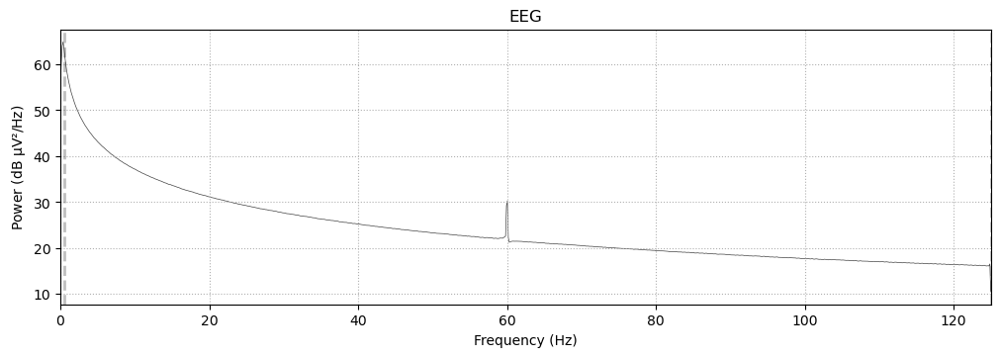

P8
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


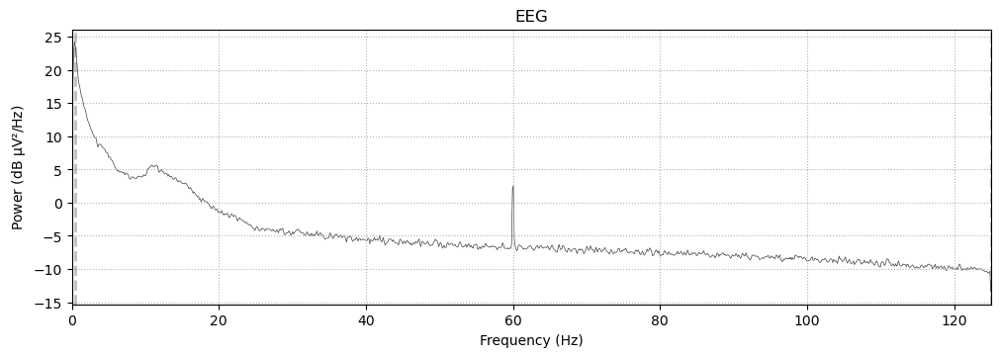

TP10
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


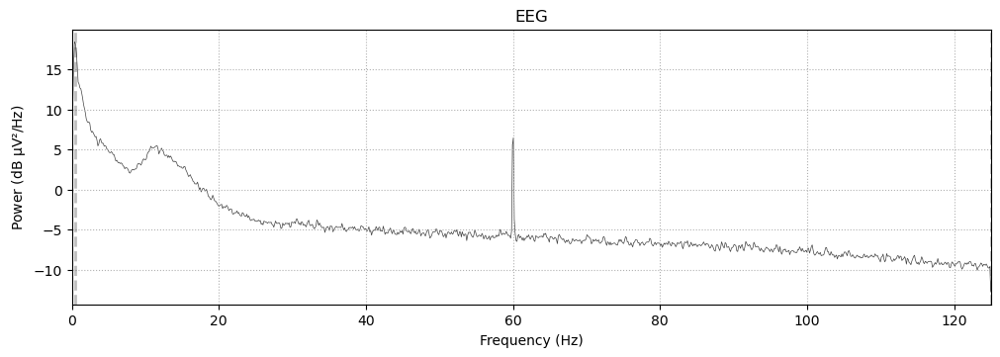

CP6
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


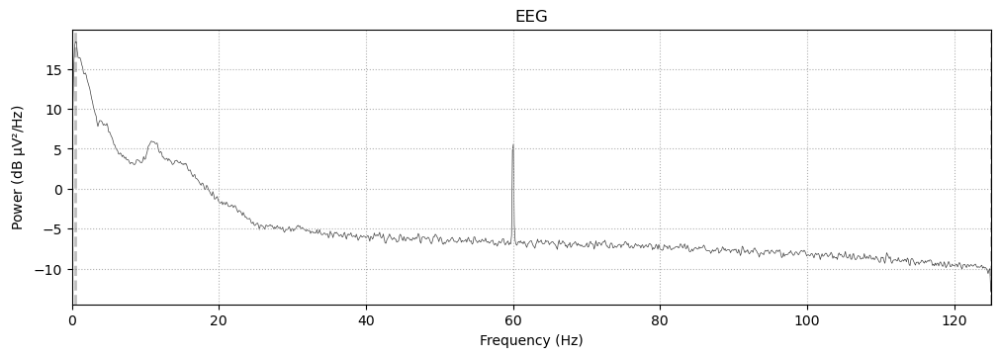

CP2
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


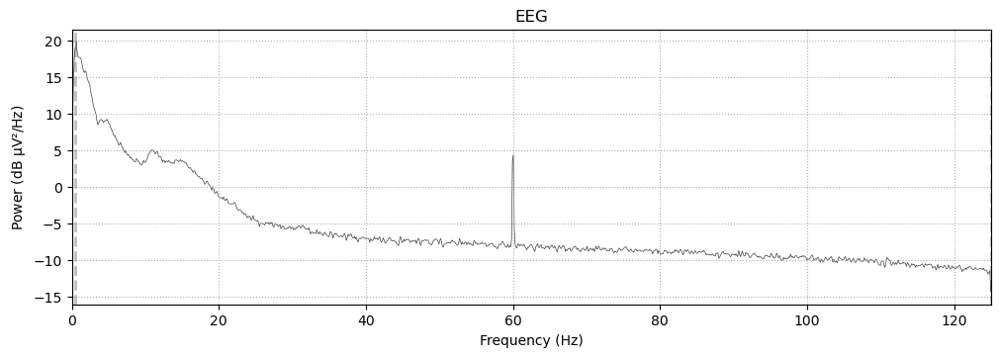

Cz
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


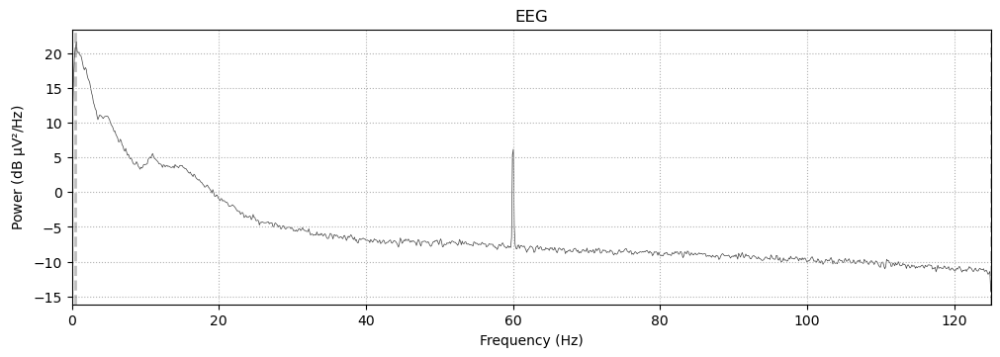

C4
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


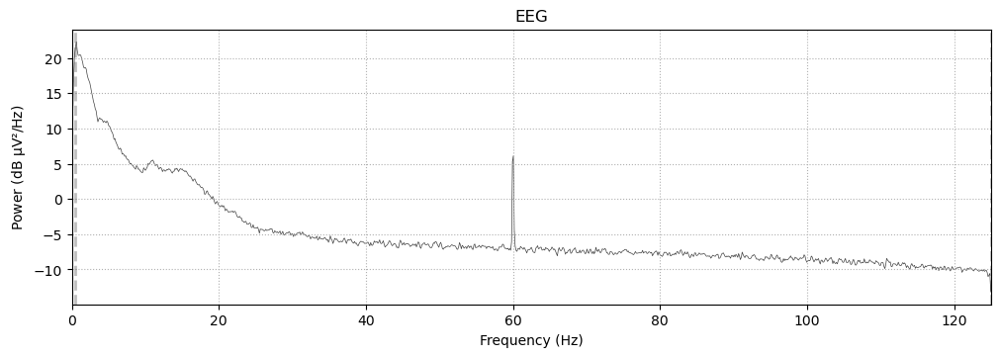

T8
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


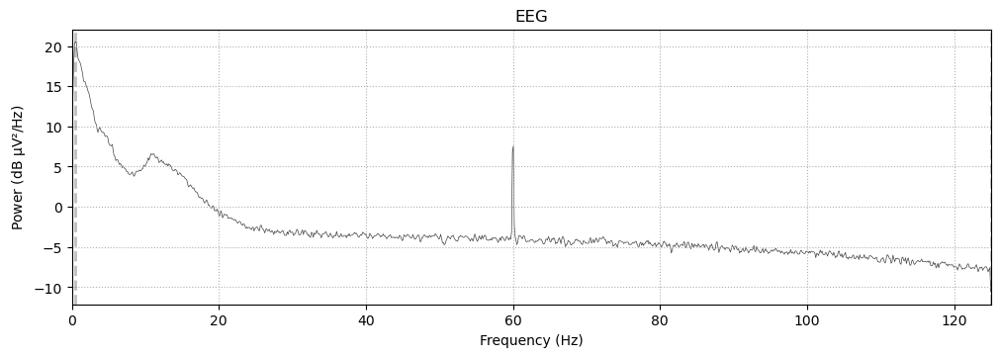

FT10
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


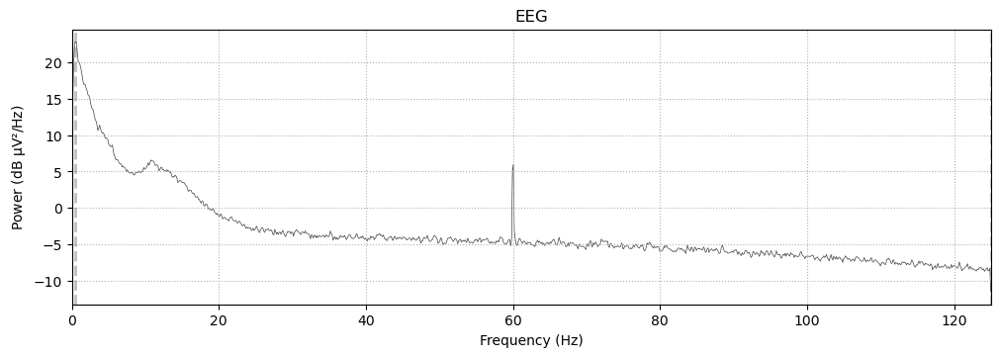

FC6
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


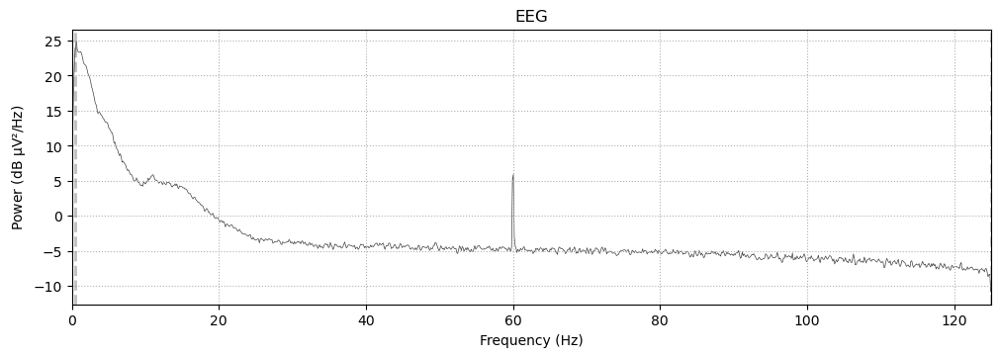

FC2
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


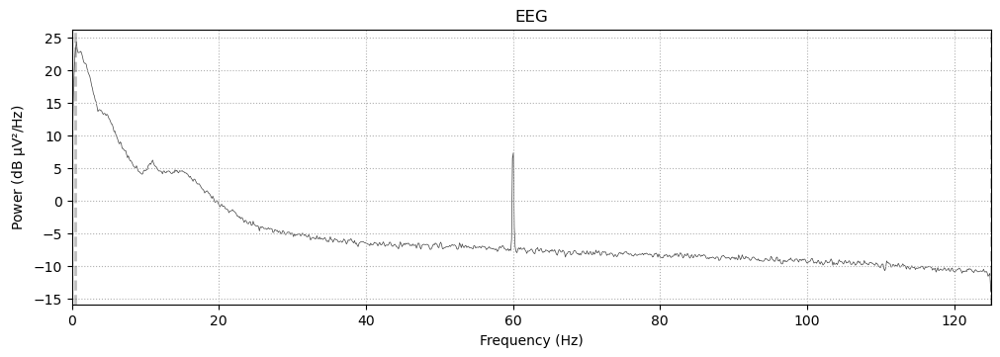

F4
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


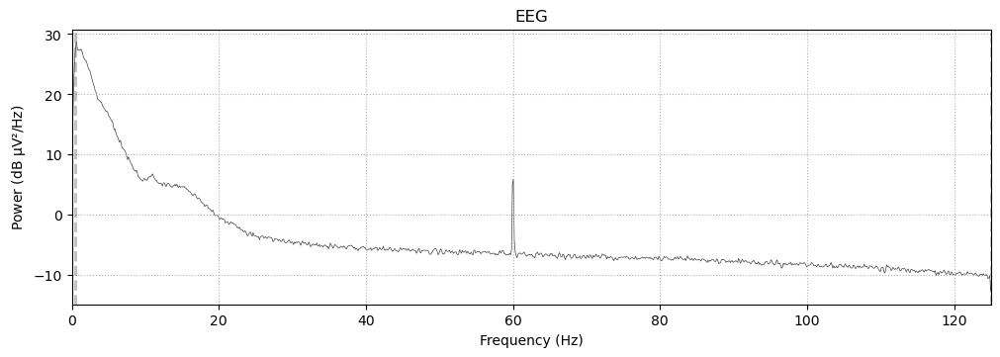

F8
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


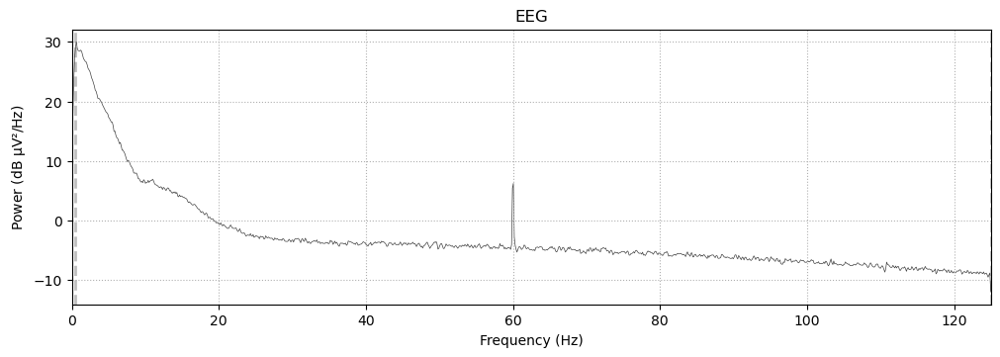

Fp2
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


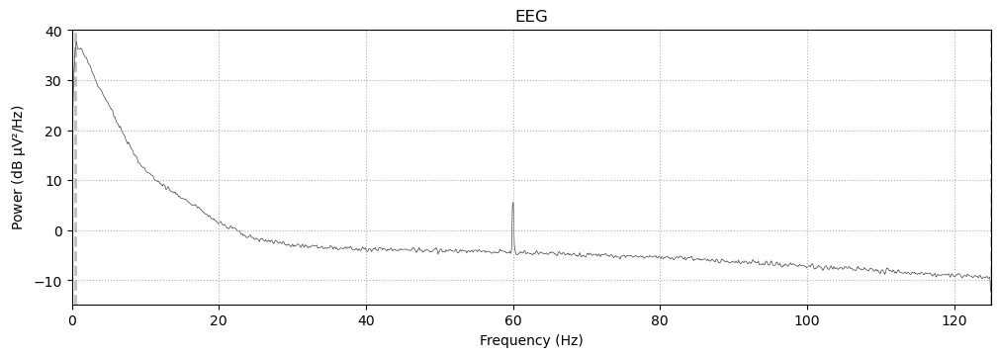

In [28]:
# if needed, plot a spectrum for each channel
for ch_ind in raw.info['ch_names']:
    print('=====================')
    print(ch_ind)
    raw.compute_psd(picks = ch_ind).plot(show=False, amplitude=False)
    plt.show()

# Trigger latency correction
Fixing trigger timing & renaming events

Extracting parameters from /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_raw/eeg_brainvision/CUE2024_0061_VOT.vhdr...
Setting channel info structure...
Reading 0 ... 2081959  =      0.000 ...  4163.918 secs...
Writing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/1_trigger_lag_corrected/CUE2024_0061_VOT_corr.fif


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_20419/1671061709.py:302: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/1_trigger_lag_corrected/CUE2024_0061_VOT_corr.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw.save(output_dir + file.split('.')[0]+ '_corr.fif')


Closing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/1_trigger_lag_corrected/CUE2024_0061_VOT_corr.fif
[done]


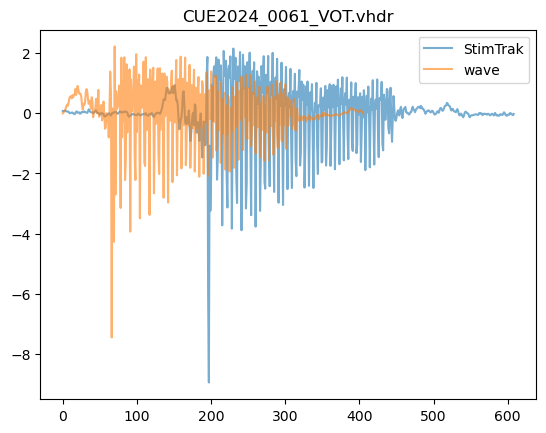

In [6]:
##### parameters #####

# directory
input_dir = work_dir + 'data_raw/eeg_brainvision/'
output_dir = work_dir + 'data_preprocessed/1_trigger_lag_corrected/'
# create a folder if the folder doesn't exist
# os.makedirs(output_dir, exist_ok=True)

# create a dictionary for blocks and block markers
block_dict = {
    'dorsal_highStan_lowDevi': 1000, # standard: dorsal_high; deviant: dorsal_low
    'dorsal_lowStan_highDevi': 2000, # standard: dorsal_low; deviant: dorsal_high
    'glottal_highStan_lowDevi': 3000, # standard: glottal_high; deviant: glottal_low
    'glottal_lowStan_highDevi': 4000, # standard: glottal_low; deviant: glottal_high
}

# exclude participants with missing data
exclude_ppts = [
    '0027', # vot, incomplete eeg recording due to wrong sound library setting
    '0028', # f0, missing block 3 and 4
    '0030', # missing block 3 and 4
    '0034', # missing block 3
    '0040', # f0, missing block 3 and 4
    '0044', # missing half of block 4
    '0046', # f0, missing block 2,3,4
]


# trigger searching window (actual trigger time based on audio - trigger time in the data)
t_left = -0.01
t_right = 0.4 # long latency due to using pygame sound library

#######################################################
#### create a dictionary for trigger codes and descriptions ####
df = pd.read_csv('mapping_vot.txt', delimiter='\t')
VOT_mapping = dict(zip(df['code'], df['description']))

df = pd.read_csv('mapping_f0.txt', delimiter='\t')
F0_mapping = dict(zip(df['code'], df['description']))
#######################################################


##### trigger lag fix #####

# initialize a dictionary to save bad stims
all_bad_stim_dict = {}

# read in eeg data files
all_files = os.listdir(input_dir)

#### for each file, create a dictionary to store each block and the indices of trials of that block  ####
for file in all_files:
    if file.endswith('.vhdr') and (file.split('_')[1] not in exclude_ppts) and (file.split('.')[0]+ '_corr.fif' not in os.listdir(output_dir)):

        # read in vhdr files
        raw = mne.io.read_raw_brainvision(input_dir + file, preload = True)

        # If the aux channel is not named 'StimTrak', change the channel name to 'StimTrak'
        if raw.info['ch_names'][31] != 'StimTrak':
            # change the channel name
            raw.rename_channels({raw.info['ch_names'][31]: 'StimTrak'})
            # specify the audio channel
            raw.set_channel_types({'StimTrak':'misc'})
        
        # extract the info of experiment version
        exp_ver = file.split('.')[0].split('_')[2]

        # extract sampling rate
        eeg_sfreq = raw.info['sfreq']
        
        #############################################################################################
        #### create a dictionary for each stim's standard version and deviant version of markers ####
        
        # intialize a dictionary for triggers
        trigger_dict = {}
        
        # read in trigger_codes file, and create a standard trigger code and a deviant triggre code for each stimulus
        with open(work_dir + 'experiment programs/'+exp_ver+'_eeg/trigger_codes.txt','r') as tf:
            for line in tf:
                # read in the current line
                line = line.replace('\n','')
                # separate fileNames and triggerMarker
                label, marker = line.split('\t')
                # convert trigger markers to integer
                marker = int(marker)
                # create label for stims used as standards
                trigger_dict[marker] = label + '-s'
                # add 100 for deviant marker
                marker_deviant = marker + 100
                # create label for stims used as deviants
                trigger_dict[marker_deviant] = label + '-d'
        #############################################################################################

        ########################
        #### get audio data ####
        
        # initialize dictionaries
        audio = {}
        lengths = {}
        
        # del trigger_dict[99999]
        # for each trigger code and label in the trigger dictionary
        for marker,label in trigger_dict.items():
            # extract file name, up to the -2 character of the label
            file_name = label[:-2]
            # if not already in audio dictionary, get the info of the audio file
            if file_name not in audio:
                # get sample rate and data of the audio file
                sampleRate, data = wavfile.read(work_dir + 'experiment programs/'+exp_ver+'_eeg/stimuli/{}.wav'.format(file_name))
                # calculate sound file length
                lengths[file_name] = len(data)/sampleRate
                # reduce the sampling rate of the audio file by the factor of int(sampleRate/eeg_sfreq)
                data_downsampled = signal.decimate(data, int(sampleRate/eeg_sfreq), ftype='fir')
                # add info the audio dictionary
                audio[file_name] = data_downsampled
        ########################

        ##################################################################
        #### recode trigger marker to reflect condition and stim info ####

        # for each stimulus, mark the block info
        events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
        # remove the New Segment marker (which has a trigger value of 99999) and pause marker (222) and continue marker (223)
        events_from_annot = events_from_annot[events_from_annot[:, 2] < 200]
        
        # initialize the train for each standards+deviant sequence
        train = np.array([]).astype(int)
        
        all_block = {}
        isStandard = True # whether the standard in a train has been noted
        
        # loop over each trigger
        for i in range(events_from_annot.shape[0]):

            # get trigger value
            trigger_value = events_from_annot[i,2]
            
            # add the current token to the train
            train = np.append(train,i)

            # if the trigger value is smaller than 100 and the standard toggle is true
            if (trigger_value<100) & isStandard:
                # split the file name
                trigger_splitted = trigger_dict[trigger_value].split('_')
                # get the standard category name
                block = trigger_splitted[1] + '_' + trigger_splitted[2] + 'Stan'
                # toggle standard
                isStandard = False

            # if the trigger value is over 100
            elif trigger_value>100:
                # split the file name
                trigger_splitted = trigger_dict[trigger_value].split('_')
                # append the deviant stim category 
                block = block + '_' + trigger_splitted[2] + 'Devi'

                # if the block is not present in all block
                if block not in all_block:
                    # add the new block and the token idx
                    all_block[block] = train[2:] # [2:] to exclude the first 2 standards
                else:
                    # add the token idx to the existing block
                    all_block[block] = np.concatenate([all_block[block],train[2:]],axis = None)

                # reset train
                train = np.array([]).astype(int)

                # toggle standard note
                isStandard = True
        
        # loop over each block and its trigger index
        for k,v in all_block.items():
            # recode the trigger value to reflect block and stim category
            events_from_annot[tuple(v),2] += block_dict[k]

        # generate new events
        events_from_annot = events_from_annot[events_from_annot[:,2]>1000]
        ##################################################################

        
        ######################################################
        #### cross correction to detect the trigger delay ####
        
        # initialize delay list
        delays = np.array([])
        # initialize bad stim list
        bad_stim = []
        corr_results = []
        
        # loop over each event
        for i in range(events_from_annot.shape[0]):
        
            # get current event info [time, duration, annotation]
            event = events_from_annot[i]
            # get the onset latency (s) of the event
            time = event[0]/eeg_sfreq
            # get the file name of the event
            name = trigger_dict[event[2]%100].split('-')[0]
            # get the data from the sound channel
            audio_eeg = raw.get_data(
                picks = ['StimTrak'],
                tmin = time + t_left,
                tmax = time + lengths[name] + t_right,
            )[0]
            # actual stimulus
            audio_stim = audio[name]
            # Z-score normalization (subtract mean, divide by std)
            audio_eeg = (audio_eeg - np.mean(audio_eeg)) / np.std(audio_eeg)
            audio_stim = (audio_stim - np.mean(audio_stim)) / np.std(audio_stim)
            
            # cross-correlation
            corr = signal.correlate(audio_eeg, audio_stim, mode='full')
            # Normalize cross-correlation
            corr = corr / (np.linalg.norm(audio_eeg) * np.linalg.norm(audio_stim))
            # Find peak correlation value
            max_corr = np.max(corr)            
            
            # if the maximum correction (sum of products) is less than a threshold (empirical threshold, 0.5 is generally good)
            if max_corr < 0.5:
                # mark the stim bad
                bad_stim.append(i)

            # append the maximum correlation
            corr_results.append(max_corr)

            
            # the lags for cross-correlation
            lags = signal.correlation_lags(
                audio_eeg.size,
                audio_stim.size,
                mode="full")
            # get the lag of the maximum cross-correlation
            lag = lags[np.argmax(corr)] + t_left*eeg_sfreq
            
            # save the lag for non-starting events
            delays = np.append(delays,lag)
        ######################################################

        ##################################################################################################
        #### plot the wave from the stim track and the eeg channel of the token with the minimum corr ####
        
        min_corr = np.argmin(corr_results)
        # get current event info [time, duration, annotation]
        event = events_from_annot[min_corr]
        # get the onset latency (s) of the event
        time = event[0]/eeg_sfreq
        # get the file name of the event
        name = trigger_dict[event[2]%100].split('-')[0]
        # get the data from the sound channel
        audio_eeg = raw.get_data(
            picks = ['StimTrak'],
            tmin = time + t_left,
            tmax = time + lengths[name] + t_right,
        )[0]
        # actual stimulus
        audio_stim = audio[name]
        # Z-score normalization (subtract mean, divide by std)
        audio_eeg = (audio_eeg - np.mean(audio_eeg)) / np.std(audio_eeg)
        audio_stim = (audio_stim - np.mean(audio_stim)) / np.std(audio_stim)
        # plot
        fig, ax = plt.subplots()
        ax.plot(audio_eeg, label = 'StimTrak', alpha = 0.6)
        ax.plot(audio_stim, label = 'wave', alpha = 0.6)
        ax.set_title(file)
        ax.legend()
        fig.savefig(output_dir + file.split('.')[0] + "_minCor.png", dpi=300, bbox_inches='tight')
        ##################################################################################################

        
        ################################################
        #### correct for trigger lag and save files ####

        # add number of bad stim info
        all_bad_stim_dict[file] = len(bad_stim)
        
        # remove items associated with bad stims from the event list
        events_from_annot = np.delete(events_from_annot, bad_stim, 0)
        
        # remove items associated with bad stims from the delay list
        delays = np.delete(delays, bad_stim, 0)
        
        # add delay back to the onset latency of each event
        events_from_annot[:,0] = events_from_annot[:,0] + delays
        
        # convert individual event marker to conditions
        # events_from_annot[:,2] = events_from_annot[:,2] - events_from_annot[:,2]%100
        
        # create annotations
        annot_from_events = mne.annotations_from_events(
            events = events_from_annot,
            event_desc = eval(exp_ver + '_mapping'),
            sfreq = eeg_sfreq
        )
        
        # set annotations
        raw.set_annotations(annot_from_events)
        
        # drop the audio channel in data
        raw.drop_channels(['StimTrak'])
        
        # save as a file-into-file data
        raw.save(output_dir + file.split('.')[0]+ '_corr.fif')

        # save lag data
        np.savetxt(output_dir + file.replace('.vhdr', '_delays.txt'), delays, fmt='%i')
        ################################################


# save the number of bad stims of all participant
with open(output_dir + 'bad_stim.txt', 'a') as f:
    for key, value in all_bad_stim_dict.items():
        if value > 0:
            f.write(key + '\t' + str(value) + '\n')

# Bad channel correction
- filtering
- resampling
- remove line noise
- bad channel detection & repairing
- add back reference channel TP9

In [36]:
#### parameters ####

# set directory
input_dir = work_dir + 'data_preprocessed/1_trigger_lag_corrected/'
# output_dir = work_dir + 'data_preprocessed/2_bad_channel_corrected/'
output_dir = work_dir + 'eeg_preprocessed_2025-11-13/2_bad_channel_corrected/0.5hf - lof/FPasEEG/'

# filter cutoff frequencies (low/high)
f_low = 0.5

# resampling frequency
f_res = 250

# line frequency
line_freq = 60

# exclude participants
exclude_ppts = [
    '0037' # has empty cell
]

#####################################################
#### filtering, resampling, bad channel detection/interpoloation ####
#####################################################

# get all file namesin the folder
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)


for file in all_input:
    if file.endswith("corr.fif") and (file.split('_')[1] not in exclude_ppts) and (file.split('.')[0]+ '_prep.fif' not in all_output):

        # select participants
        if file.split('_')[2] + '_' + file.split('_')[1] not in include_ppts:
            continue
            
        # read in file
        raw = mne.io.read_raw_fif(input_dir + file, preload=True)

        # set channel type
        raw.set_channel_types({'Fp1':'eog', 'Fp2':'eog'})

        # read in channel location info
        raw.set_montage(montage)

        # filter
        raw.filter(l_freq = f_low, h_freq = None)
        
        #### cut off the beginning and ending part ####
        
        # # get the onset of the first and the last event ####
        # events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')

        # # define the beginning time (in seconds)
        # crop_start = events_from_annot[0][0]/raw.info['sfreq'] - 10
        # # define the ending time (in seconds)
        # crop_end = events_from_annot[-1][0]/raw.info['sfreq'] + 10
        # # crop the data
        # raw.crop(
        #     tmin=max(crop_start, raw.times[0]), 
        #     tmax=min(crop_end, raw.times[-1])
        # )
        
        # resample
        raw.resample(sfreq = f_res)
        
        ####  bad channel detection using lof ####
        bad_chans = mne.preprocessing.find_bad_channels_lof(raw)

        # export a txt file for the bad channel info
        with open(output_dir + 'bad_channels.txt', 'a+') as f:
            _ =f.write(
                # file + '\t' + "- Bad channels original: {}".format(bad_chans) + '\n'
                file + '\t' + str(bad_chans) + '\n'
            )

        # mark bad channels and interpolation
        raw.info['bads'] = bad_chans
        # spline interpolating remaining bad channels if any
        raw.interpolate_bads()

        # # add back the reference channel
        # raw = mne.add_reference_channels(raw,'TP9')

        # # set Fp1 and Fp2 back to eeg
        # raw.set_channel_types({'Fp1':'eeg', 'Fp2':'eeg'})

        # # add the channel loc info (for the newly added reference channel)
        # raw.set_montage(montage)
        
        # save
        raw.save(output_dir + file.split('.')[0]+ '_prep.fif')

Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/1_trigger_lag_corrected/CUE2024_0029_VOT_corr.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/4133639204.py:39: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/1_trigger_lag_corrected/CUE2024_0029_VOT_corr.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload=True)


Isotrak not found
    Range : 0 ... 2138489 =      0.000 ...  4276.978 secs
Ready.
Reading 0 ... 2138489  =      0.000 ...  4276.978 secs...
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 0.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Filter length: 3301 samples (6.602 s)

LOF: Detected bad channel(s): ['F3', 'P4']
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 95.5 mm
Computing interpolation matrix from 29 sensor positions
Interpolating 2 sensors
Writing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/2_bad_channel_corrected/0.5hf

/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/4133639204.py:93: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/2_bad_channel_corrected/0.5hf - lof/FPasEEG/CUE2024_0029_VOT_corr_prep.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw.save(output_dir + file.split('.')[0]+ '_prep.fif')


Closing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/2_bad_channel_corrected/0.5hf - lof/FPasEEG/CUE2024_0029_VOT_corr_prep.fif
[done]
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/1_trigger_lag_corrected/CUE2024_0019_VOT_corr.fif...


...

Closing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/2_bad_channel_corrected/0.5hf - lof/FPasEEG/CUE2024_0049_VOT_corr_prep.fif
[done]
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/1_trigger_lag_corrected/CUE2024_0039_VOT_corr.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/4133639204.py:39: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/1_trigger_lag_corrected/CUE2024_0039_VOT_corr.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload=True)


Isotrak not found
    Range : 0 ... 2065279 =      0.000 ...  4130.558 secs
Ready.
Reading 0 ... 2065279  =      0.000 ...  4130.558 secs...
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 0.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Filter length: 3301 samples (6.602 s)

LOF: Detected bad channel(s): ['Fp1', 'Fp2']
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 95.5 mm
Computing interpolation matrix from 29 sensor positions
Interpolating 2 sensors
Writing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/2_bad_channel_corrected/0.5

/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/4133639204.py:93: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/2_bad_channel_corrected/0.5hf - lof/FPasEEG/CUE2024_0039_VOT_corr_prep.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw.save(output_dir + file.split('.')[0]+ '_prep.fif')


Closing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/2_bad_channel_corrected/0.5hf - lof/FPasEEG/CUE2024_0039_VOT_corr_prep.fif
[done]


## Data quality check

Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/2_bad_channel_corrected/0.5hf - lof/CUE2024_0006_VOT_corr_prep.fif...
    Range : 0 ... 1043284 =      0.000 ...  4173.136 secs
Ready.


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/4280700388.py:8: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/2_bad_channel_corrected/0.5hf - lof/CUE2024_0006_VOT_corr_prep.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


Reading 0 ... 1043284  =      0.000 ...  4173.136 secs...
<Info | 10 non-empty values
 bads: []
 ch_names: Fp1, Fz, F3, F7, FT9, FC5, FC1, C3, T7, CP5, CP1, Pz, P3, P7, ...
 chs: 2 EOG, 29 EEG
 custom_ref_applied: False
 dig: 32 items (3 Cardinal, 29 EEG)
 file_id: 4 items (dict)
 highpass: 0.5 Hz
 lowpass: 125.0 Hz
 meas_date: 2024-10-09 11:40:20 UTC
 meas_id: 4 items (dict)
 nchan: 31
 projs: []
 sfreq: 250.0 Hz
>
Effective window size : 8.192 (s)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/4280700388.py:17: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp1', 'Fp2']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Plotting power spectral density (dB=True).


/opt/anaconda3/lib/python3.12/site-packages/mne/viz/utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


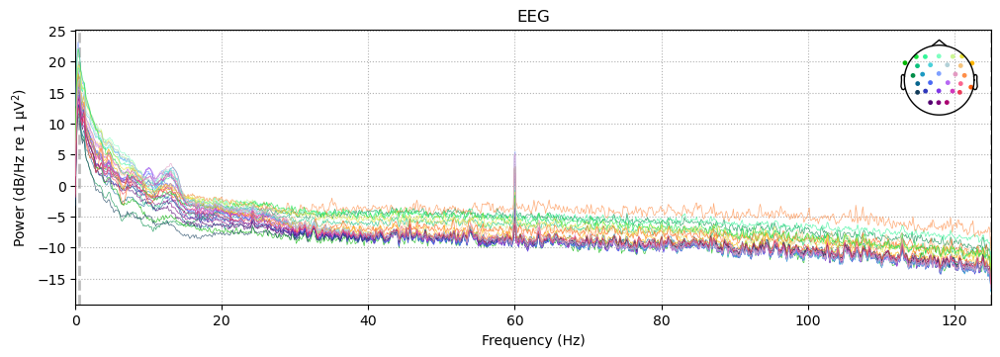

Not setting metadata
1951 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1951 events and 301 original time points ...
0 bad epochs dropped
Not setting metadata
1951 matching events found
No baseline correction applied
0 projection items activated
combining channels using "mean"


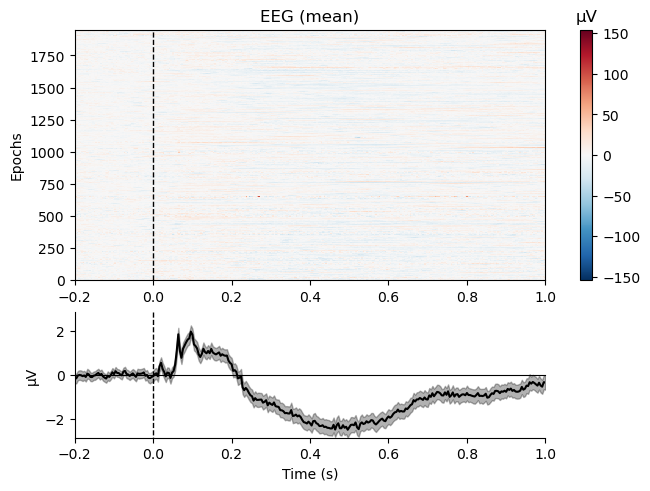

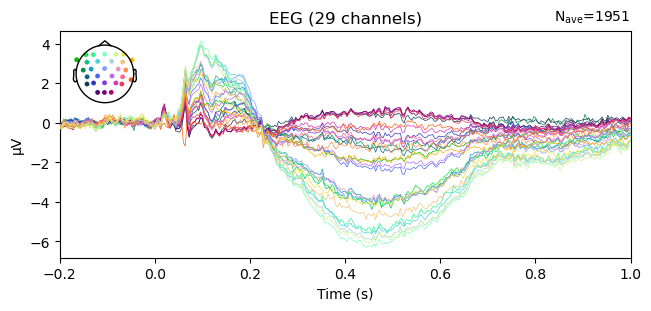

In [34]:
# directory
input_dir = work_dir + 'eeg_preprocessed_2025-11-13/2_bad_channel_corrected/0.5hf - lof/'

# file name
file = 'CUE2024_0006_VOT_corr_prep.fif'

# read in file
raw = mne.io.read_raw_fif(input_dir + file, preload = True)

# drop channels
# raw.drop_channels(['TP9'])

# set Fp1 and Fp2 back to eeg
# raw.set_channel_types({'Fp1':'eeg', 'Fp2':'eeg'})

# add the channel loc info (for the newly added reference channel)
raw.set_montage(montage)

# check information
print(raw.info)

# plot spectrum of raw EEG
raw.compute_psd().plot()
plt.show()

# event distributions
events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')

# segmentation for ERP
epochs = mne.Epochs(
    raw,
    events = events_from_annot, event_id = event_dict,
    tmin = -0.2, tmax = 1,
    # apply baseline correction
    # baseline = None,
    # remove epochs that meet the rejection criteria
    reject = None,
    preload = True,
)

# plot epochs
epochs.plot_image(combine="mean")

# butterfly
epochs.average().plot()
plt.show()

## if needed, plot a spectrum for each channel

Fz
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


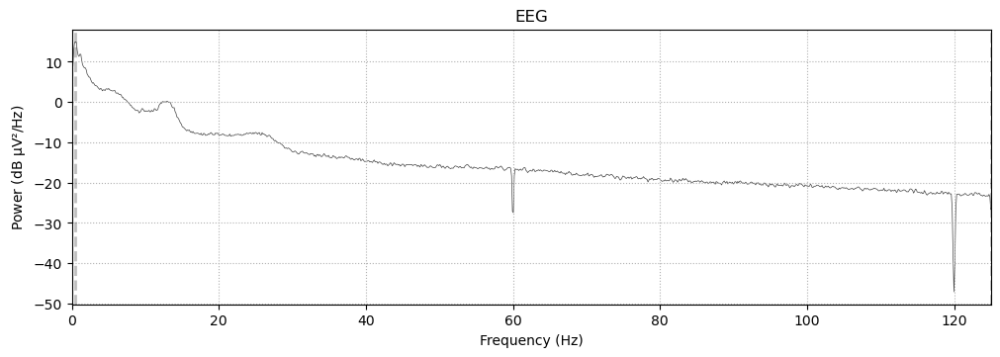

F3
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


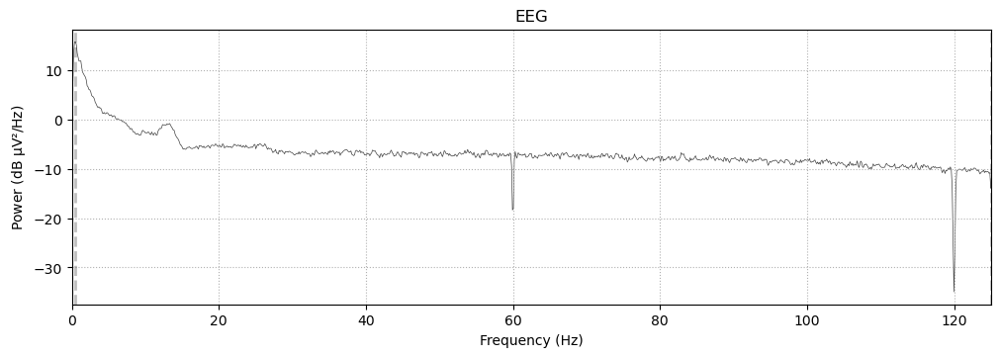

F7
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


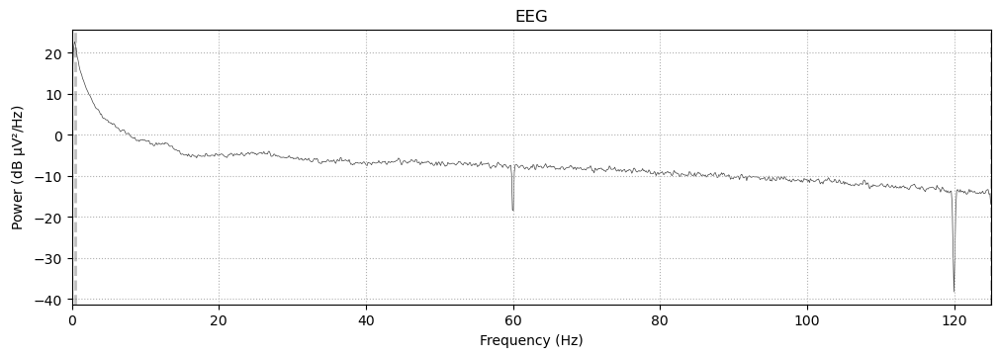

FT9
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


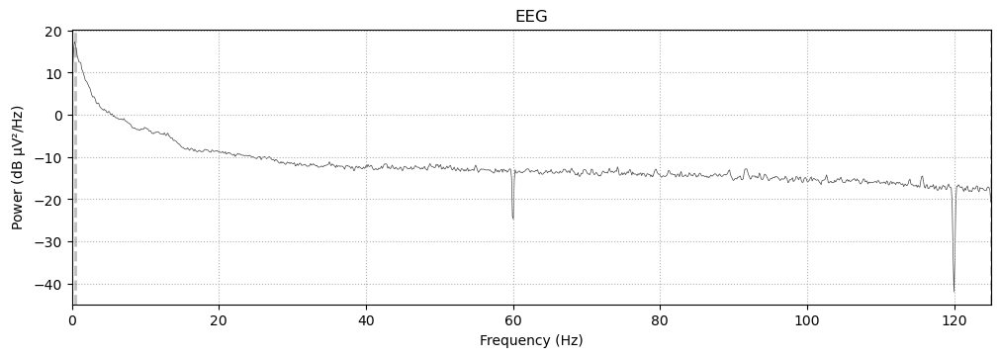

FC5
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


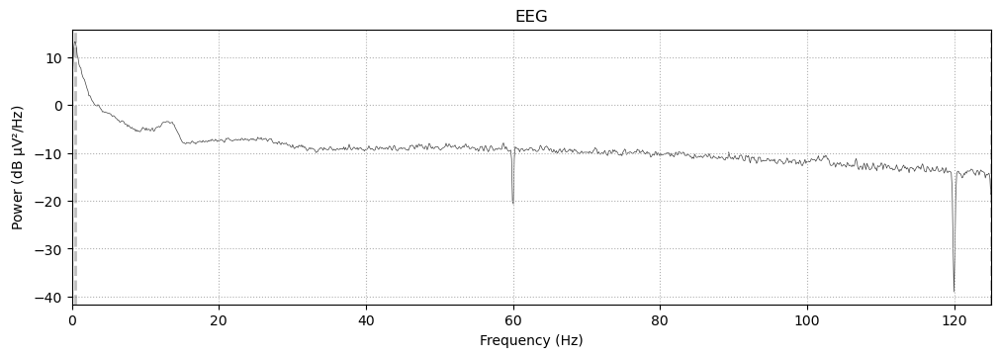

FC1
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


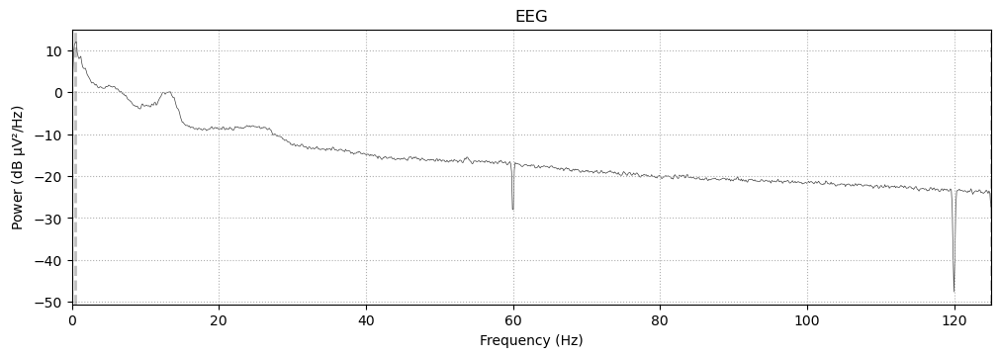

C3
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


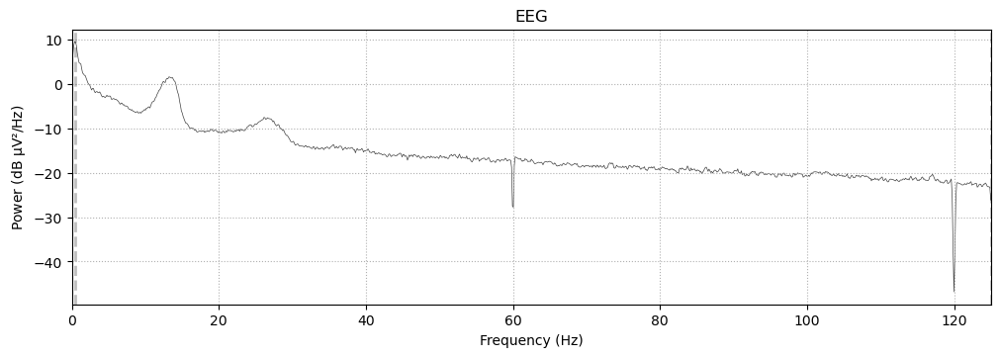

T7
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


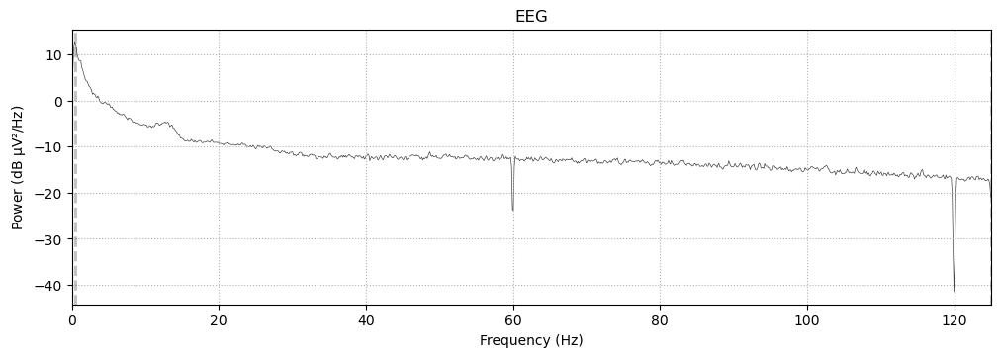

CP5
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


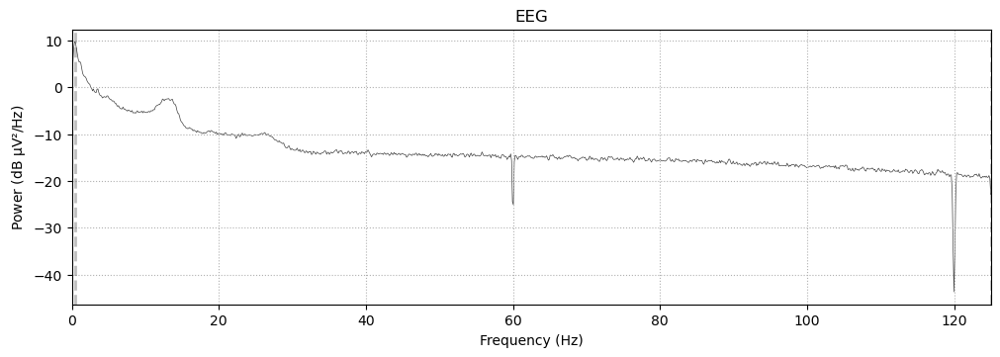

CP1
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


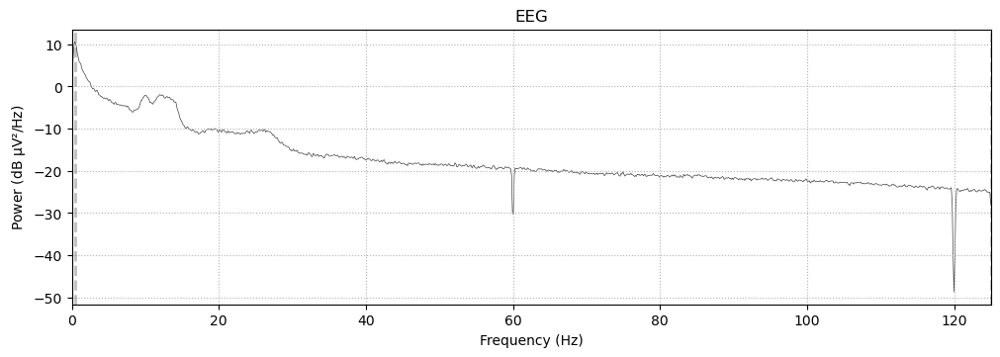

Pz
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


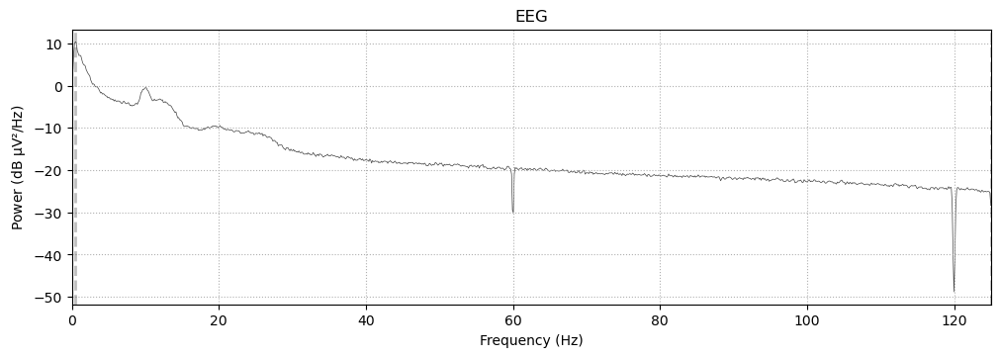

P3
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


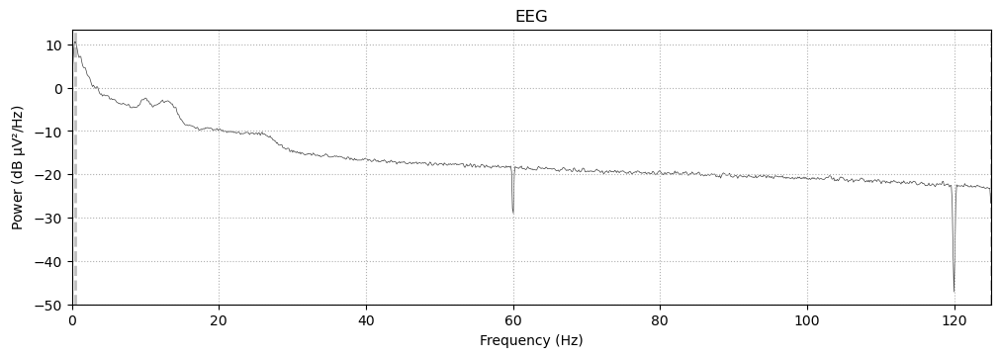

P7
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


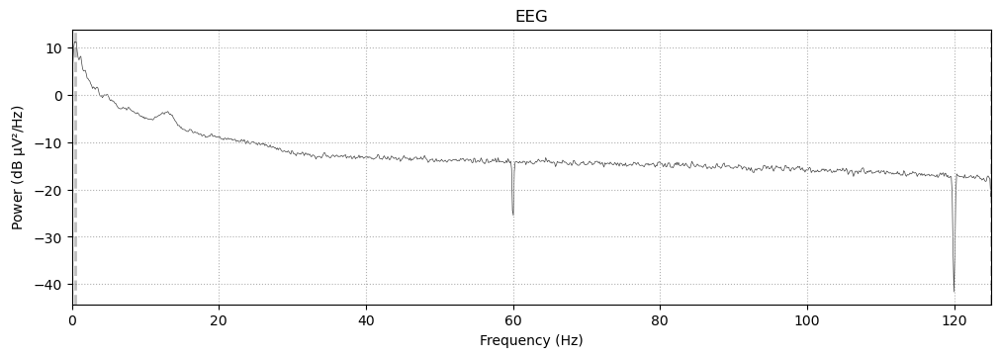

O1
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


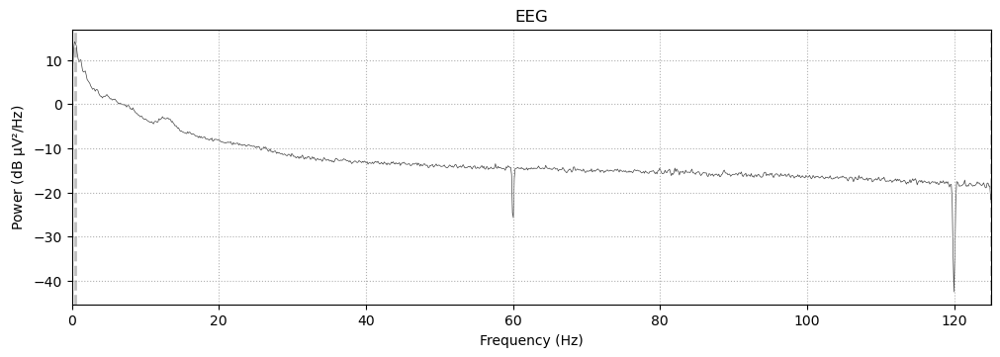

Oz
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


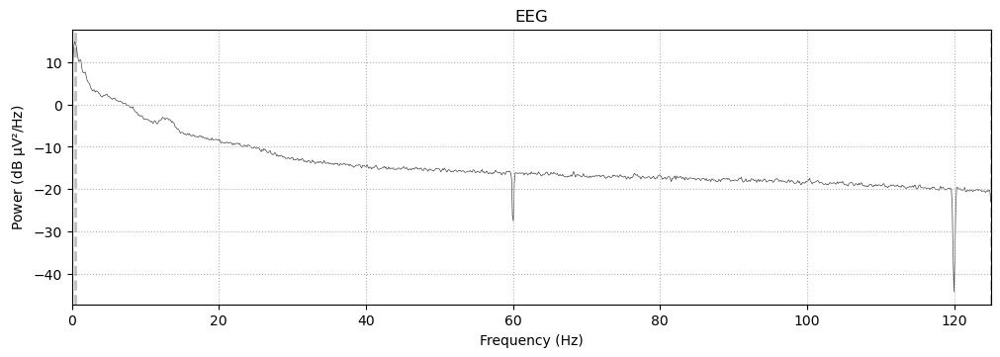

O2
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


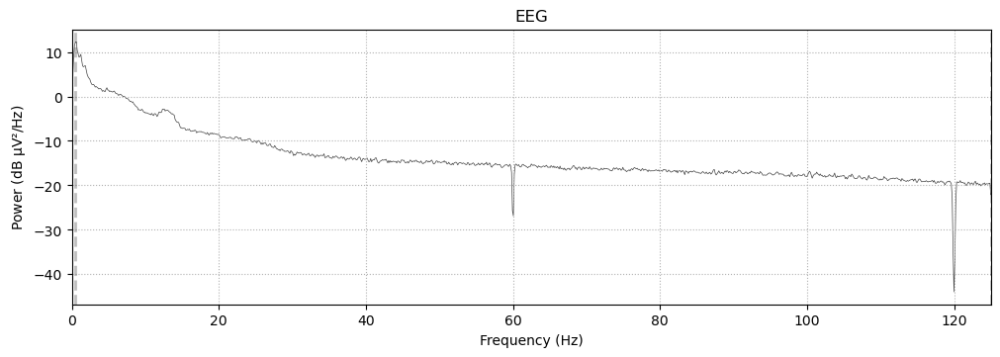

P4
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


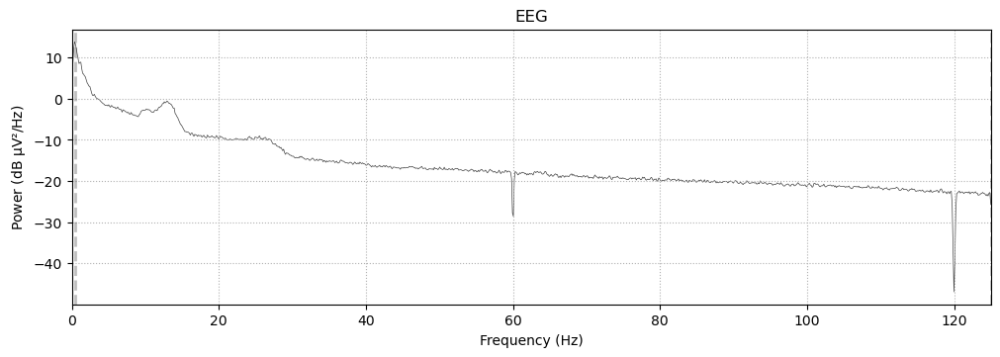

P8
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


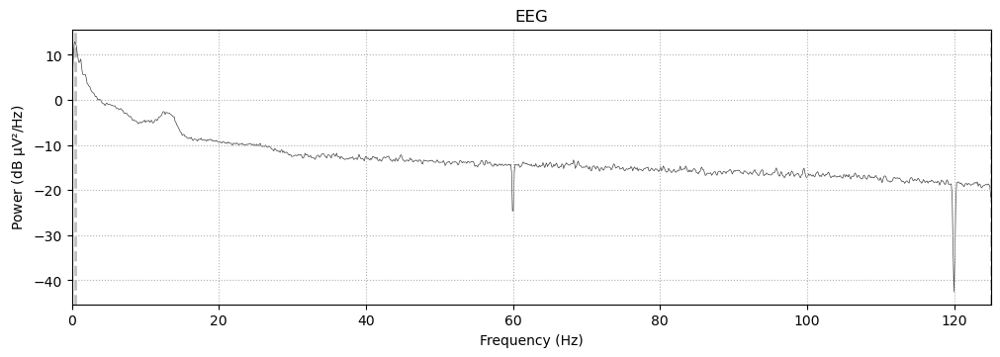

TP10
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


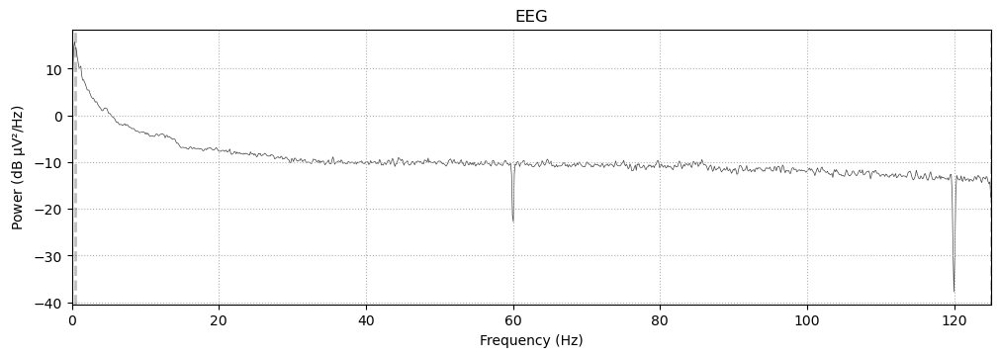

CP6
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


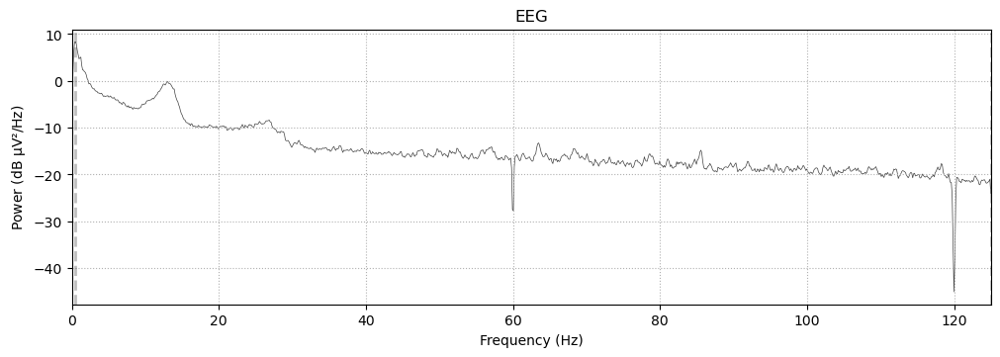

CP2
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


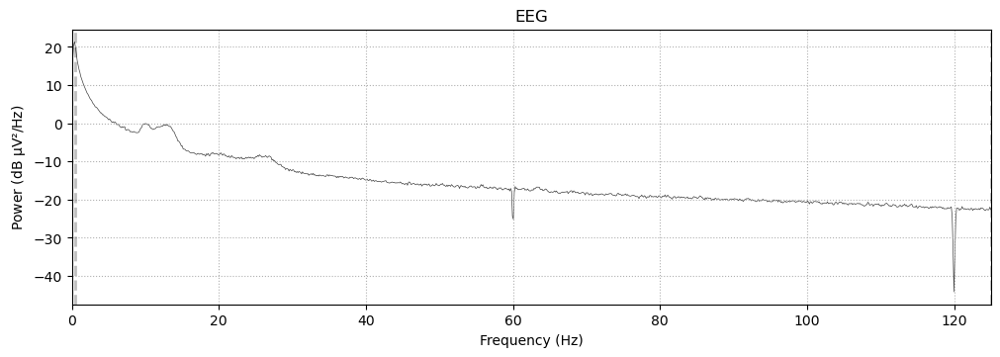

Cz
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


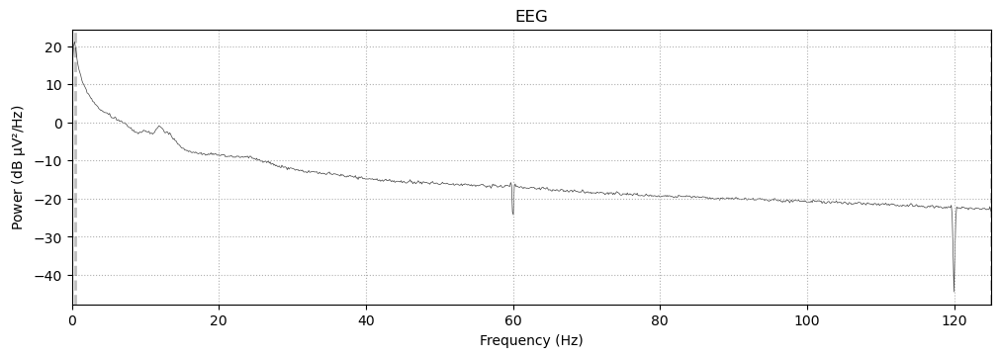

C4
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


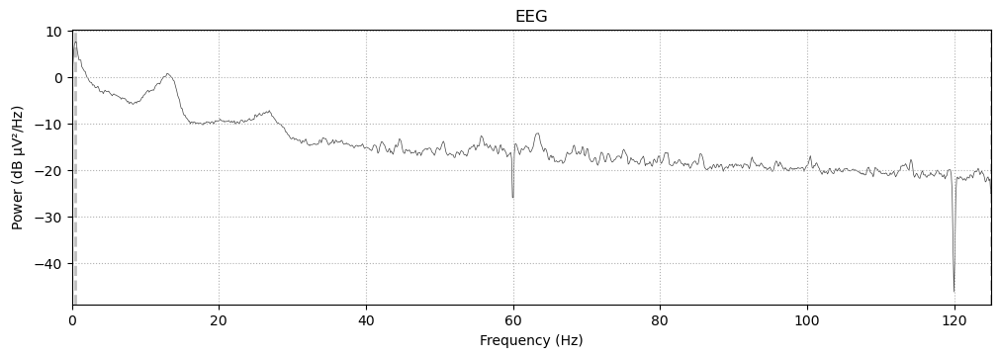

T8
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


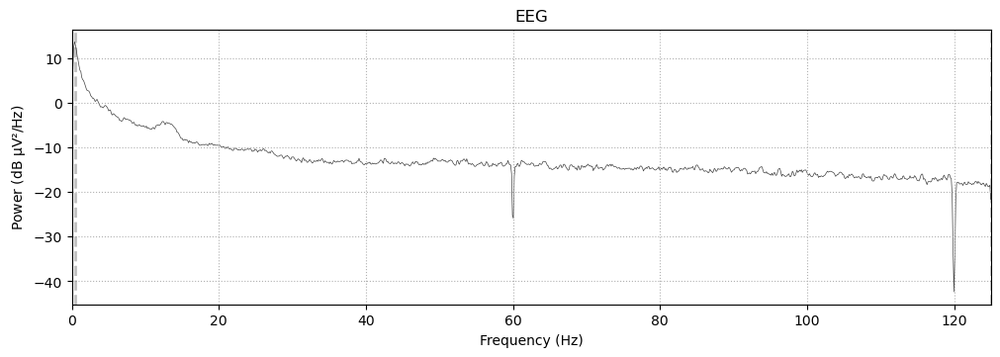

FT10
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


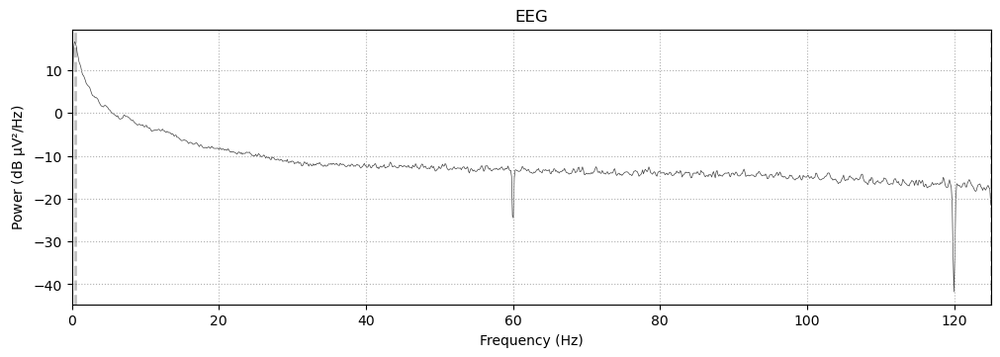

FC6
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


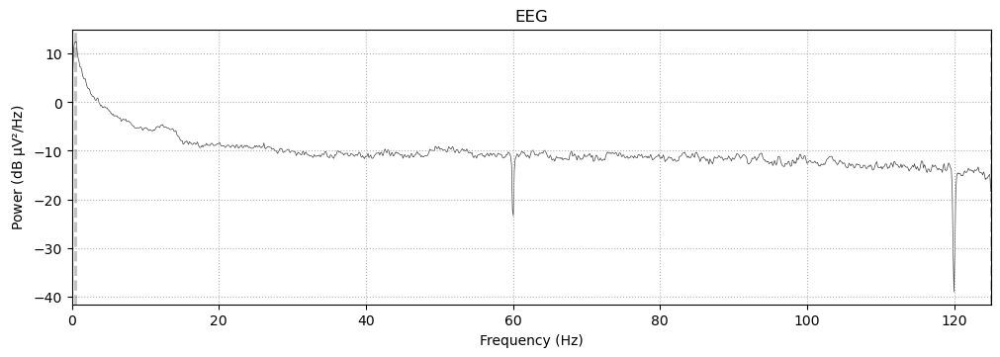

FC2
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


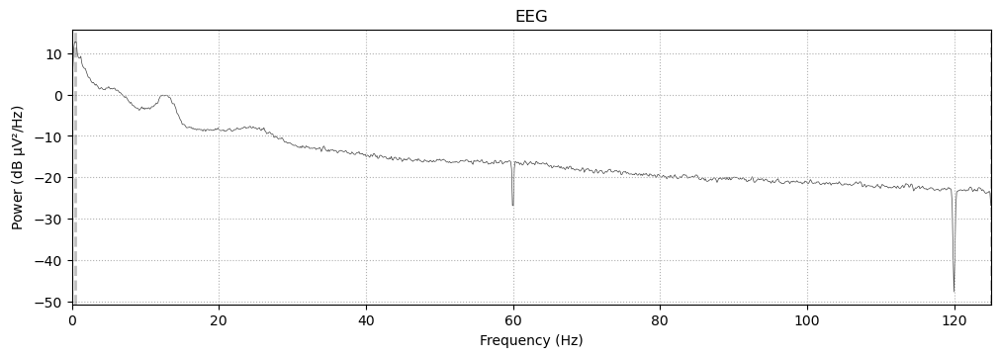

F4
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


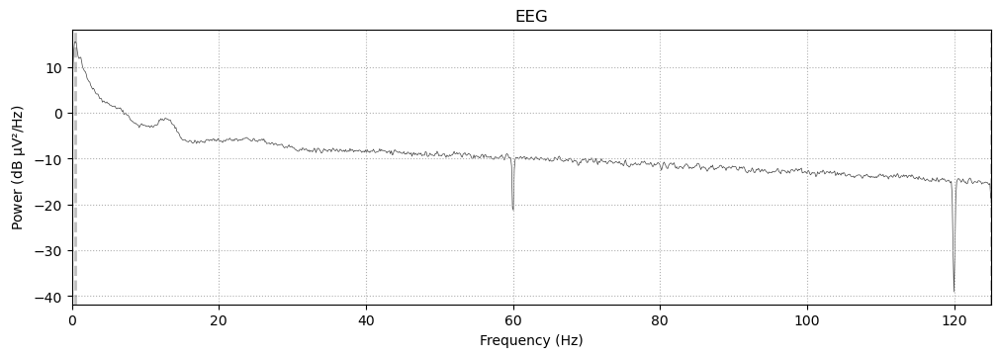

F8
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


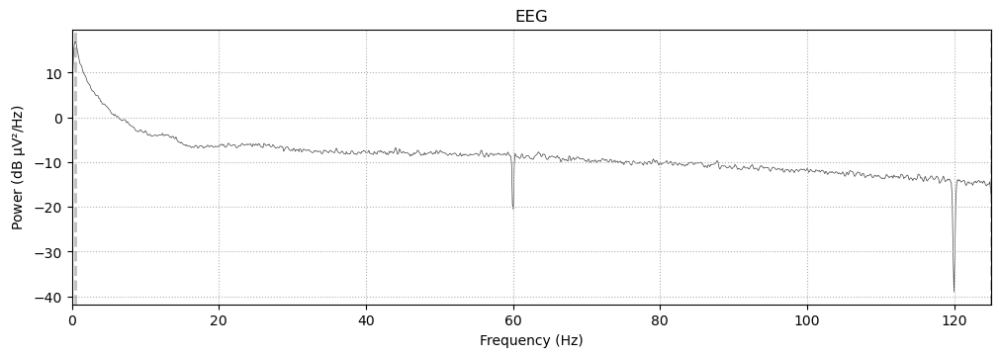

Fp2
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


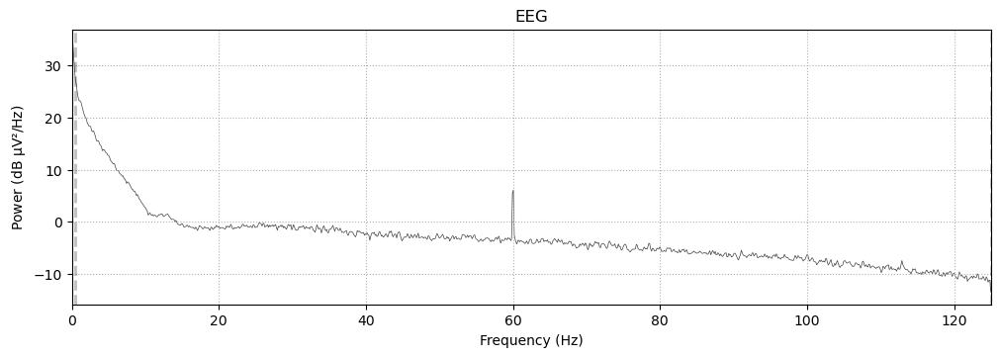

Fp1
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


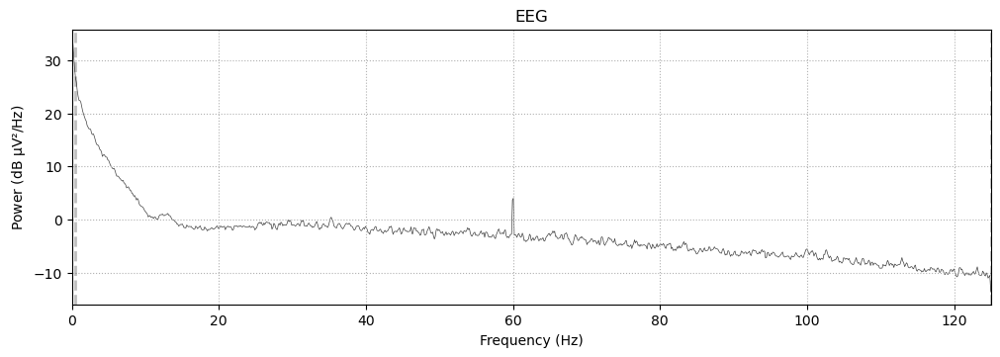

In [89]:
# if needed, plot a spectrum for each channel
for ch_ind in raw.info['ch_names']:
    print('=====================')
    print(ch_ind)
    raw.compute_psd(picks = ch_ind).plot(show=False, amplitude=False)
    plt.show()

# ICA bad trial correction

In [37]:
#### parameters ####

# directory
input_dir = work_dir + 'eeg_preprocessed_2025-11-13/2_bad_channel_corrected/0.5hf - lof/'
output_dir = work_dir + 'eeg_preprocessed_2025-11-13/3_ica/0.5hf - lof - ica_cont2cont/'
solution_dir = work_dir + 'eeg_preprocessed_2025-11-13/3_ica/0.5hf - lof - ica_cont2cont/ica_solution/'

# run ica on epoched data or continuous data
ica_input_type = 'continuous'
# ica_input_type = 'epochs'

# up to which IC you want to consider
ic_upto = 15
# ic_upto = 99

# Epoch window: 
erp_t_start = -0.2; erp_t_end = 1


#### ICA ####

# get all file names in the folder
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)

# initialize a dictionary for files 
for file in all_input:
    if file.endswith("prep.fif") and (file.split('.')[0]+ '_ica.fif' not in all_output): 

        # read in file
        raw = mne.io.read_raw_fif(input_dir + file, preload=True)

        # add back the reference channel
        raw = mne.add_reference_channels(raw,'TP9')

        # set Fp1 and Fp2 back to eeg
        raw.set_channel_types({'Fp1':'eeg', 'Fp2':'eeg'})

        # add the channel loc info (for the newly added reference channel)
        raw.set_montage(montage)

        # apply a common average referencing, to comply with the ICLabel requirements
        raw.set_eeg_reference("average")
        
        # make a filtered file copy ICA. It works better on signals with 1 Hz high-pass filtered and 100 Hz low-pass filtered
        raw_filt = raw.copy().filter(l_freq = 1, h_freq = 100)
        
        # initialize ica parameters
        ica = mne.preprocessing.ICA(
            # n_components=0.999999,
            max_iter='auto', # n-1
            # use ‘extended infomax’ method for fitting the ICA, to comply with the ICLabel requirements
            method = 'infomax', 
            fit_params = dict(extended=True),
            random_state = 42,
        )

        # run ica on epochs or continuous
        if ica_input_type=="epochs":
            # get event info for segmentation
            events_from_annot, event_dict = mne.events_from_annotations(raw_filt, verbose='WARNING')
            # segmentation for ERP
            epochs = mne.Epochs(
                raw_filt,
                events = events_from_annot, event_id = event_dict,
                tmin = erp_t_start, tmax = erp_t_end,
                # apply baseline correction
                baseline = None,
                # remove epochs that meet the rejection criteria
                reject = None,
                preload = True,
            )
            # set ica_input
            ica_input = epochs
        elif ica_input_type=="continuous":
            ica_input = raw_filt
    
        #### get ica solution ####
        ica.fit(ica_input, picks = ['eeg'])

        #### ICLabel ####
        ic_labels = label_components(ica_input, ica, method="iclabel")
        # save ica solutions
        ica.save(solution_dir + file.split('.')[0]+ '_icaSolution.fif', overwrite=True)
        
        # use ICLabel for automatic IC labeling
        ic_labels = label_components(raw_filt, ica, method="iclabel")
        # save
        with open(solution_dir + file.split('.')[0]+ '_icLabels.pickle', 'wb') as f:
            pickle.dump(ic_labels, f)
        
        #### auto select brain AND other ####
        labels = ic_labels["labels"]
        exclude_idx = [
            idx for idx, label in enumerate(labels) if idx<ic_upto and label not in ["brain", "other"]
        ]
        # record the bad ICs in bad_ICs.txt
        with open(output_dir + '/bad_ICs_auto.txt', 'a+') as f:
            _ = f.write(file + '\t' + str(exclude_idx) + '\n')

        #### apply ica ####
    
        # ica.apply() changes the Raw object in-place
        ica.apply(raw, exclude=exclude_idx) # apply continuous data
    
        # save data after ICA
        raw.save(output_dir + file.split('.')[0]+ '_ica.fif')

        # release memory
        del raw, raw_filt, ica_input

Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/2_bad_channel_corrected/0.5hf - lof/CUE2024_0041_VOT_corr_prep.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/2341583247.py:31: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/2_bad_channel_corrected/0.5hf - lof/CUE2024_0041_VOT_corr_prep.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload=True)


    Range : 0 ... 1051579 =      0.000 ...  4206.316 secs
Ready.
Reading 0 ... 1051579  =      0.000 ...  4206.316 secs...
EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 1e+02 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 100.00 Hz
- Upper transition bandwidth: 25.00 Hz (-6 dB cutoff frequency: 112.50 Hz)
- Filter length: 825 samples (3.300 s)



/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/2341583247.py:34: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  raw = mne.add_reference_channels(raw,'TP9')


Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 31 components
Computing Extended Infomax ICA
Fitting ICA took 267.1s.
Writing ICA solution to /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - lof - ica_cont2cont/ica_solution/CUE2024_0041_VOT_corr_prep_icaSolution.fif...


...

Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 30 components
Computing Extended Infomax ICA
Fitting ICA took 272.3s.
Writing ICA solution to /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - lof - ica_cont2cont/ica_solution/CUE2024_0006_VOT_corr_prep_icaSolution.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/2341583247.py:84: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - lof - ica_cont2cont/ica_solution/CUE2024_0006_VOT_corr_prep_icaSolution.fif) does not conform to MNE naming conventions. All ICA files should end with -ica.fif, -ica.fif.gz, _ica.fif or _ica.fif.gz
  ica.save(solution_dir + file.split('.')[0]+ '_icaSolution.fif', overwrite=True)


Applying ICA to Raw instance
    Transforming to ICA space (30 components)
    Zeroing out 6 ICA components
    Projecting back using 32 PCA components
Writing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - lof - ica_cont2cont/CUE2024_0006_VOT_corr_prep_ica.fif


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/2341583247.py:107: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - lof - ica_cont2cont/CUE2024_0006_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw.save(output_dir + file.split('.')[0]+ '_ica.fif')


Closing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - lof - ica_cont2cont/CUE2024_0006_VOT_corr_prep_ica.fif
[done]


# Epochs, autoreject, and evokeds
segmenting continuous EEG into epochs, then autoreject, then evoked
- re-reference
- segmentation

Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0064_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0064_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1004589 =      0.000 ...  4018.356 secs
Ready.
Reading 0 ... 1004589  =      0.000 ...  4018.356 secs...
Not setting metadata
1886 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1886 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/381 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/381 [00:00<?,       ?it/s]

Dropped 64 epochs: 12, 62, 106, 107, 108, 109, 110, 111, 113, 114, 115, 117, 118, 119, 120, 121, 161, 162, 169, 172, 191, 202, 205, 208, 210, 222, 228, 253, 271, 277, 278, 279, 282, 283, 289, 292, 293, 294, 295, 296, 297, 299, 301, 302, 303, 304, 305, 306, 312, 315, 316, 317, 319, 320, 324, 327, 331, 343, 344, 345, 346, 378, 379, 380


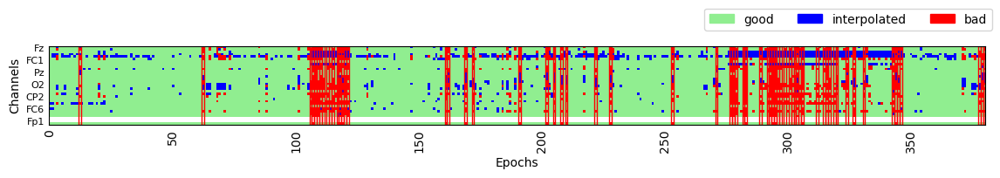

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/68 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/68 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/68 [00:00<?,       ?it/s]

Dropped 13 epochs: 21, 22, 34, 40, 45, 49, 51, 53, 55, 56, 57, 58, 60


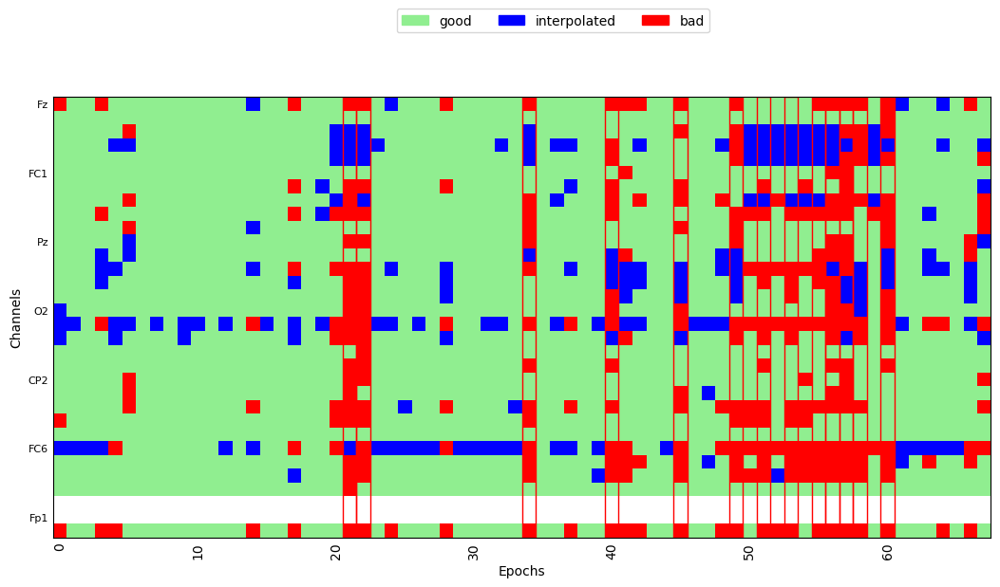

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/404 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/404 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/404 [00:00<?,       ?it/s]

Dropped 24 epochs: 47, 77, 128, 129, 167, 168, 211, 213, 214, 224, 227, 272, 292, 297, 298, 304, 323, 331, 370, 371, 372, 373, 374, 402


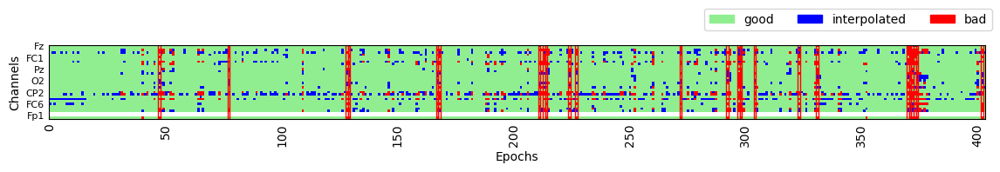

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 33 epochs: 5, 6, 9, 11, 14, 19, 20, 21, 24, 26, 28, 29, 32, 36, 38, 39, 40, 41, 42, 43, 44, 50, 51, 54, 55, 57, 58, 59, 63, 64, 65, 68, 69


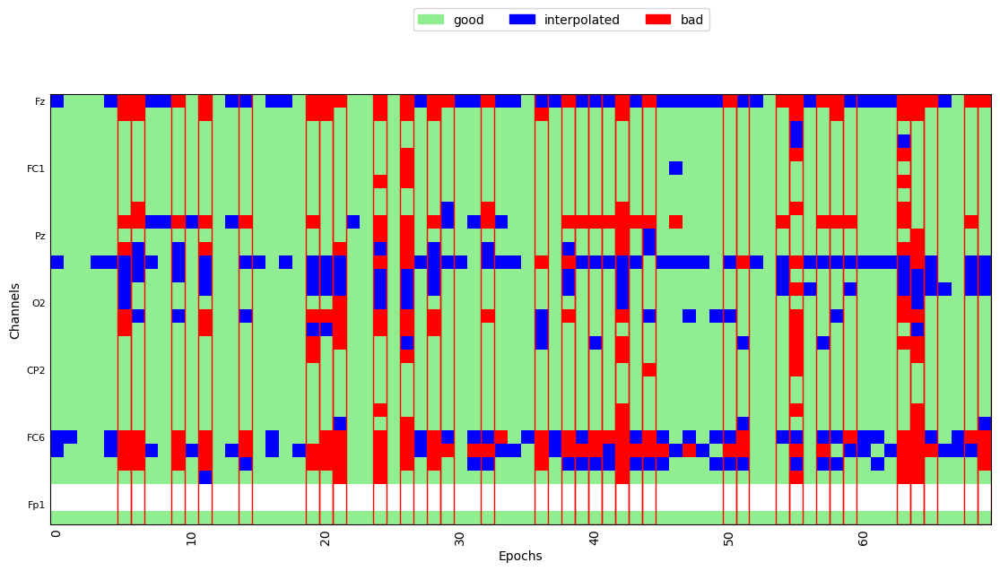

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/409 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/409 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/409 [00:00<?,       ?it/s]

Dropped 48 epochs: 40, 73, 102, 113, 119, 120, 128, 129, 130, 133, 138, 139, 145, 146, 147, 148, 149, 161, 182, 185, 190, 199, 210, 214, 215, 216, 217, 218, 219, 230, 231, 238, 239, 249, 266, 295, 296, 297, 299, 313, 319, 320, 334, 347, 350, 370, 373, 404


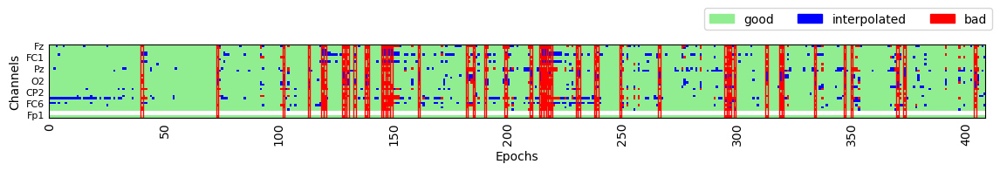

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 12 epochs: 16, 18, 23, 24, 26, 27, 29, 35, 37, 40, 51, 68


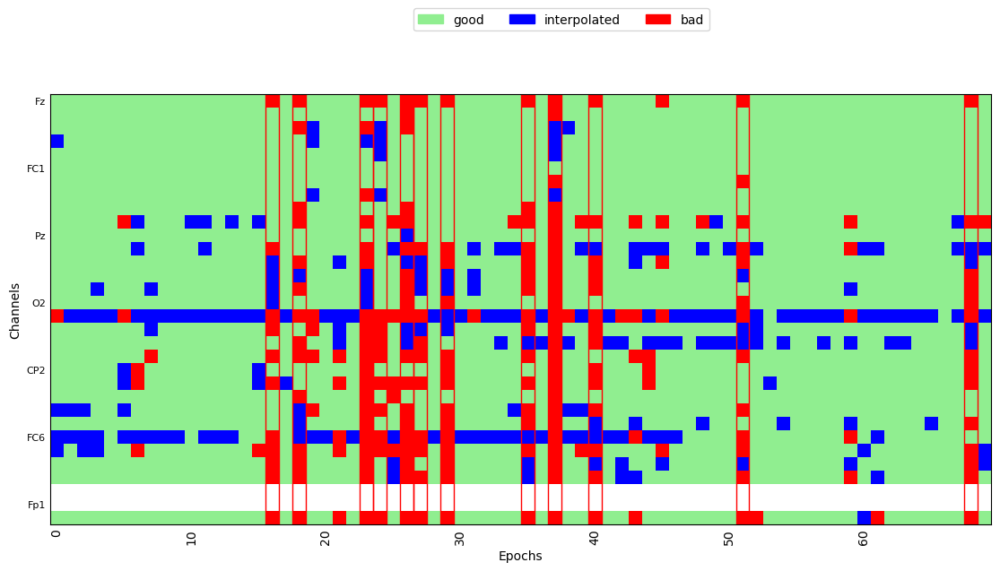

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/414 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/414 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/414 [00:00<?,       ?it/s]

Dropped 12 epochs: 79, 80, 93, 94, 95, 225, 226, 227, 229, 239, 247, 248


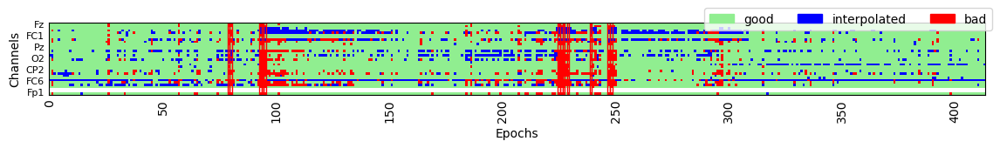

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 17 epochs: 5, 6, 8, 11, 12, 13, 18, 19, 21, 23, 34, 36, 38, 39, 47, 49, 52


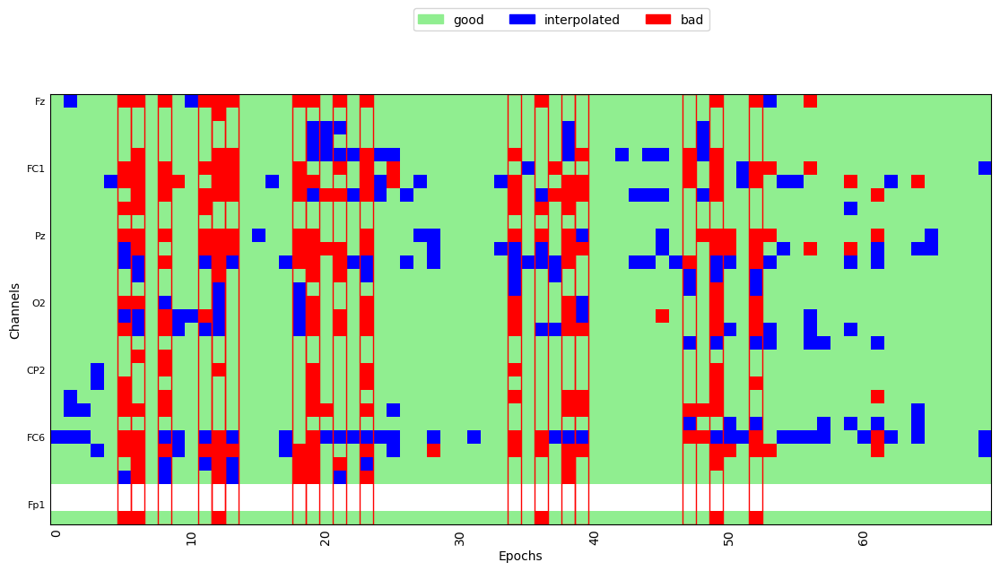

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0042_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0042_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1033989 =      0.000 ...  4135.956 secs
Ready.
Reading 0 ... 1033989  =      0.000 ...  4135.956 secs...
Not setting metadata
1946 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1946 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/409 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/409 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


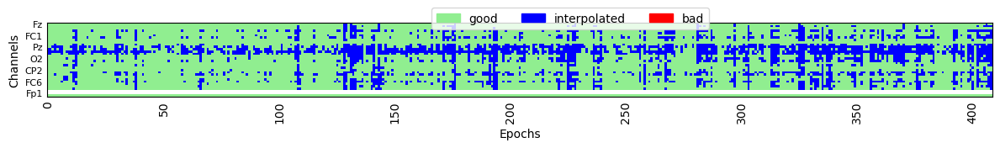

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.80 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 26, 37, 50, 56


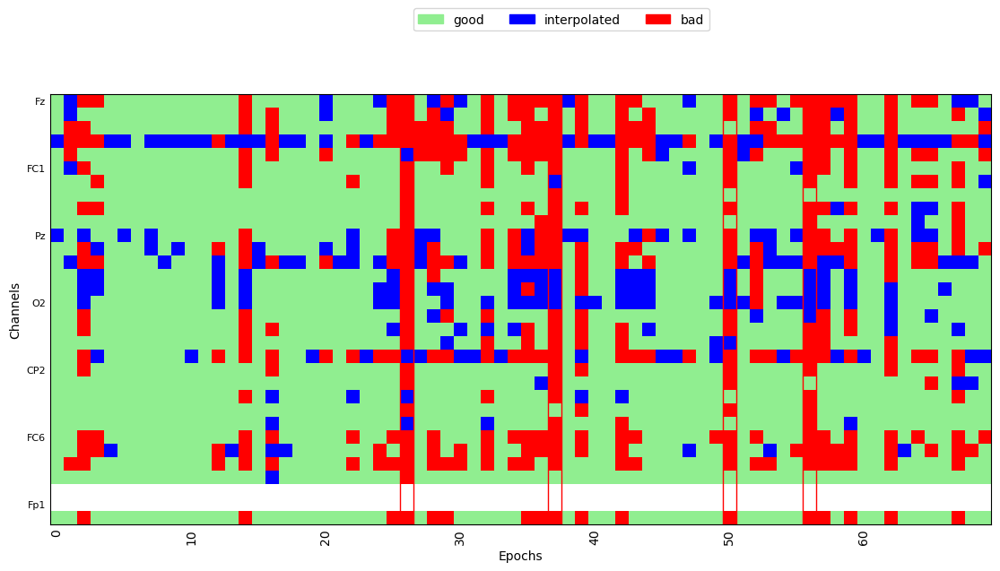

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/418 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/418 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/418 [00:00<?,       ?it/s]

Dropped 16 epochs: 73, 127, 128, 156, 208, 220, 231, 232, 239, 240, 256, 318, 344, 363, 393, 401


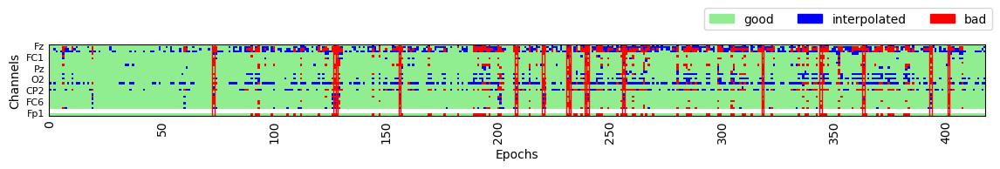

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 27 epochs: 2, 11, 15, 22, 24, 27, 28, 32, 33, 37, 38, 40, 43, 44, 45, 46, 48, 49, 50, 52, 55, 57, 59, 62, 64, 65, 69


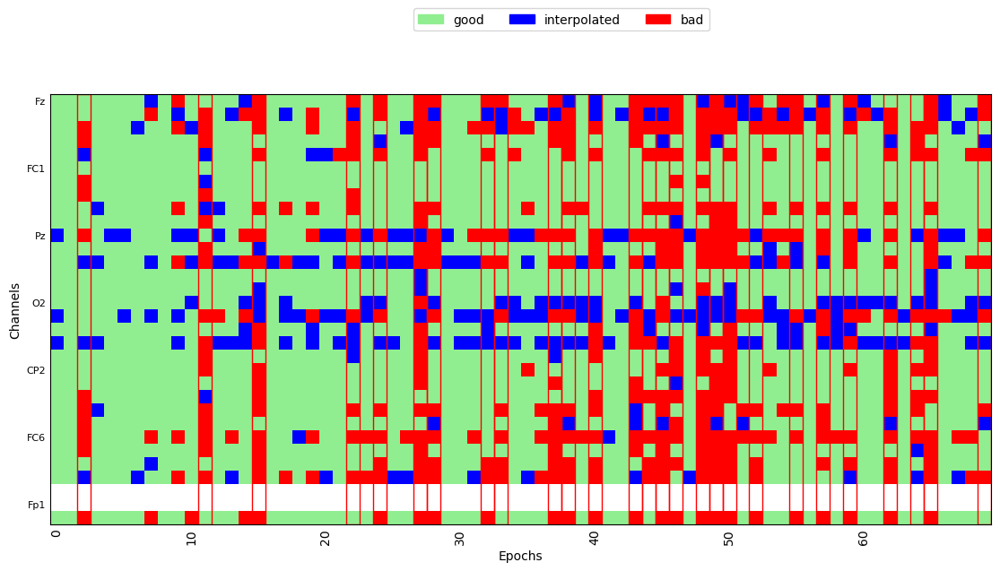

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/416 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/416 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=1


  0%|          | Repairing epochs : 0/416 [00:00<?,       ?it/s]

Dropped 56 epochs: 8, 15, 17, 22, 155, 156, 157, 158, 170, 172, 174, 175, 178, 179, 180, 183, 187, 188, 189, 191, 218, 239, 240, 260, 261, 262, 263, 264, 277, 279, 280, 285, 286, 296, 298, 307, 313, 315, 316, 318, 319, 322, 325, 326, 327, 328, 348, 351, 368, 369, 370, 397, 402, 405, 406, 407


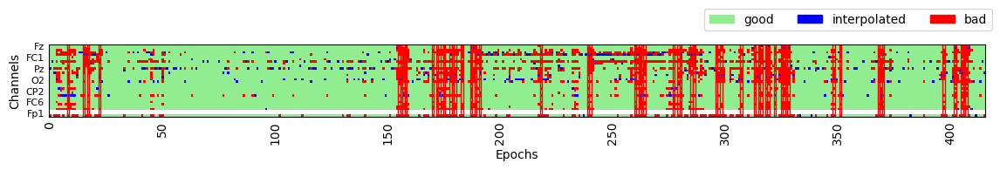

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 25, 27, 49, 52, 67


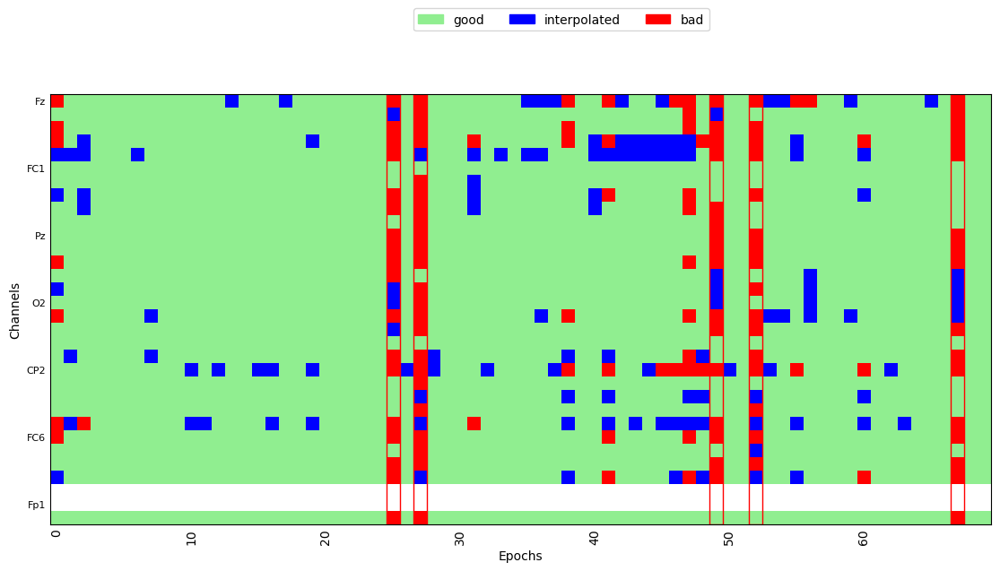

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/423 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/423 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/423 [00:00<?,       ?it/s]

Dropped 17 epochs: 0, 84, 149, 189, 224, 225, 263, 264, 283, 284, 333, 335, 337, 338, 378, 408, 417


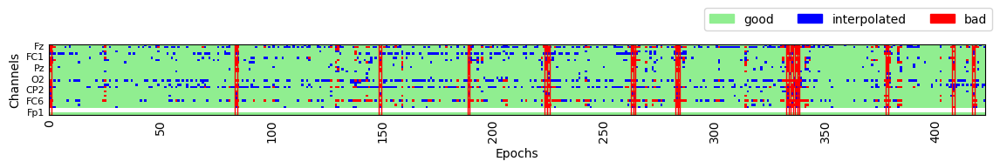

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.80 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 62


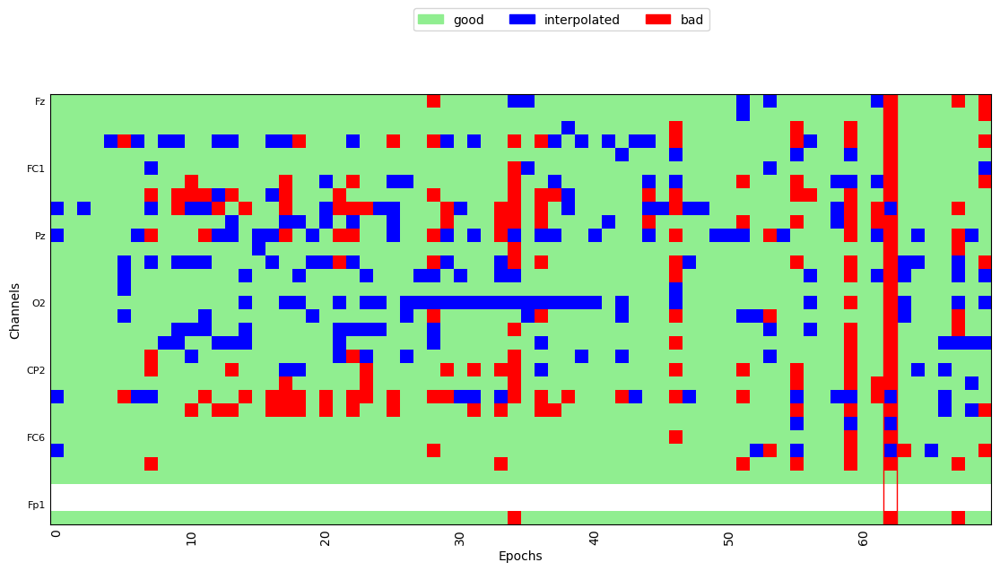

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0006_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0006_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1043284 =      0.000 ...  4173.136 secs
Ready.
Reading 0 ... 1043284  =      0.000 ...  4173.136 secs...
Not setting metadata
1951 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1951 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/418 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/418 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


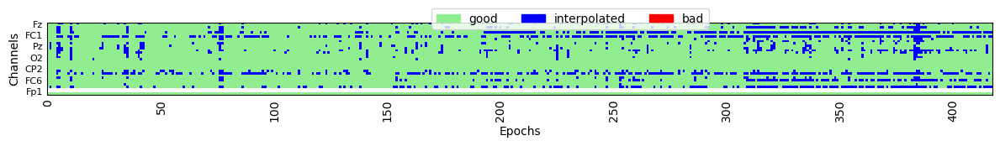

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 55


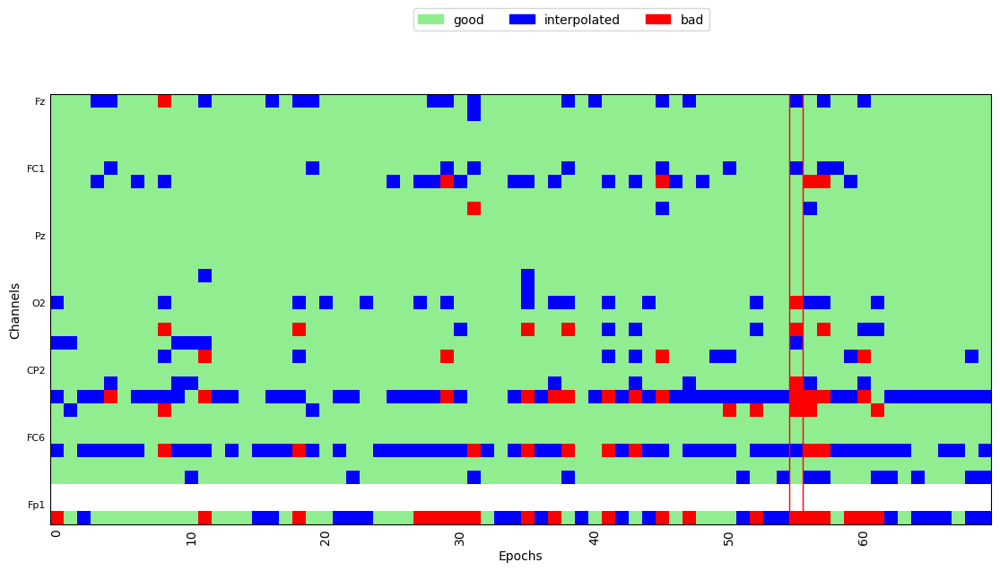

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/410 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/410 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/410 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


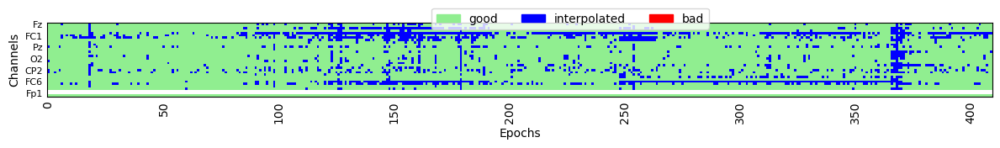

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 27


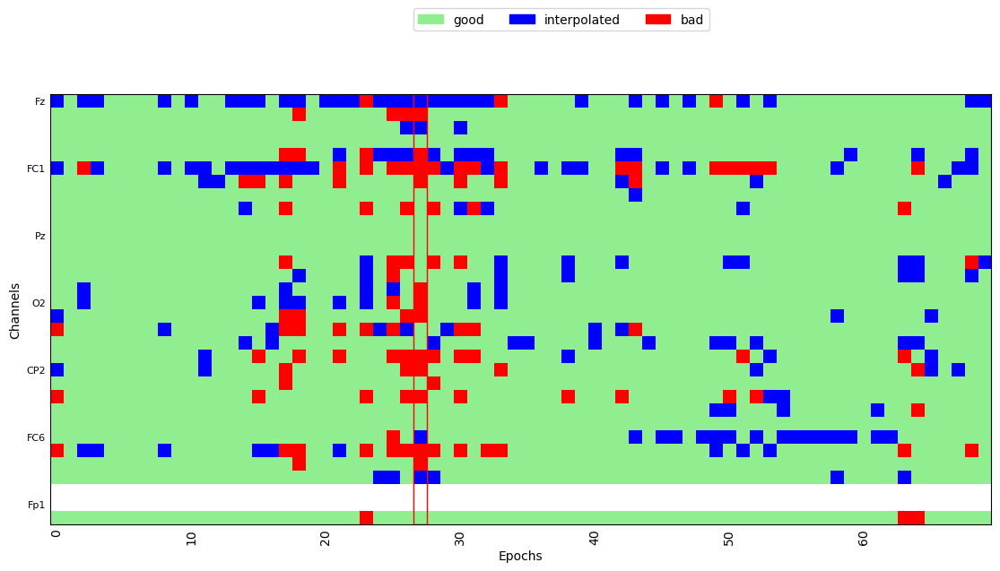

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/423 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/423 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=1


  0%|          | Repairing epochs : 0/423 [00:00<?,       ?it/s]

Dropped 8 epochs: 5, 58, 189, 190, 249, 290, 300, 411


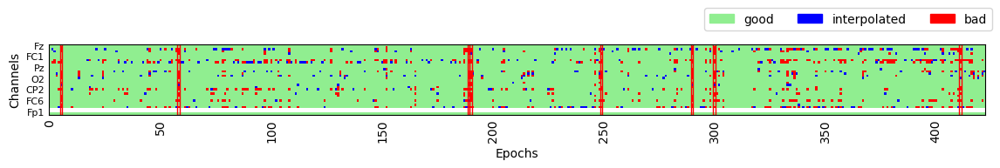

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

Dropped 9 epochs: 0, 4, 9, 15, 39, 49, 50, 56, 64


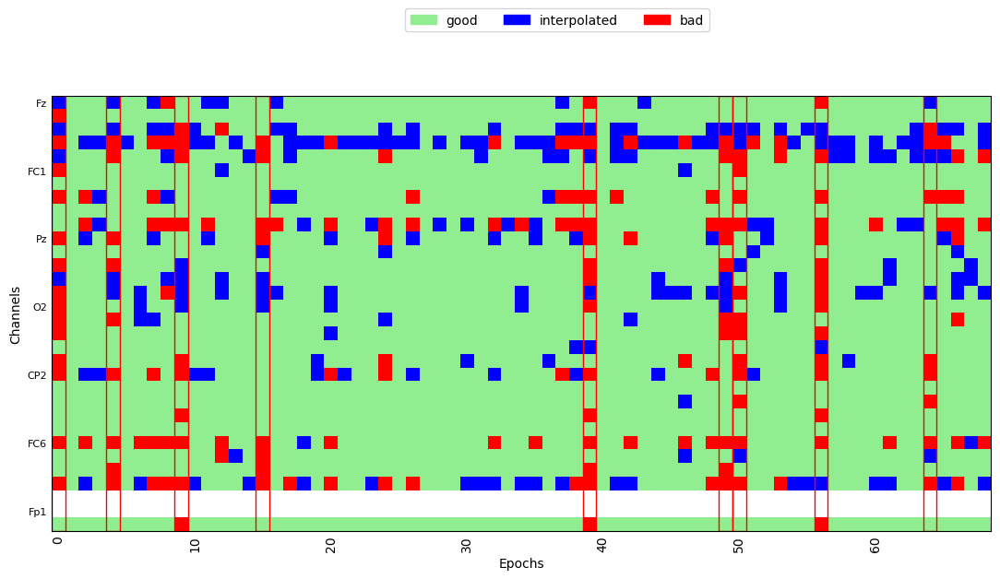

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/421 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/421 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/421 [00:00<?,       ?it/s]

Dropped 19 epochs: 26, 42, 43, 110, 114, 115, 116, 117, 119, 132, 133, 222, 264, 280, 284, 294, 295, 296, 380


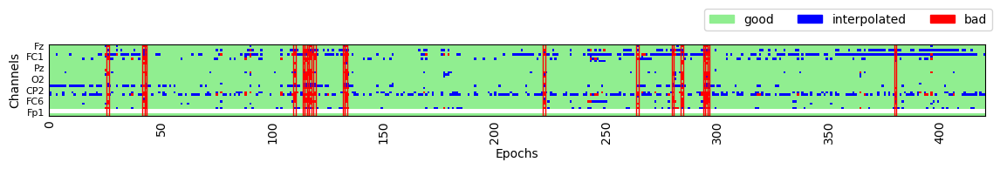

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 4, 47, 63, 64, 69


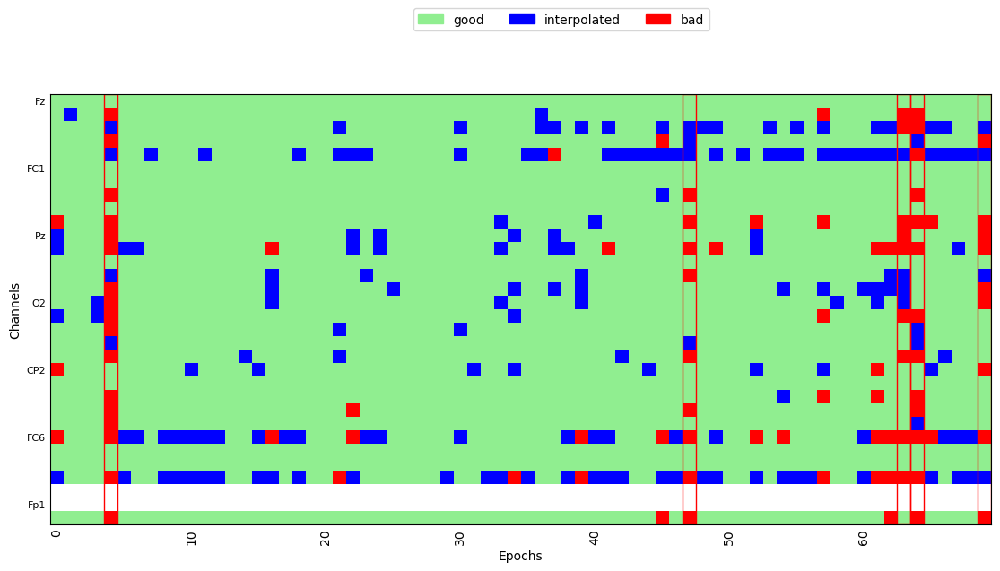

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0052_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0052_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1032049 =      0.000 ...  4128.196 secs
Ready.
Reading 0 ... 1032049  =      0.000 ...  4128.196 secs...
Not setting metadata
1957 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1957 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/410 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/410 [00:00<?,       ?it/s]

Dropped 21 epochs: 32, 98, 139, 147, 221, 228, 254, 262, 265, 277, 278, 279, 280, 281, 287, 291, 316, 350, 354, 355, 388


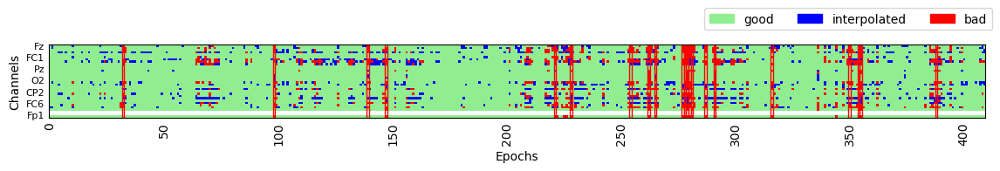

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 9, 17, 37, 59, 69


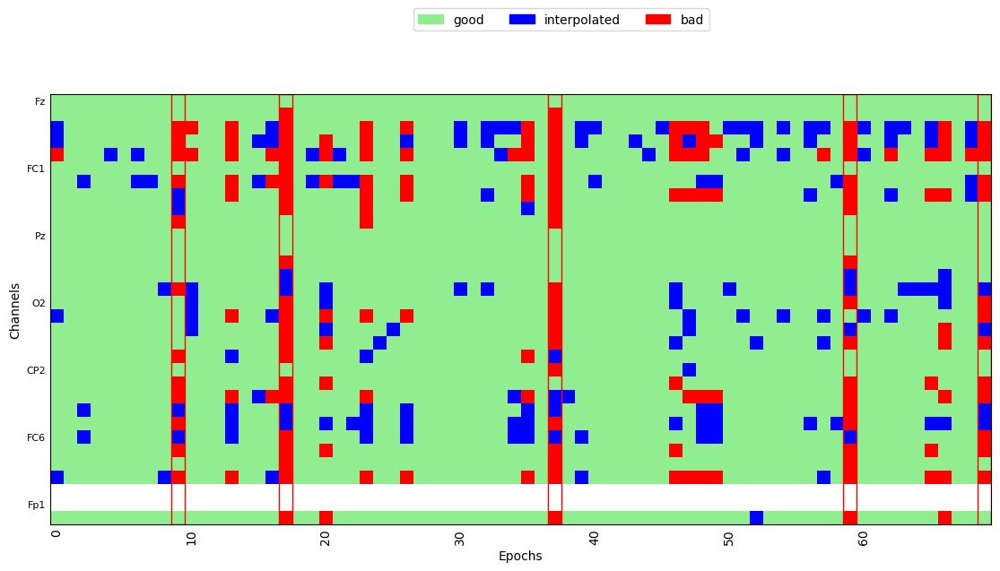

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/440 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.10 and n_interpolate=1


  0%|          | Repairing epochs : 0/440 [00:00<?,       ?it/s]

Dropped 141 epochs: 1, 2, 3, 4, 29, 32, 50, 56, 57, 58, 59, 60, 61, 62, 63, 64, 72, 79, 85, 89, 90, 96, 102, 103, 104, 118, 119, 123, 127, 128, 130, 133, 134, 135, 136, 137, 138, 147, 148, 149, 150, 153, 169, 171, 172, 181, 184, 189, 190, 191, 197, 198, 200, 211, 213, 216, 217, 230, 237, 242, 244, 246, 247, 249, 250, 251, 252, 253, 254, 255, 257, 258, 259, 278, 283, 285, 287, 288, 290, 291, 292, 293, 296, 301, 315, 317, 318, 319, 320, 321, 325, 326, 329, 330, 331, 333, 334, 335, 336, 337, 338, 339, 341, 346, 349, 350, 351, 352, 353, 355, 359, 361, 369, 370, 371, 376, 392, 393, 394, 395, 396, 397, 398, 399, 407, 408, 409, 410, 411, 412, 413, 414, 415, 422, 425, 432, 435, 436, 437, 438, 439


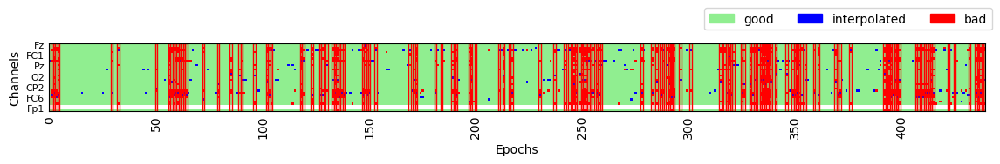

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


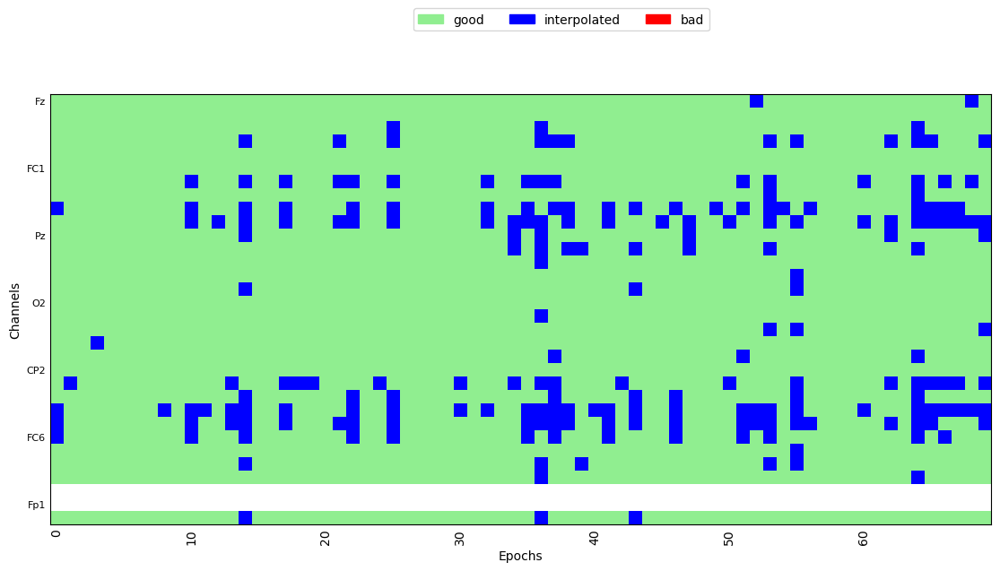

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/411 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/411 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/411 [00:00<?,       ?it/s]

Dropped 25 epochs: 11, 12, 27, 55, 56, 81, 84, 121, 122, 128, 182, 183, 186, 249, 287, 289, 305, 344, 368, 374, 375, 392, 394, 404, 405


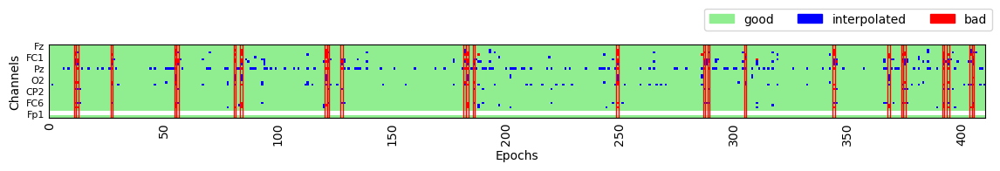

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 53


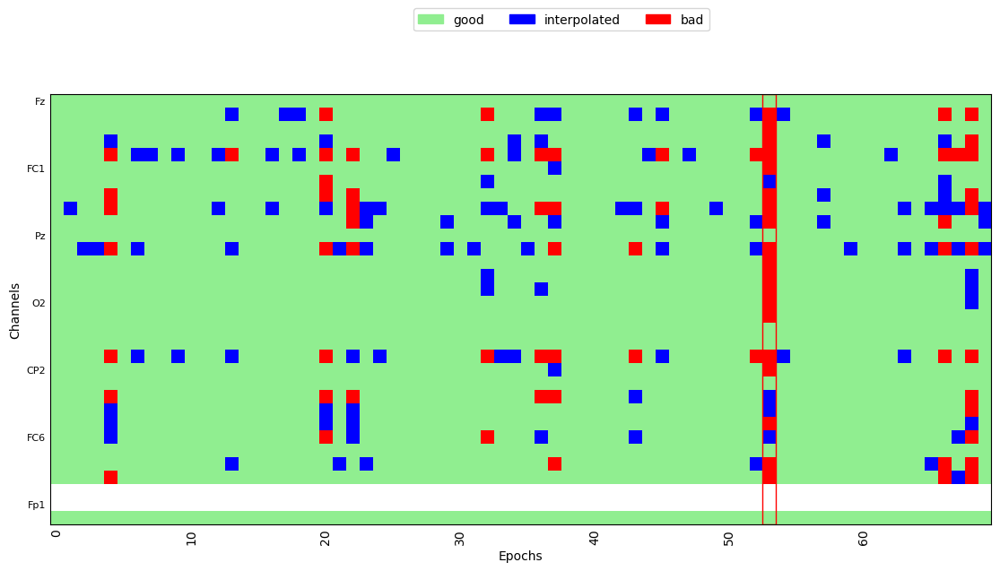

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/416 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/416 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/416 [00:00<?,       ?it/s]

Dropped 24 epochs: 10, 87, 88, 89, 117, 140, 168, 169, 212, 236, 237, 238, 240, 241, 242, 243, 244, 261, 278, 323, 369, 391, 398, 407


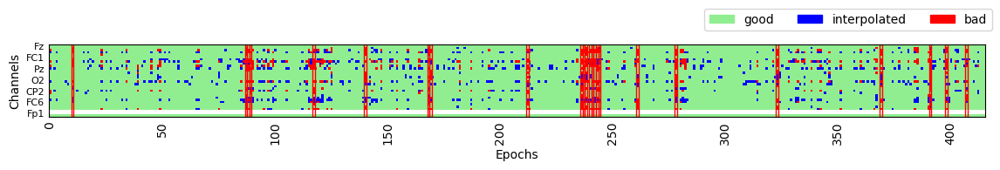

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 33, 64


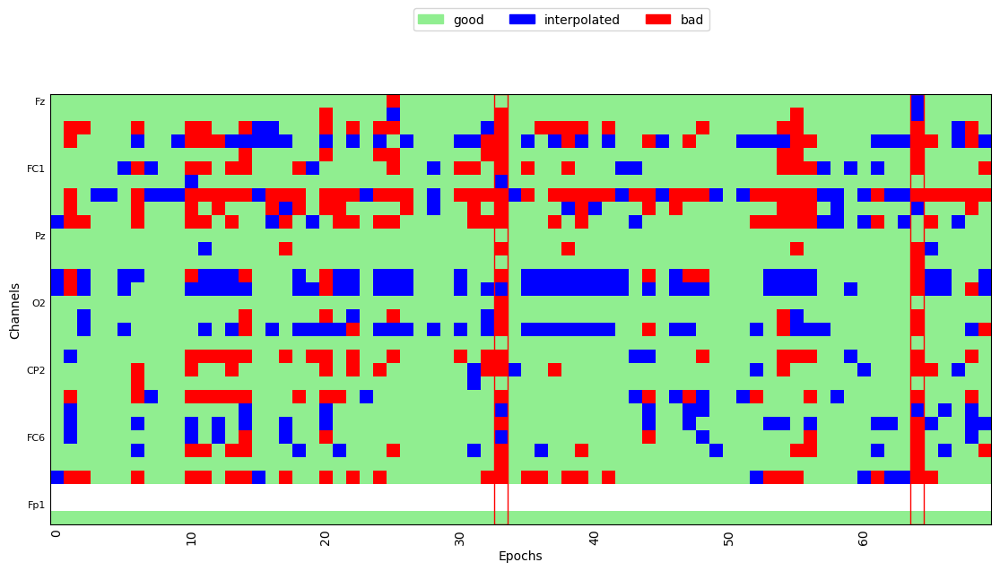

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0060_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0060_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1049839 =      0.000 ...  4199.356 secs
Ready.
Reading 0 ... 1049839  =      0.000 ...  4199.356 secs...
Not setting metadata
1950 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1950 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/407 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.90 and n_interpolate=4


  0%|          | Repairing epochs : 0/407 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


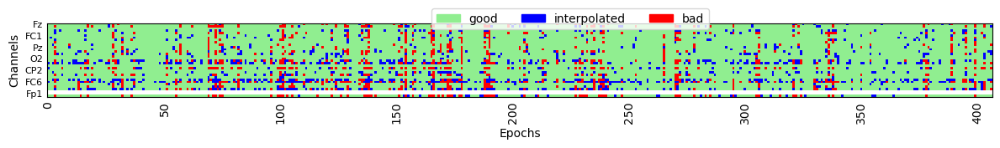

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 15, 24, 30, 69


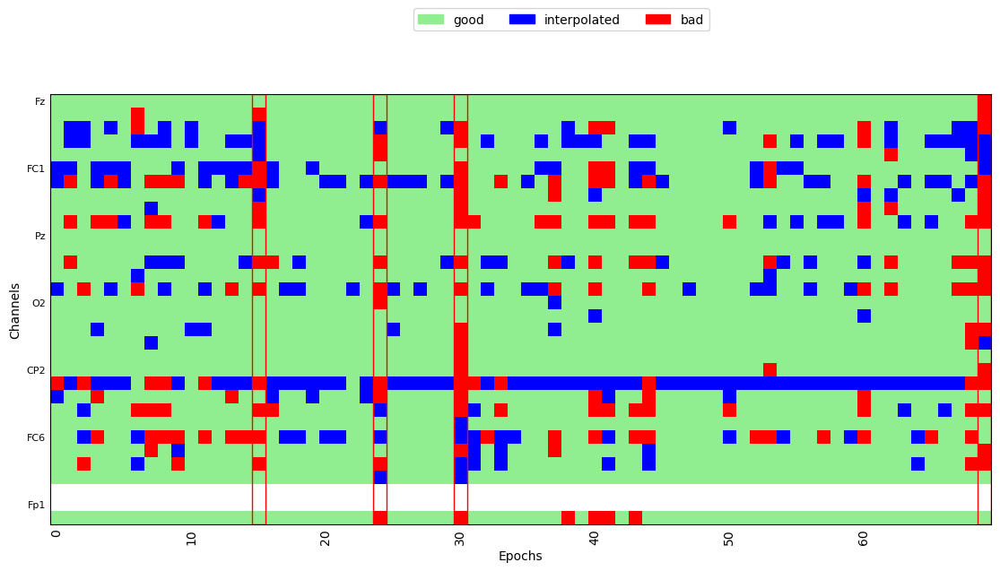

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/428 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/428 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/428 [00:00<?,       ?it/s]

Dropped 34 epochs: 0, 1, 2, 11, 20, 21, 22, 24, 34, 98, 118, 140, 141, 142, 145, 172, 180, 181, 182, 185, 195, 221, 256, 292, 346, 348, 349, 359, 360, 372, 389, 392, 407, 427


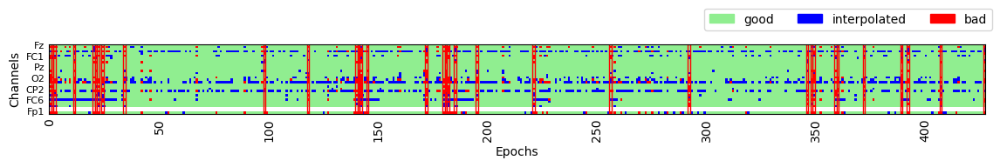

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 6 epochs: 0, 1, 28, 54, 60, 64


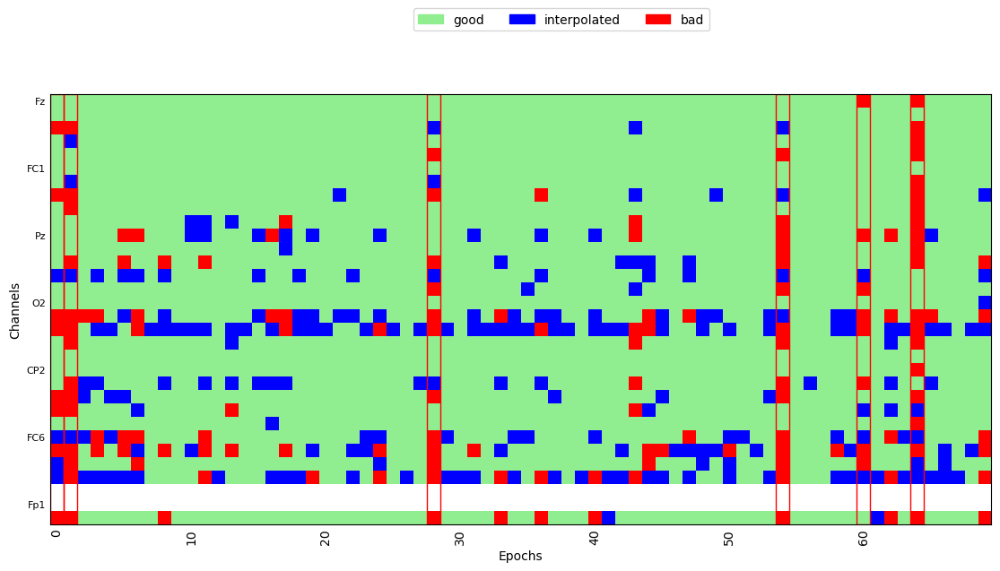

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/399 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=4


  0%|          | Repairing epochs : 0/399 [00:00<?,       ?it/s]

Dropped 6 epochs: 114, 122, 137, 166, 238, 317


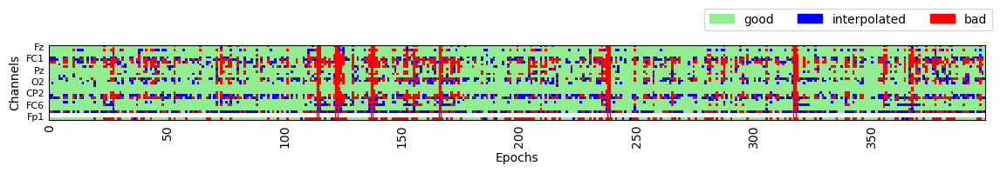

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 6 epochs: 39, 44, 52, 55, 59, 69


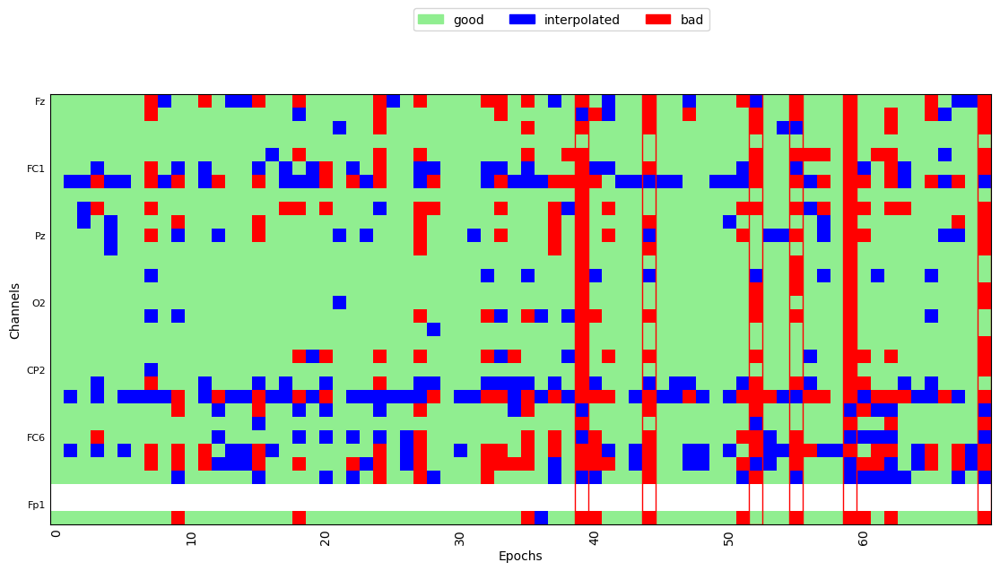

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/436 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/436 [00:00<?,       ?it/s]

Dropped 89 epochs: 0, 1, 2, 4, 5, 6, 7, 17, 18, 34, 36, 50, 54, 55, 64, 73, 84, 106, 107, 108, 117, 120, 128, 129, 138, 142, 157, 160, 179, 193, 205, 206, 212, 213, 214, 215, 216, 217, 218, 228, 237, 242, 244, 245, 247, 250, 276, 290, 300, 301, 302, 311, 312, 334, 340, 341, 342, 344, 345, 351, 360, 361, 369, 370, 373, 382, 383, 384, 386, 387, 388, 389, 399, 400, 401, 402, 404, 405, 413, 416, 419, 421, 422, 423, 424, 425, 426, 427, 428


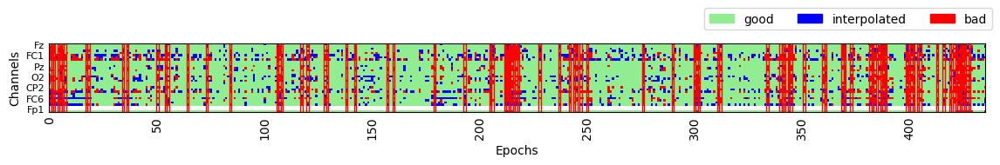

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 8 epochs: 0, 10, 17, 42, 62, 64, 65, 67


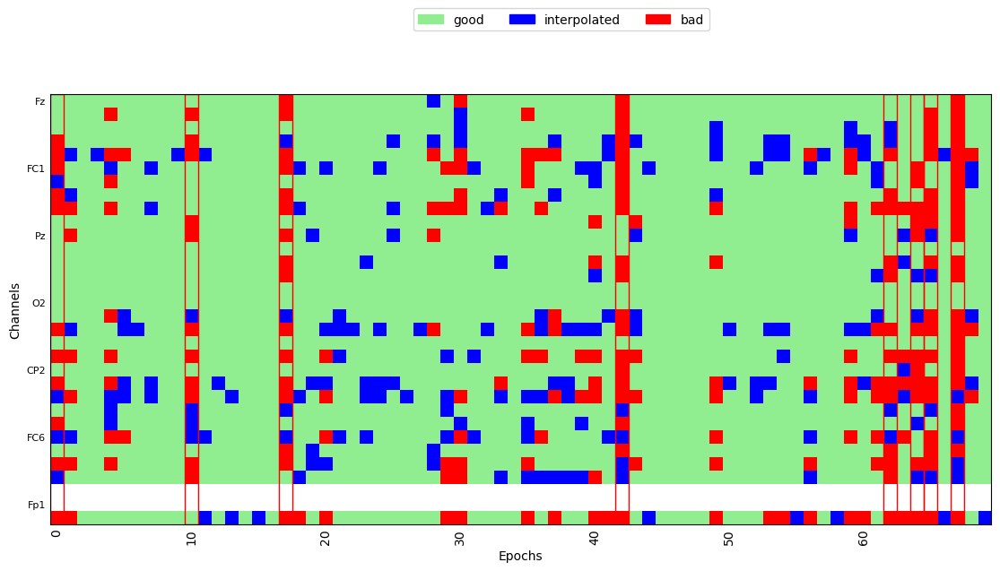

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0050_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0050_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1035504 =      0.000 ...  4142.016 secs
Ready.
Reading 0 ... 1035504  =      0.000 ...  4142.016 secs...
Not setting metadata
1912 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1912 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/394 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/394 [00:00<?,       ?it/s]

Dropped 10 epochs: 6, 12, 22, 170, 326, 329, 337, 366, 370, 377


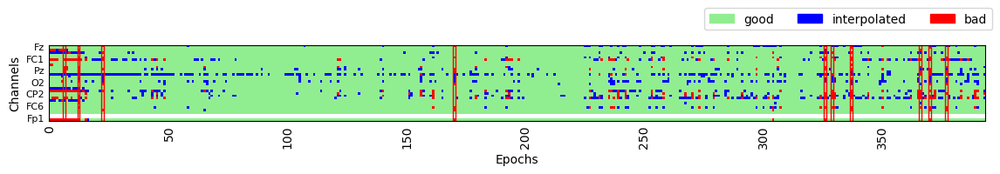

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


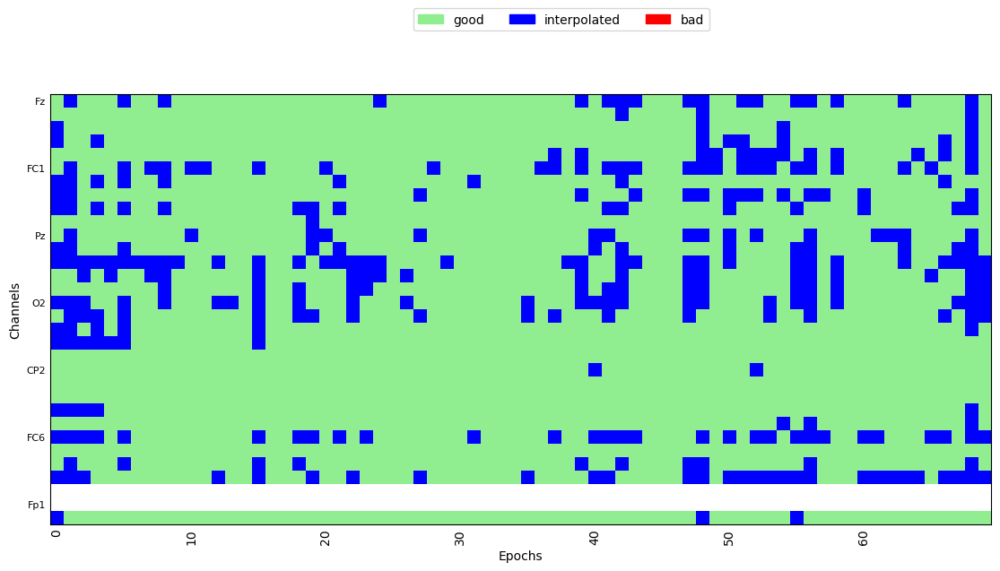

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/410 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/410 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=1


  0%|          | Repairing epochs : 0/410 [00:00<?,       ?it/s]

Dropped 14 epochs: 1, 254, 272, 280, 283, 301, 327, 332, 337, 357, 372, 373, 380, 392


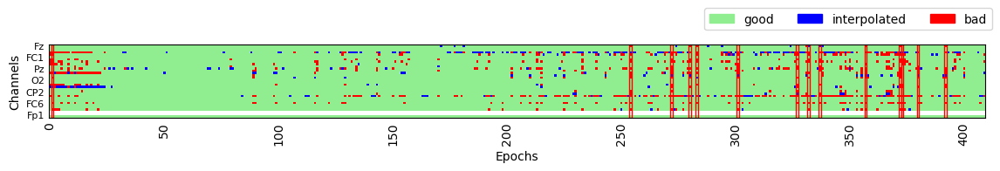

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 18, 42, 49, 61


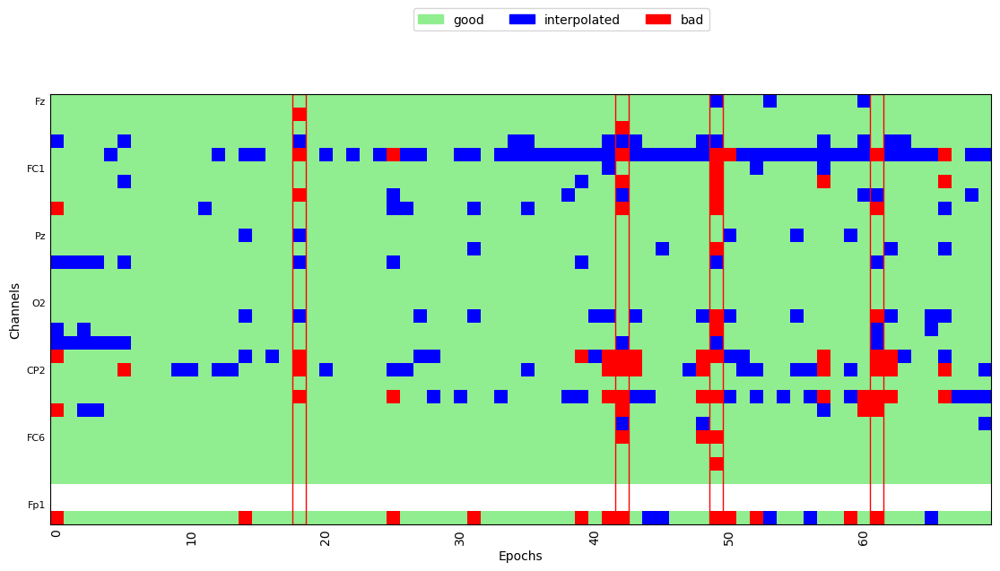

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/405 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/405 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=1


  0%|          | Repairing epochs : 0/405 [00:00<?,       ?it/s]

Dropped 6 epochs: 71, 87, 288, 290, 374, 398


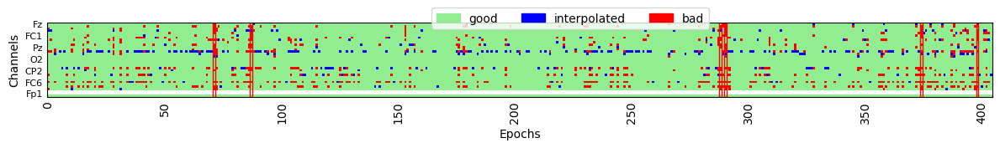

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


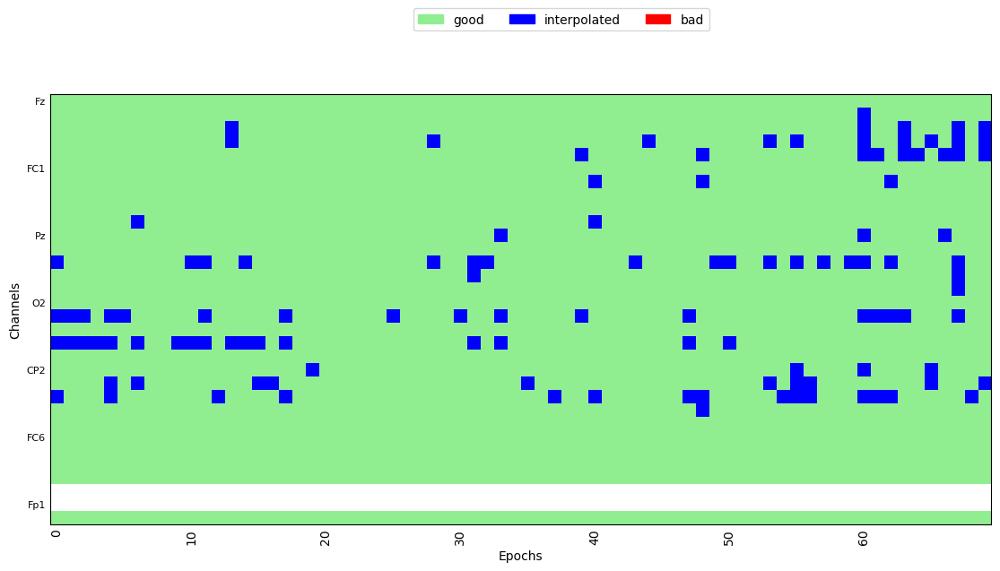

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/423 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/423 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/423 [00:00<?,       ?it/s]

Dropped 72 epochs: 55, 60, 108, 142, 143, 164, 176, 183, 186, 189, 190, 191, 192, 198, 203, 226, 227, 234, 237, 238, 253, 254, 255, 257, 259, 262, 263, 264, 267, 277, 280, 284, 299, 300, 301, 304, 305, 308, 310, 312, 318, 319, 327, 328, 331, 333, 334, 335, 336, 340, 341, 342, 349, 351, 362, 375, 377, 378, 382, 383, 384, 385, 386, 394, 401, 403, 410, 412, 414, 415, 416, 419


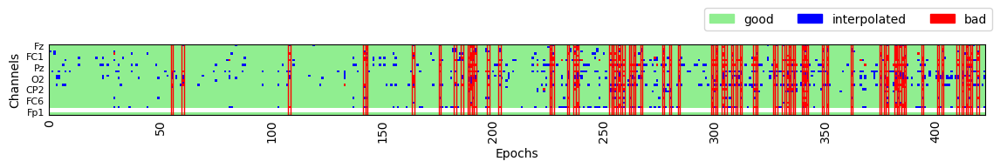

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


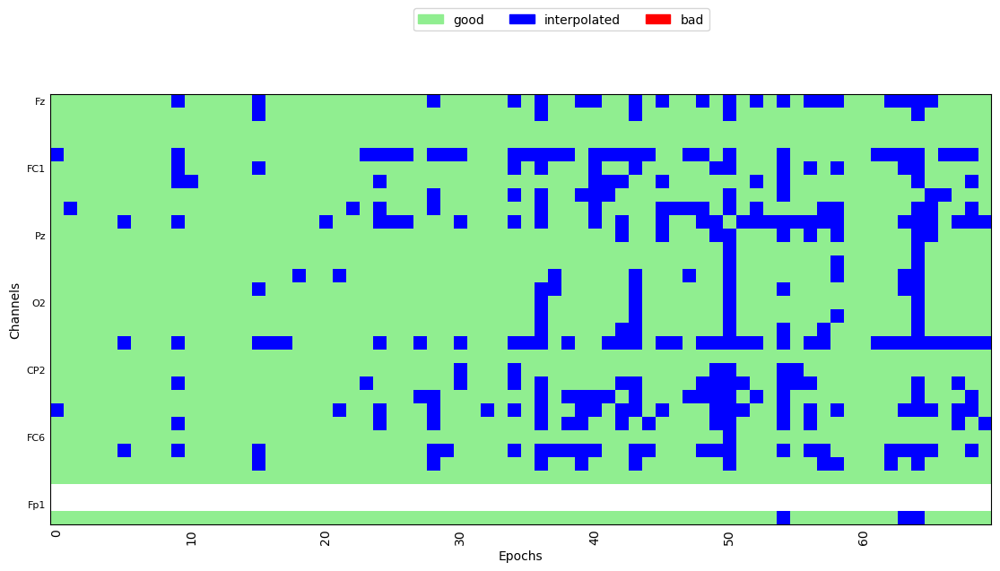

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0062_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0062_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1048569 =      0.000 ...  4194.276 secs
Ready.
Reading 0 ... 1048569  =      0.000 ...  4194.276 secs...
Not setting metadata
1978 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1978 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/433 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/433 [00:00<?,       ?it/s]

Dropped 20 epochs: 46, 47, 48, 107, 108, 109, 110, 111, 112, 113, 202, 203, 205, 291, 292, 305, 306, 307, 308, 360


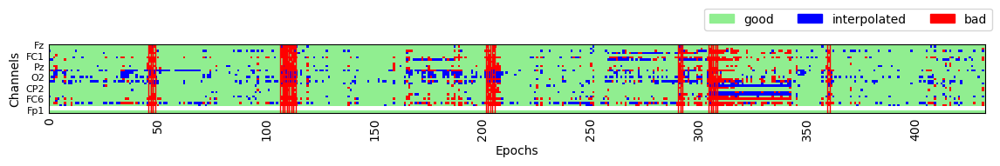

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 18


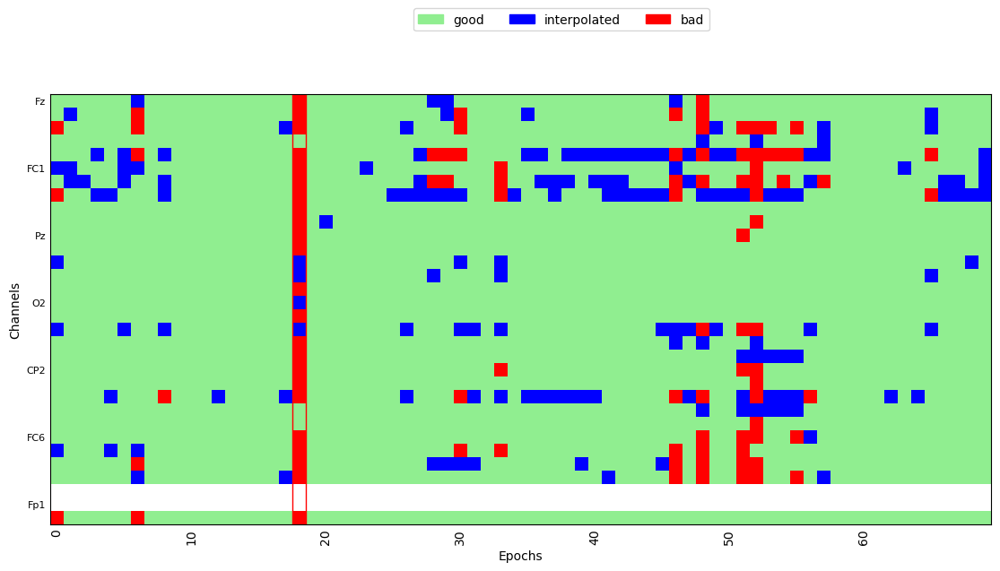

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/432 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/432 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/432 [00:00<?,       ?it/s]

Dropped 9 epochs: 146, 247, 248, 261, 361, 378, 379, 380, 381


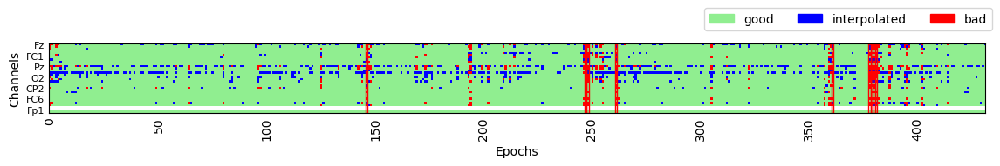

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 28, 31, 41, 58, 62


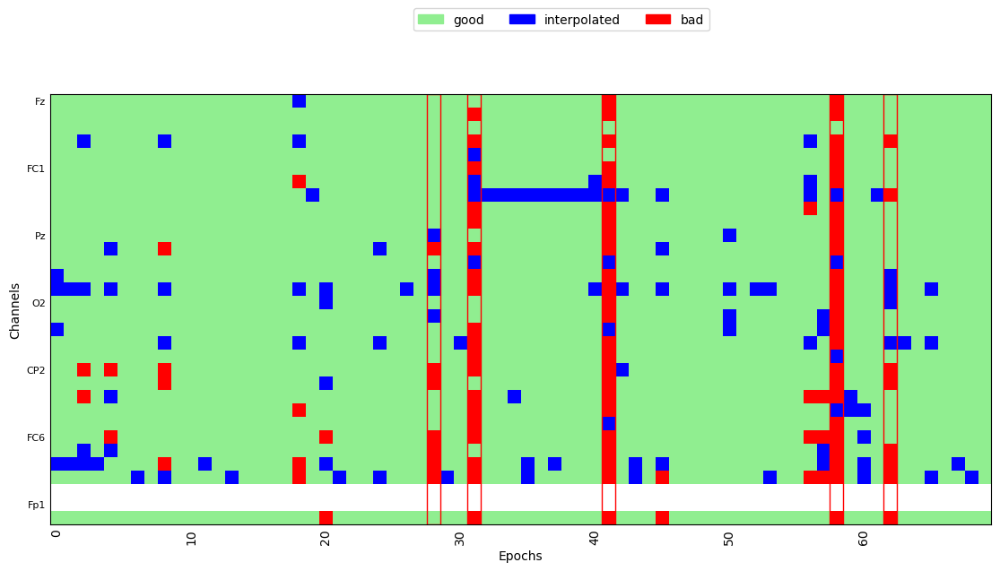

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/445 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/445 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/445 [00:00<?,       ?it/s]

Dropped 26 epochs: 59, 62, 63, 68, 70, 71, 72, 74, 126, 184, 189, 270, 271, 272, 277, 278, 280, 331, 332, 404, 408, 409, 410, 415, 419, 422


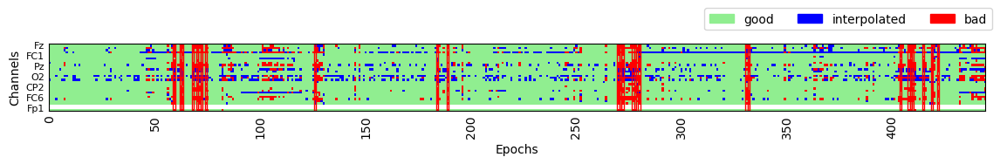

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 9, 64


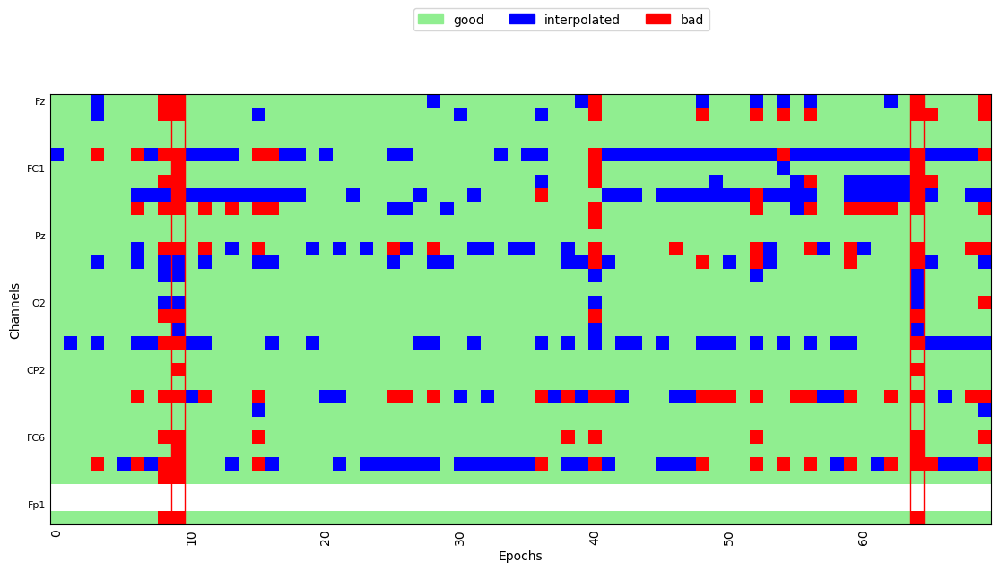

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/388 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/388 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/388 [00:00<?,       ?it/s]

Dropped 49 epochs: 47, 74, 75, 93, 110, 119, 122, 130, 131, 133, 134, 147, 148, 154, 160, 173, 174, 190, 192, 194, 200, 201, 219, 220, 221, 231, 234, 242, 252, 255, 256, 258, 272, 290, 291, 292, 293, 297, 306, 310, 327, 328, 329, 337, 347, 362, 373, 379, 380


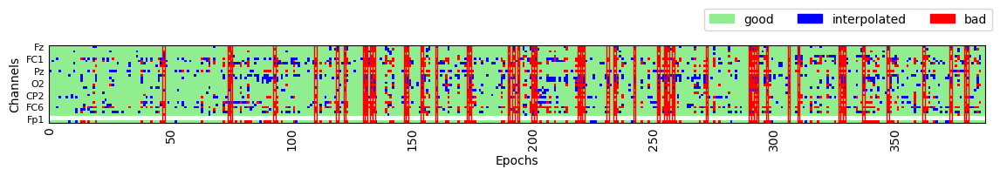

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 47


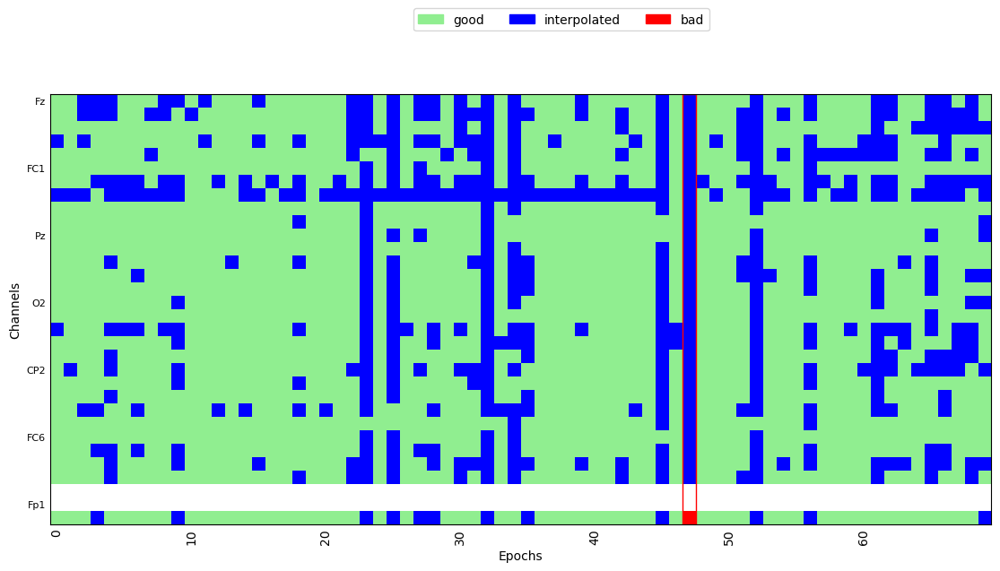

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0041_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0041_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1051579 =      0.000 ...  4206.316 secs
Ready.
Reading 0 ... 1051579  =      0.000 ...  4206.316 secs...
Not setting metadata
1973 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1973 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/428 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=1


  0%|          | Repairing epochs : 0/428 [00:00<?,       ?it/s]

Dropped 17 epochs: 51, 112, 154, 210, 232, 248, 277, 311, 351, 365, 366, 368, 369, 370, 371, 421, 422


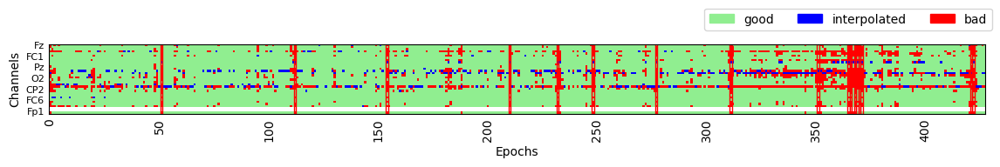

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 6


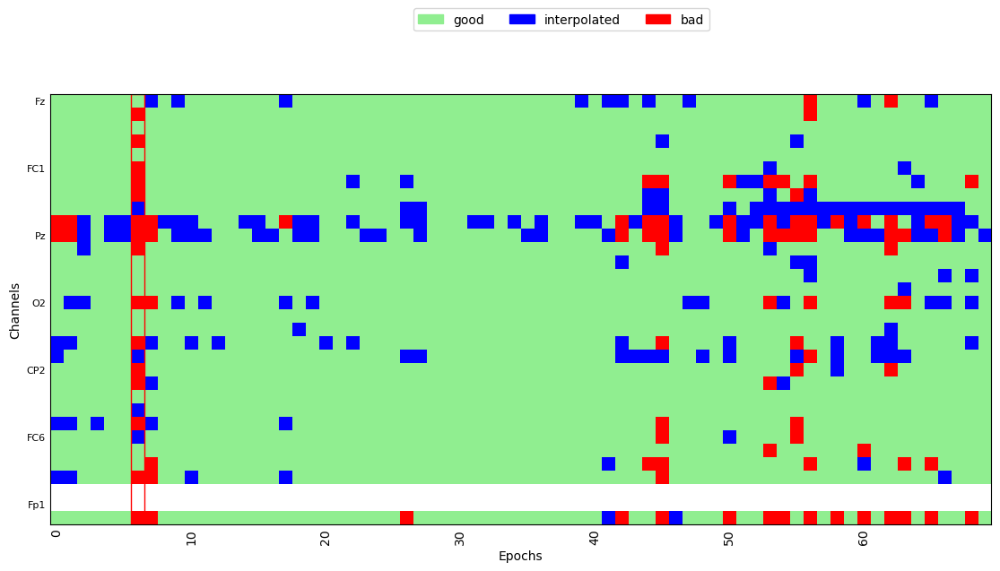

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/402 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/402 [00:00<?,       ?it/s]

Dropped 23 epochs: 1, 82, 117, 143, 144, 145, 146, 155, 156, 157, 160, 240, 301, 303, 304, 333, 341, 345, 346, 347, 369, 388, 389


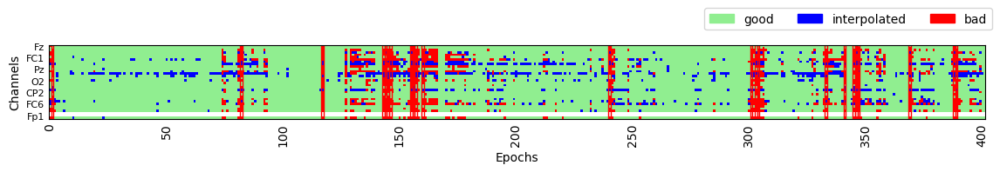

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 11 epochs: 22, 26, 27, 30, 41, 51, 55, 56, 58, 60, 67


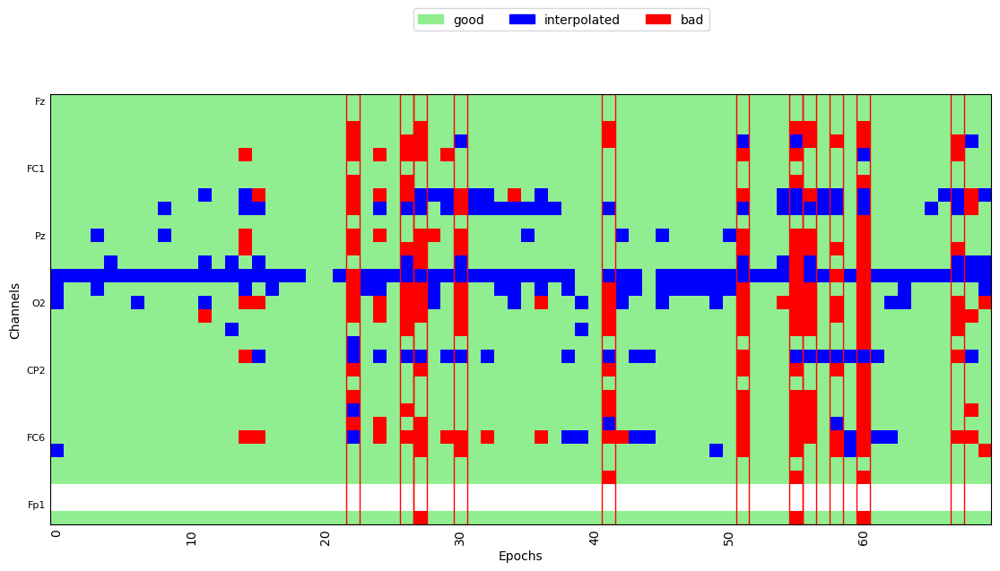

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/442 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/442 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/442 [00:00<?,       ?it/s]

Dropped 4 epochs: 53, 65, 205, 400


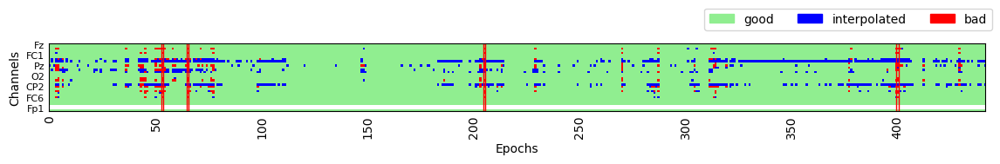

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 0, 1, 35, 62


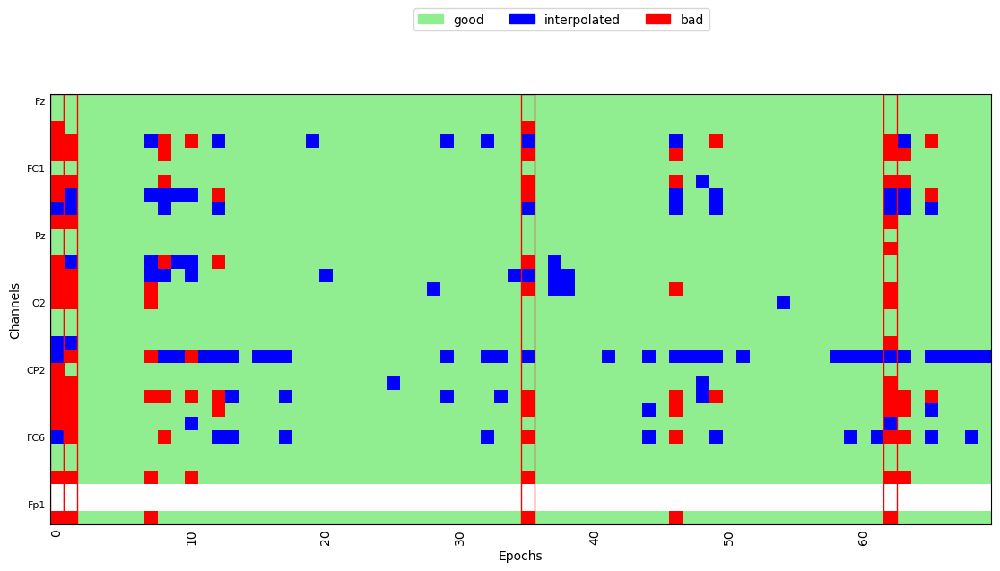

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/421 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/421 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/421 [00:00<?,       ?it/s]

Dropped 32 epochs: 2, 54, 58, 82, 83, 89, 90, 91, 92, 145, 150, 157, 158, 173, 174, 175, 186, 195, 246, 248, 263, 318, 320, 321, 322, 324, 341, 386, 392, 394, 410, 417


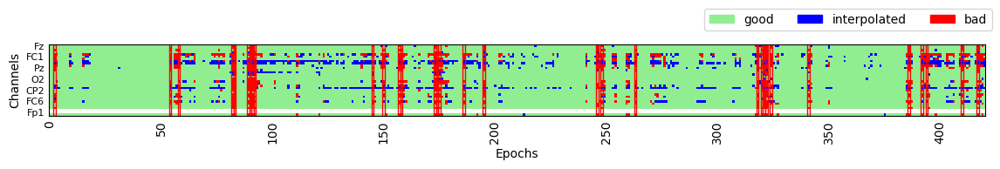

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 45


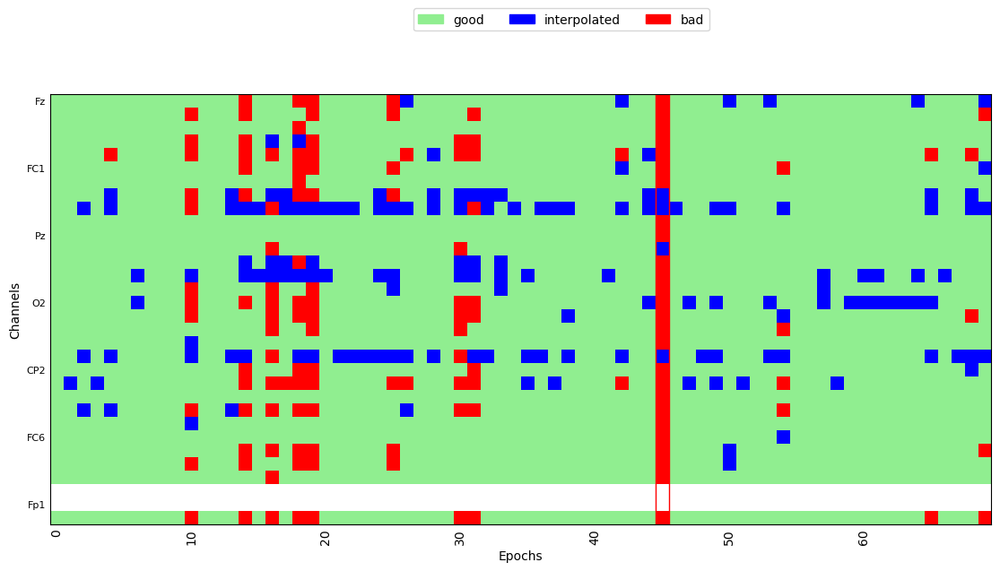

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0039_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0039_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1032639 =      0.000 ...  4130.556 secs
Ready.
Reading 0 ... 1032639  =      0.000 ...  4130.556 secs...
Not setting metadata
1923 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1923 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/409 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/409 [00:00<?,       ?it/s]

Dropped 24 epochs: 5, 17, 25, 26, 63, 73, 89, 90, 95, 106, 132, 209, 212, 271, 273, 300, 305, 306, 340, 359, 369, 375, 395, 396


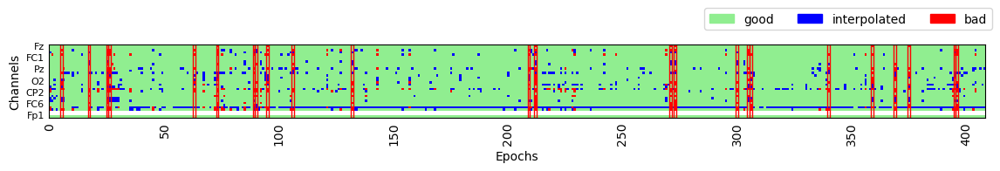

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


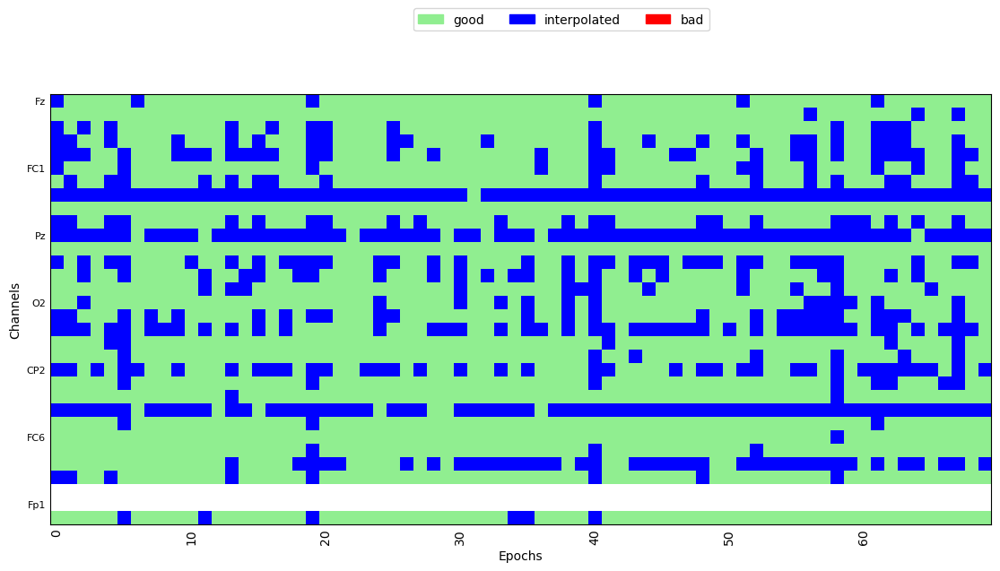

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/402 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/402 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=1


  0%|          | Repairing epochs : 0/402 [00:00<?,       ?it/s]

Dropped 14 epochs: 18, 101, 170, 177, 219, 224, 247, 295, 333, 341, 342, 376, 385, 393


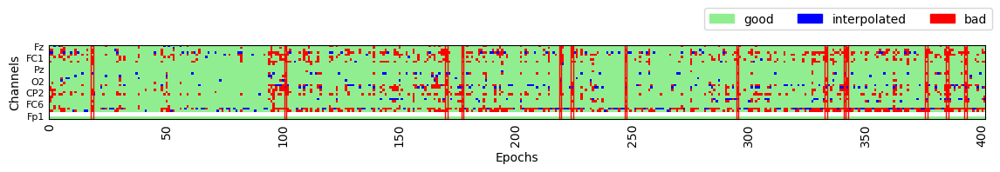

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 31, 52, 65, 67


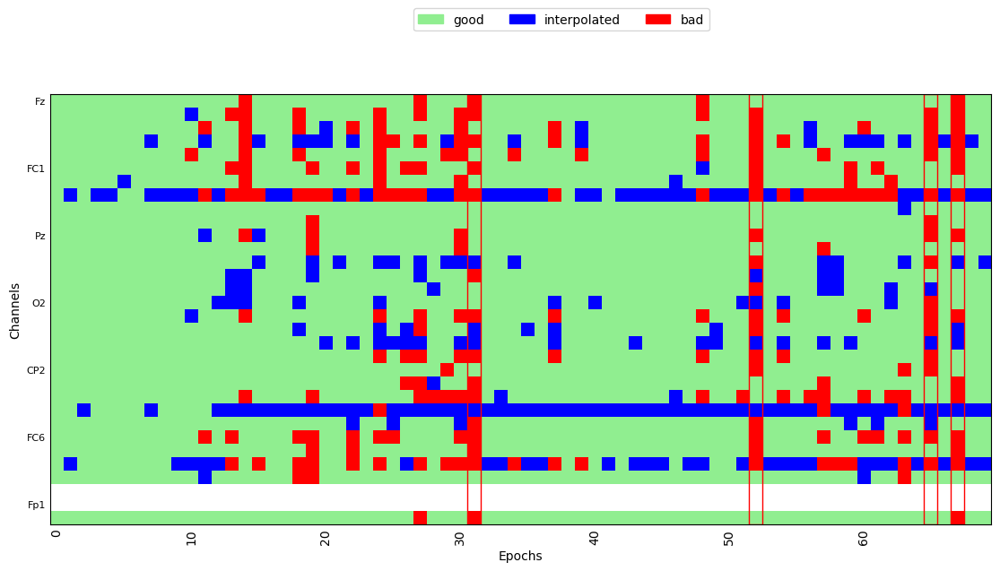

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/431 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/431 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/431 [00:00<?,       ?it/s]

Dropped 8 epochs: 4, 187, 198, 295, 297, 298, 307, 430


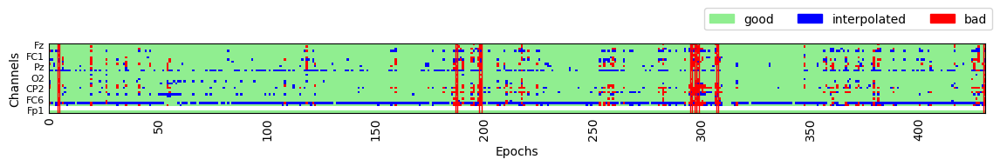

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 16, 69


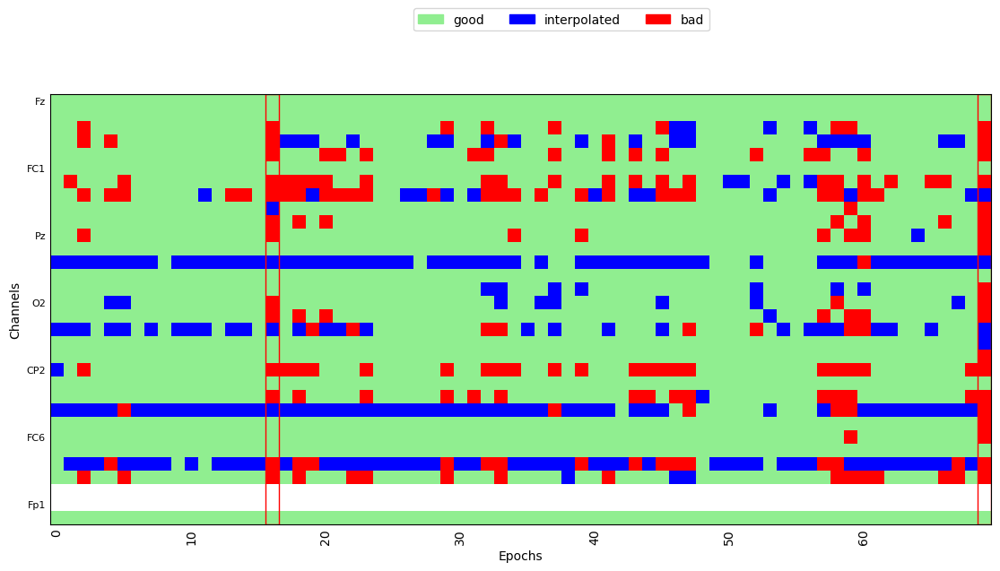

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/401 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/401 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=1


  0%|          | Repairing epochs : 0/401 [00:00<?,       ?it/s]

Dropped 31 epochs: 1, 4, 22, 23, 97, 121, 170, 190, 193, 194, 197, 212, 248, 249, 250, 261, 271, 285, 287, 327, 332, 333, 344, 350, 352, 358, 362, 363, 392, 393, 395


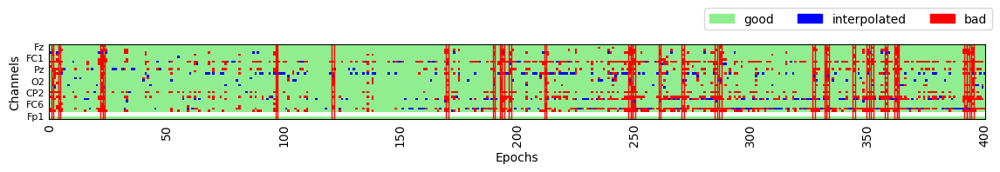

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 16 epochs: 0, 1, 4, 7, 34, 36, 43, 49, 50, 57, 60, 61, 62, 63, 68, 69


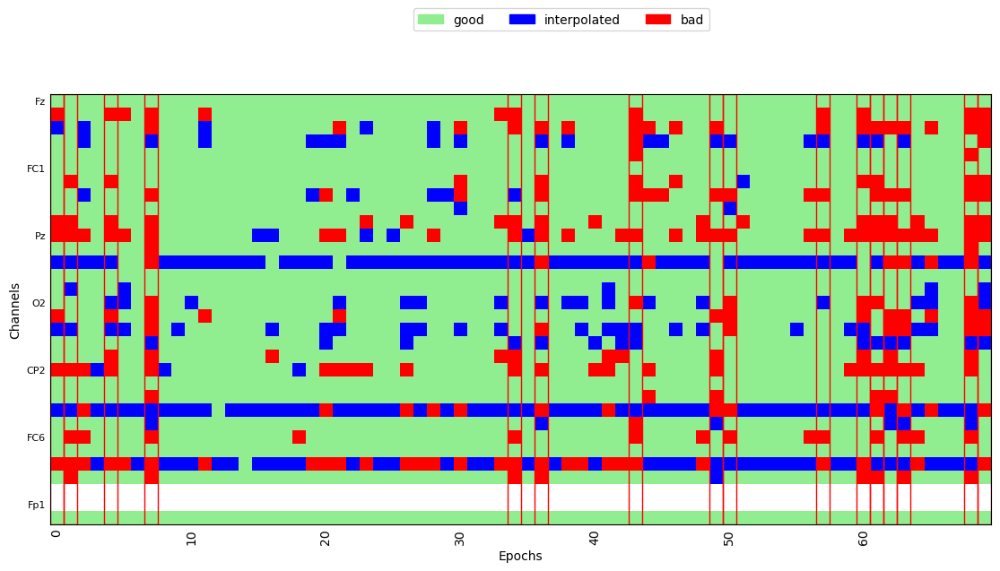

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0031_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0031_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1063019 =      0.000 ...  4252.076 secs
Ready.
Reading 0 ... 1063019  =      0.000 ...  4252.076 secs...
Not setting metadata
2011 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 2011 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/453 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/453 [00:00<?,       ?it/s]

Dropped 1 epoch: 1


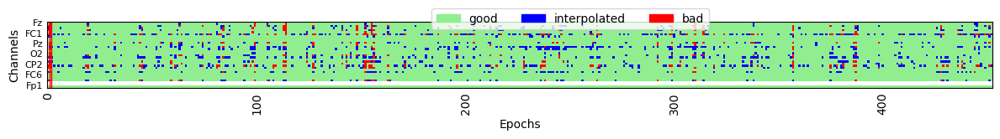

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 12, 27, 32, 66


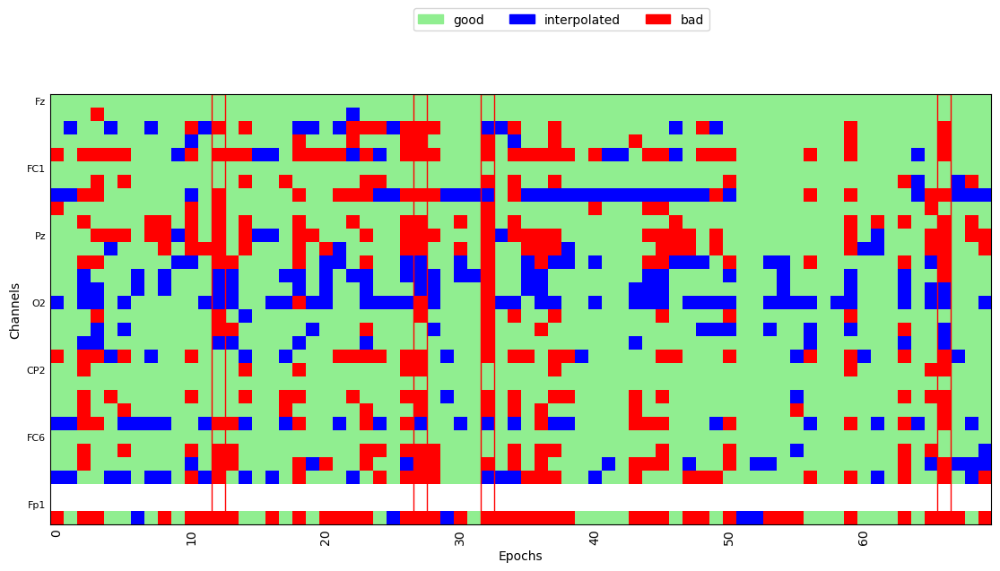

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/404 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/404 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/404 [00:00<?,       ?it/s]

Dropped 36 epochs: 12, 14, 16, 31, 32, 47, 59, 60, 61, 76, 77, 86, 92, 96, 110, 166, 181, 226, 248, 271, 286, 288, 290, 291, 294, 297, 328, 341, 362, 363, 380, 382, 383, 395, 396, 403


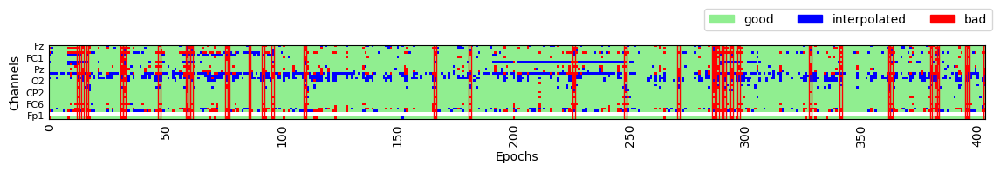

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=1


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 19


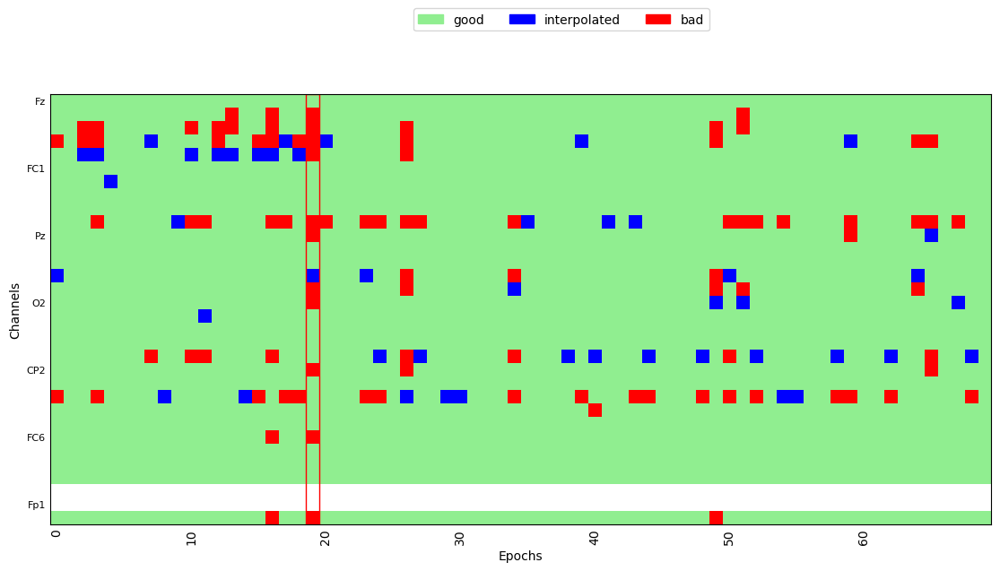

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/427 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/427 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/427 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


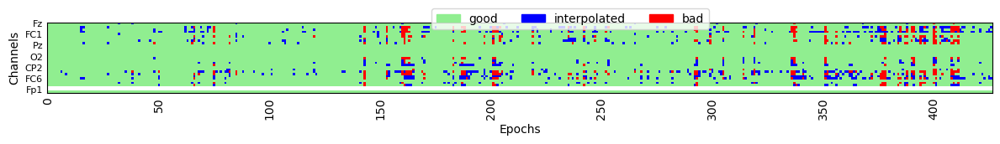

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


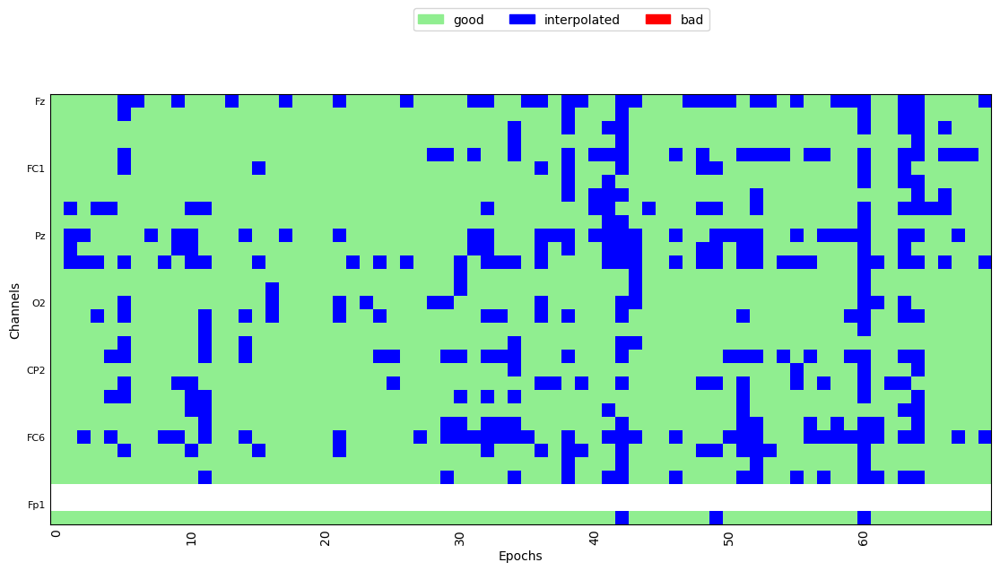

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/447 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/447 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=1


  0%|          | Repairing epochs : 0/447 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


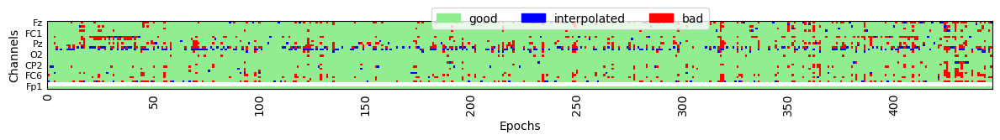

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 15 epochs: 6, 19, 20, 24, 38, 39, 40, 41, 45, 46, 48, 51, 52, 54, 62


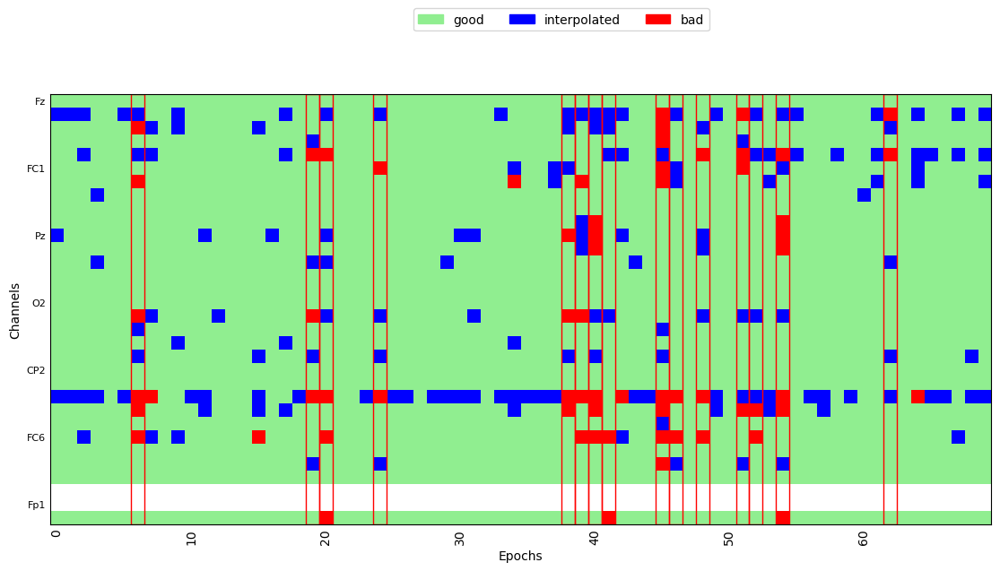

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0049_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0049_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1020879 =      0.000 ...  4083.516 secs
Ready.
Reading 0 ... 1020879  =      0.000 ...  4083.516 secs...
Not setting metadata
1923 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1923 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/397 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/397 [00:00<?,       ?it/s]

Dropped 21 epochs: 0, 1, 3, 4, 5, 6, 36, 37, 63, 64, 118, 119, 180, 181, 185, 186, 228, 261, 262, 291, 350


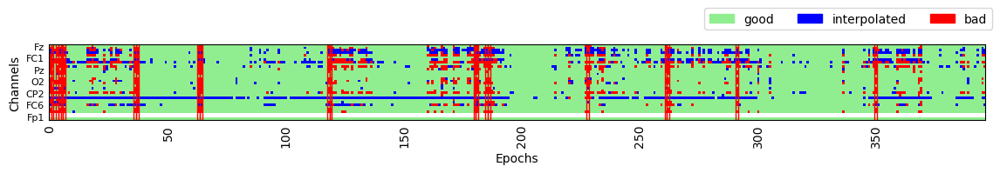

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 6 epochs: 6, 33, 38, 51, 60, 65


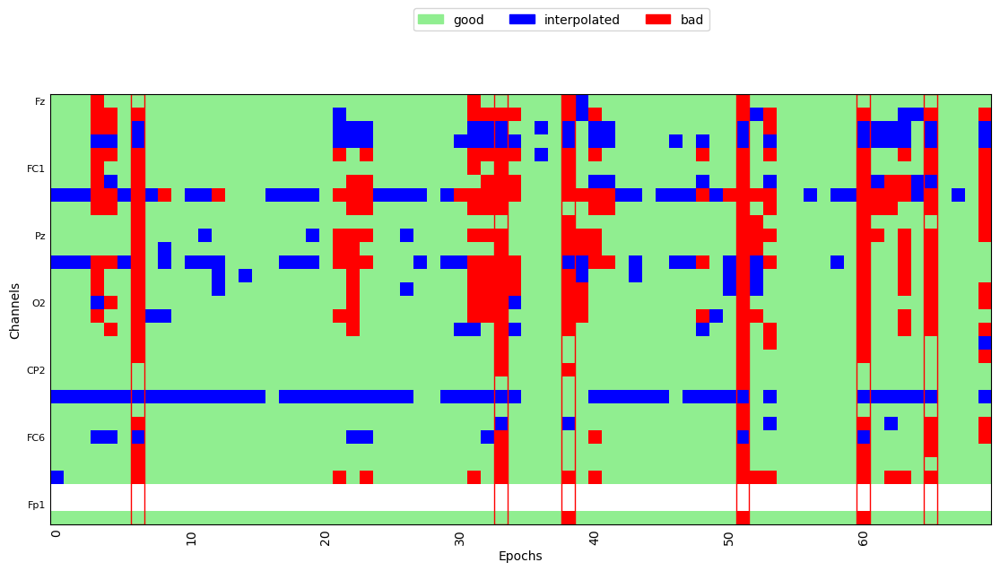

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/430 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/430 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/430 [00:00<?,       ?it/s]

Dropped 83 epochs: 6, 37, 45, 47, 48, 49, 50, 53, 73, 74, 79, 87, 88, 129, 130, 187, 188, 196, 197, 204, 211, 212, 213, 265, 266, 267, 274, 276, 278, 288, 330, 331, 332, 333, 334, 335, 336, 337, 340, 342, 343, 344, 345, 347, 348, 351, 352, 353, 355, 356, 357, 358, 359, 360, 373, 374, 375, 376, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 391, 392, 393, 395, 396, 401, 402, 410, 411, 412, 413, 414, 415, 416


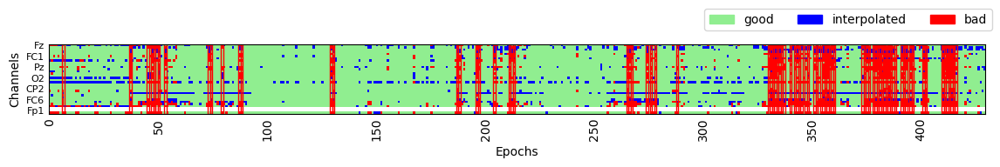

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.80 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 31, 54


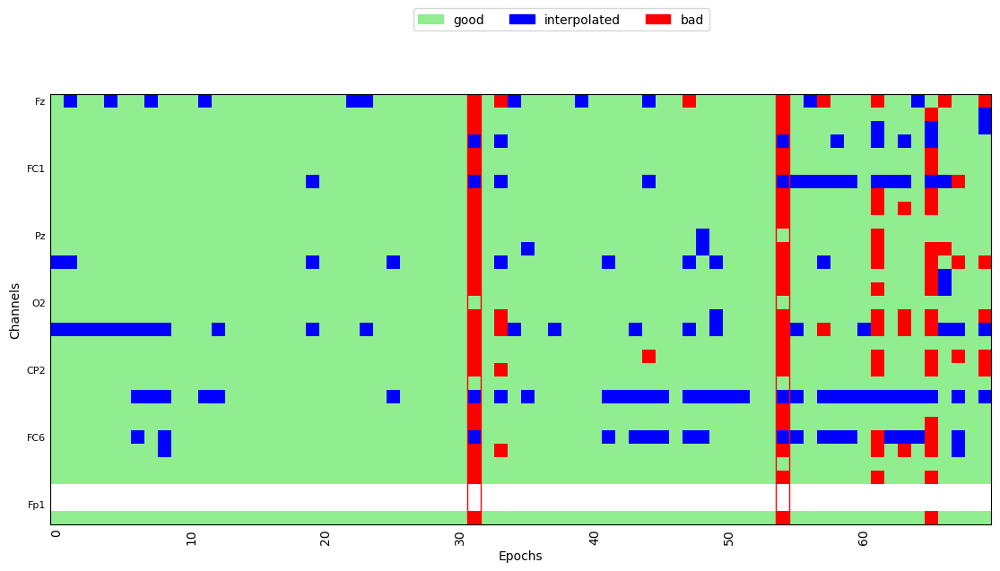

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/407 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/407 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=1


  0%|          | Repairing epochs : 0/407 [00:00<?,       ?it/s]

Dropped 25 epochs: 3, 4, 6, 7, 11, 12, 13, 52, 71, 72, 73, 74, 135, 137, 138, 139, 140, 150, 196, 312, 315, 396, 400, 401, 404


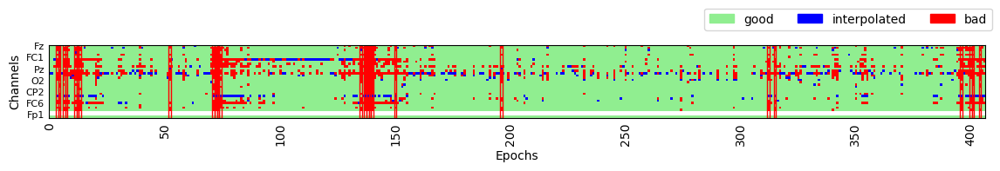

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 12, 67


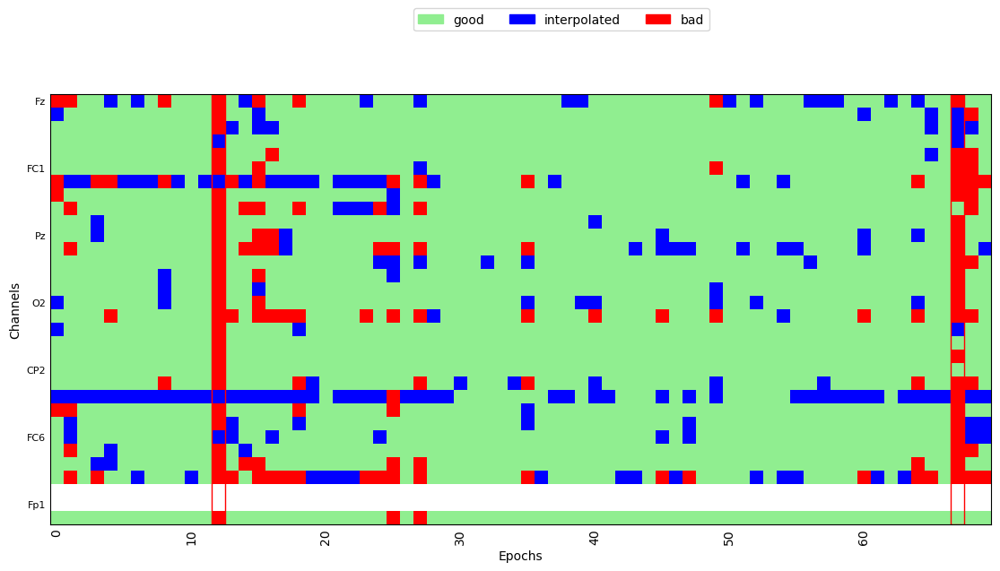

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/409 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/409 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/409 [00:00<?,       ?it/s]

Dropped 38 epochs: 0, 19, 20, 22, 101, 137, 138, 192, 210, 211, 248, 255, 259, 267, 268, 269, 270, 271, 272, 280, 292, 294, 297, 298, 299, 300, 301, 302, 303, 306, 319, 320, 321, 322, 337, 357, 358, 361


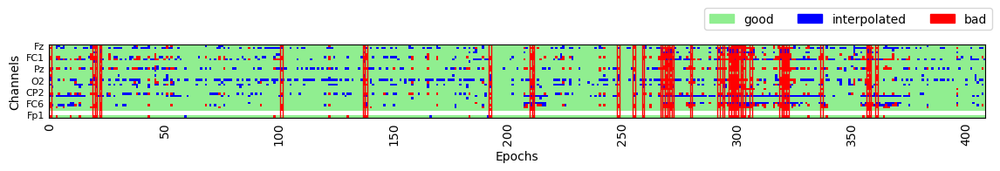

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 56


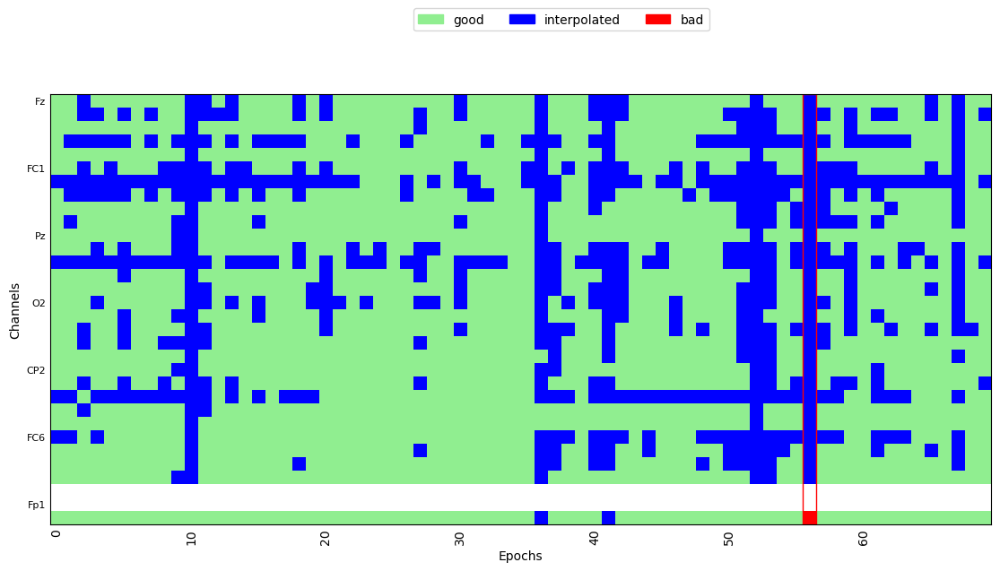

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0017_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0017_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1034384 =      0.000 ...  4137.536 secs
Ready.
Reading 0 ... 1034384  =      0.000 ...  4137.536 secs...
Not setting metadata
1962 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1962 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/407 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.90 and n_interpolate=4


  0%|          | Repairing epochs : 0/407 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


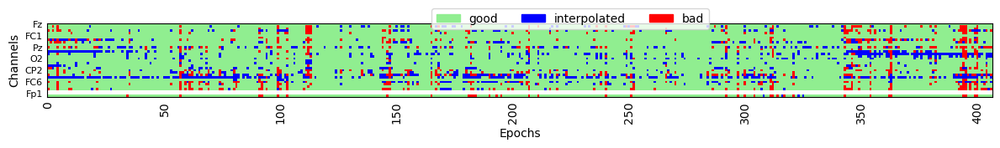

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 3 epochs: 44, 58, 69


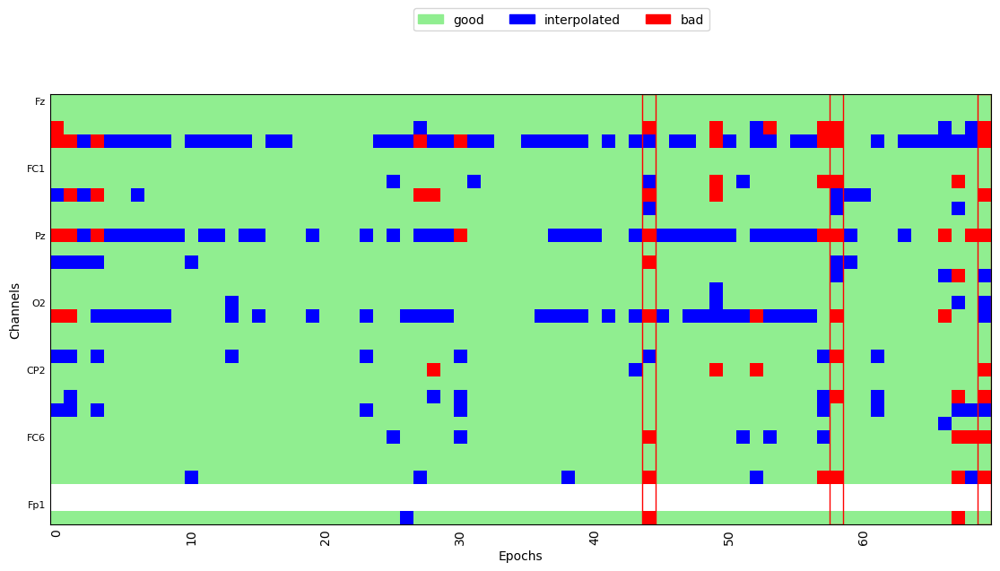

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/429 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/429 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/429 [00:00<?,       ?it/s]

Dropped 30 epochs: 20, 21, 25, 39, 40, 52, 53, 54, 63, 64, 65, 68, 73, 74, 81, 82, 94, 106, 172, 204, 239, 316, 342, 348, 360, 365, 371, 396, 410, 414


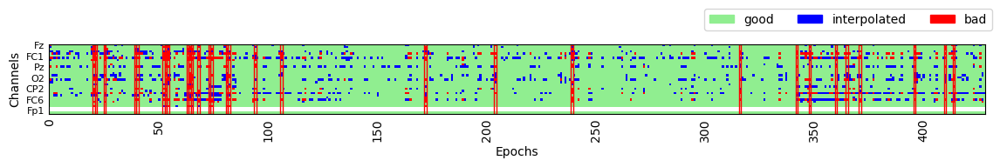

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 9, 14, 18, 39, 67


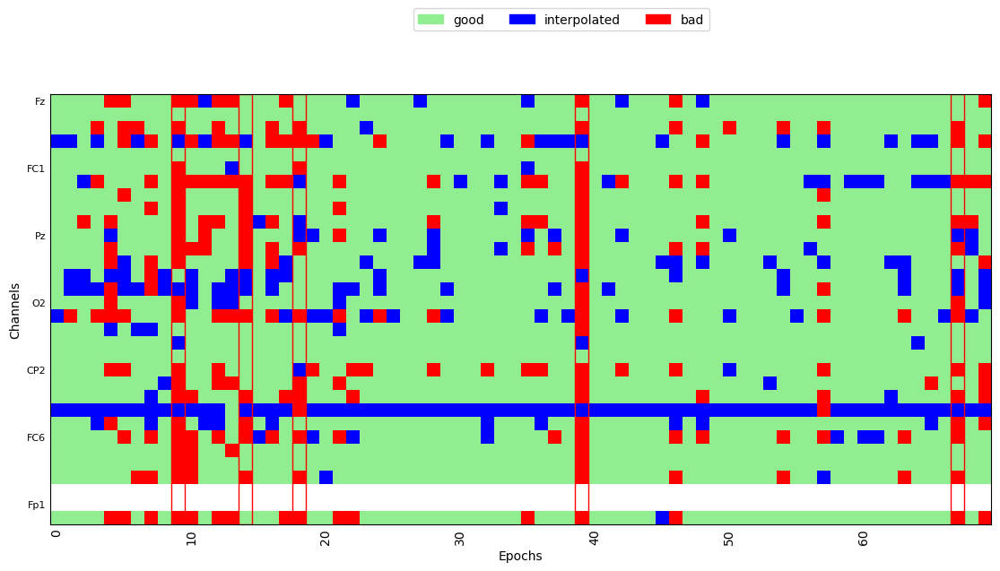

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/420 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/420 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/420 [00:00<?,       ?it/s]

Dropped 13 epochs: 6, 7, 23, 96, 205, 313, 314, 325, 326, 327, 329, 346, 418


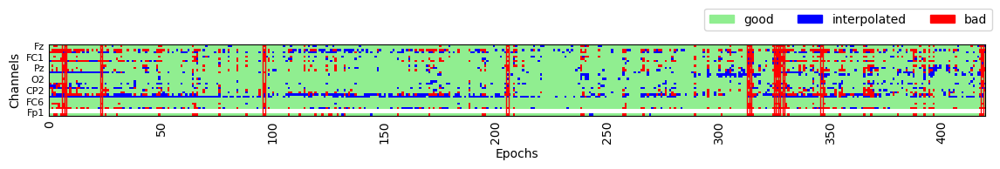

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 52, 64


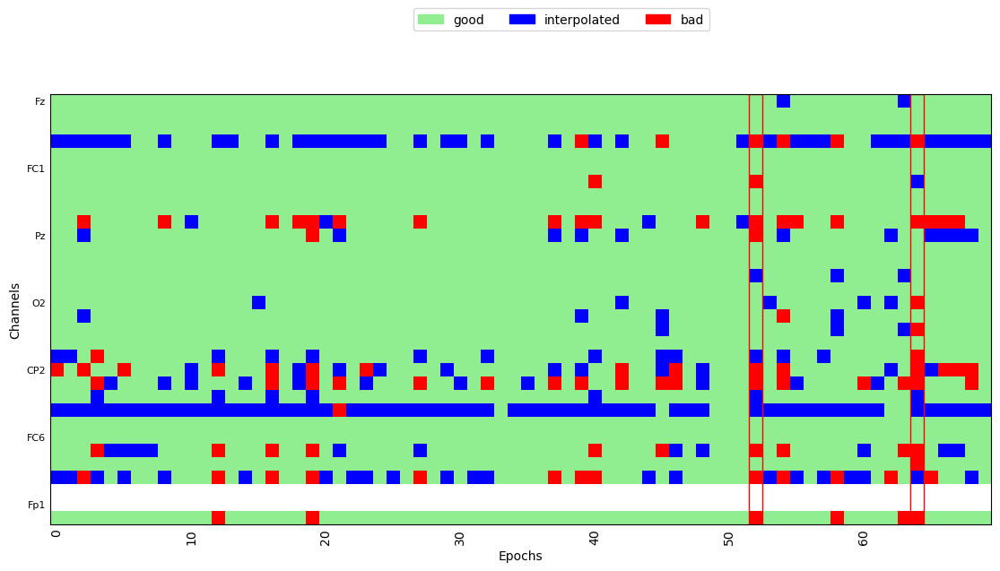

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/426 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/426 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/426 [00:00<?,       ?it/s]

Dropped 3 epochs: 63, 250, 351


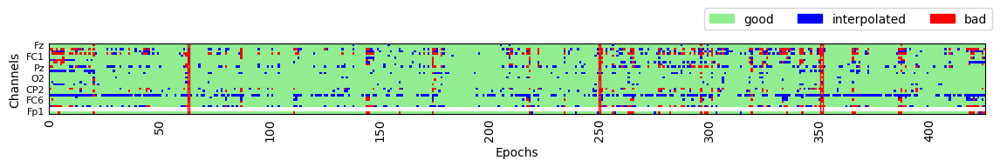

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 26, 54


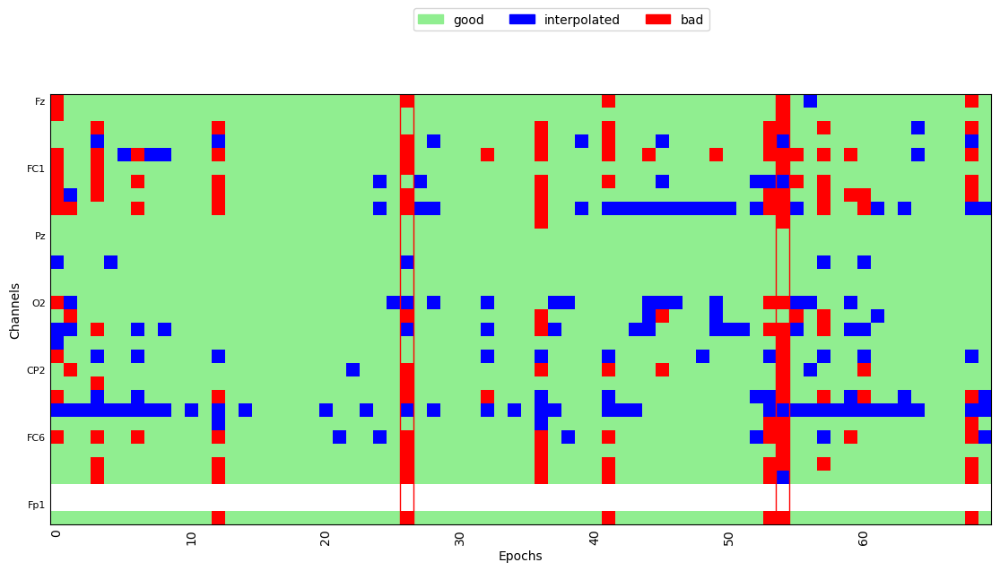

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0033_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0033_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1052734 =      0.000 ...  4210.936 secs
Ready.
Reading 0 ... 1052734  =      0.000 ...  4210.936 secs...
Not setting metadata
1962 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1962 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/441 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/441 [00:00<?,       ?it/s]

Dropped 35 epochs: 0, 1, 2, 3, 10, 26, 27, 120, 186, 193, 194, 218, 235, 245, 248, 249, 266, 270, 282, 344, 363, 376, 377, 386, 387, 389, 390, 401, 402, 425, 426, 427, 429, 436, 438


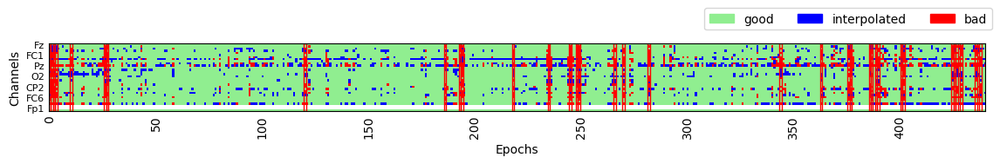

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.80 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 0, 51, 60, 62


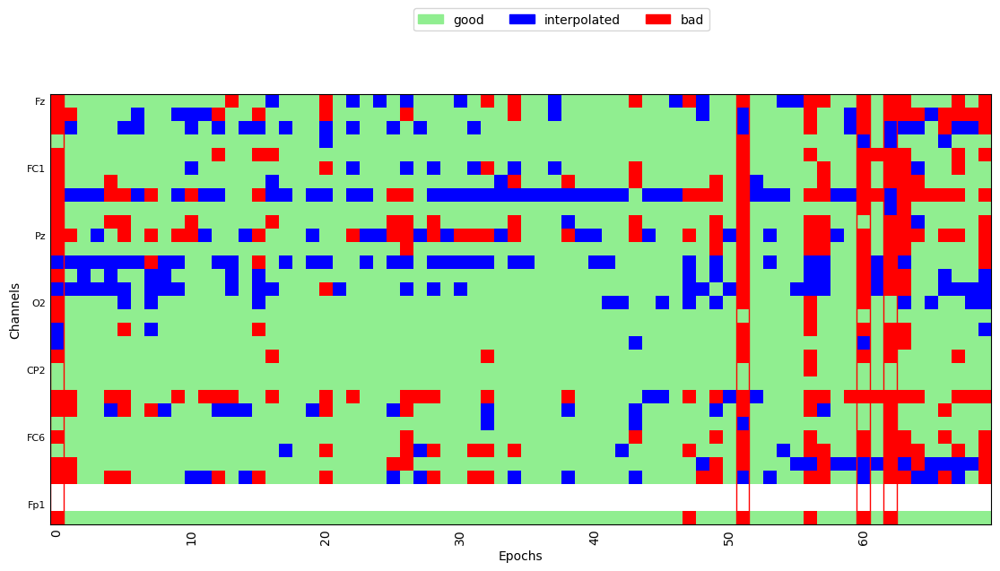

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/425 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/425 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/425 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


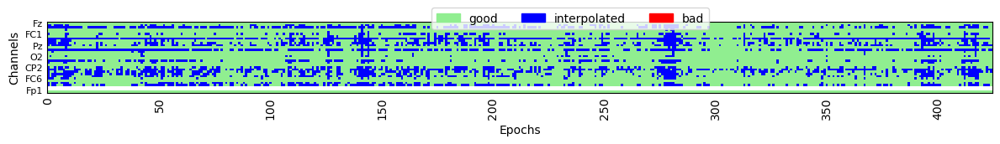

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 16 epochs: 0, 8, 9, 10, 14, 17, 25, 26, 27, 35, 37, 43, 50, 63, 66, 69


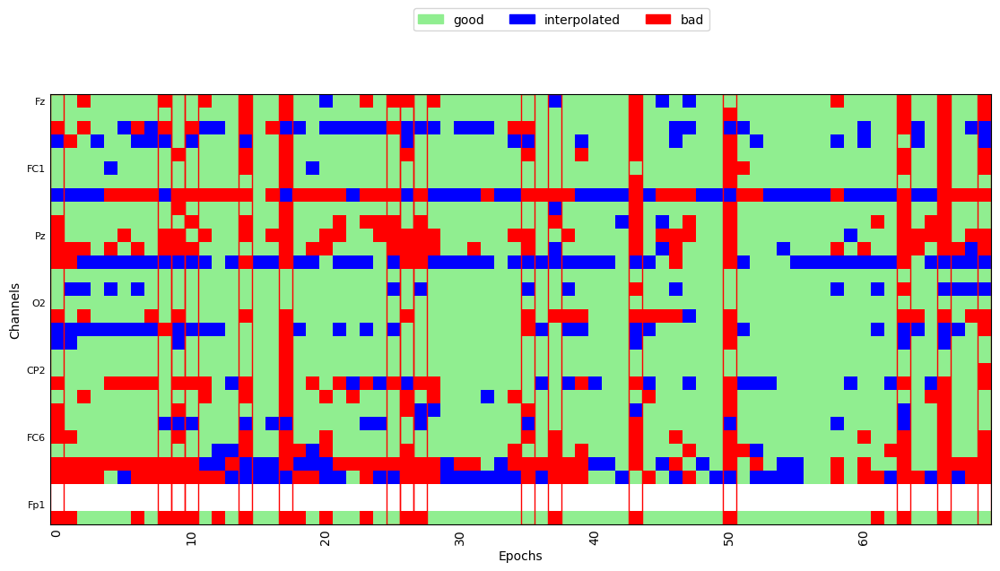

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/412 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/412 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/412 [00:00<?,       ?it/s]

Dropped 46 epochs: 61, 69, 73, 74, 75, 77, 78, 110, 121, 122, 123, 145, 165, 174, 175, 202, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 241, 242, 262, 263, 278, 281, 293, 294, 313, 314, 315


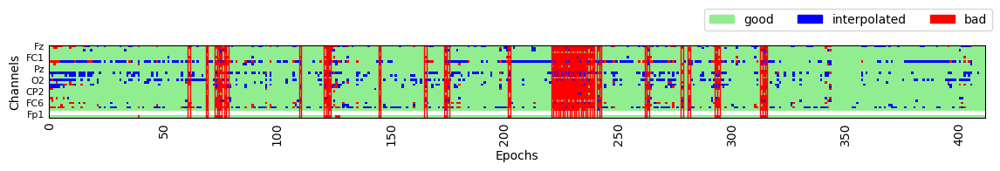

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 7 epochs: 21, 40, 41, 42, 46, 51, 67


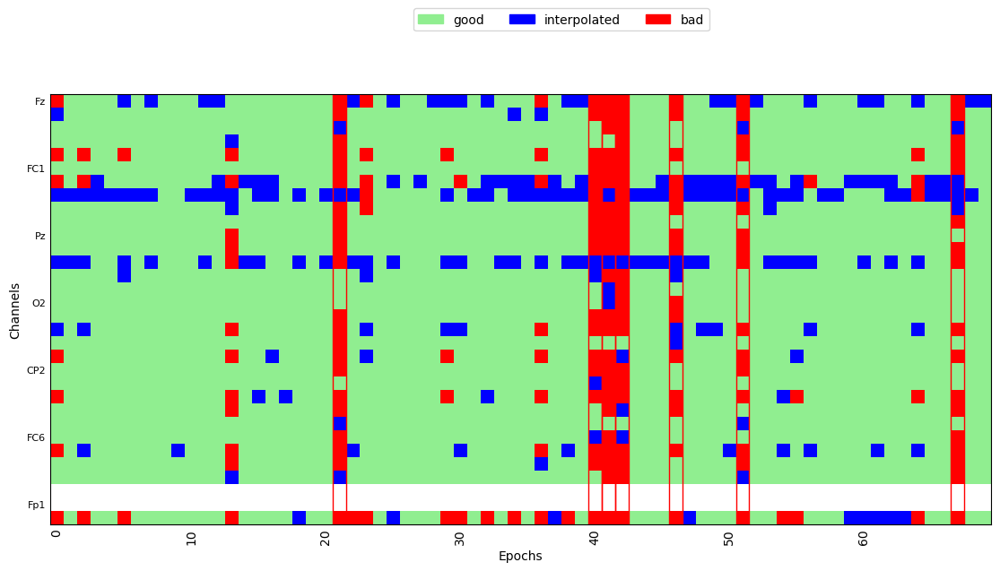

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/404 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=1


  0%|          | Repairing epochs : 0/404 [00:00<?,       ?it/s]

Dropped 64 epochs: 0, 1, 2, 3, 5, 6, 7, 27, 28, 82, 85, 86, 87, 88, 89, 94, 95, 111, 112, 125, 143, 144, 145, 146, 147, 153, 178, 181, 186, 187, 197, 202, 203, 204, 205, 206, 234, 236, 246, 264, 265, 272, 273, 274, 275, 276, 277, 300, 301, 304, 356, 357, 358, 359, 369, 370, 377, 381, 389, 390, 391, 396, 397, 400


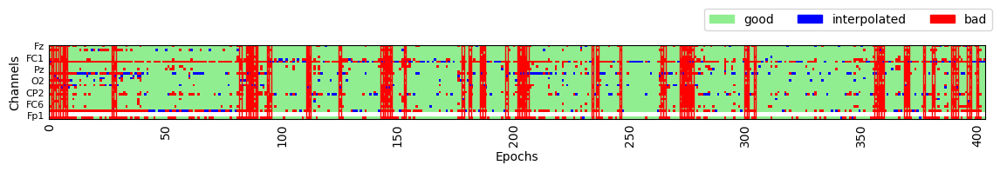

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 10 epochs: 0, 33, 38, 39, 43, 50, 51, 54, 59, 65


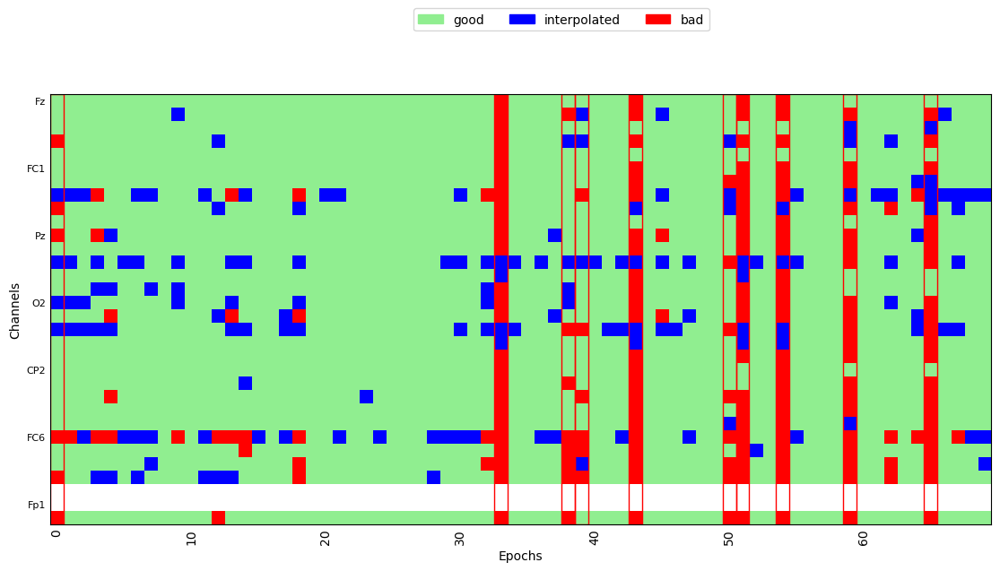

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0019_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0019_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1036644 =      0.000 ...  4146.576 secs
Ready.
Reading 0 ... 1036644  =      0.000 ...  4146.576 secs...
Not setting metadata
1949 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1949 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/439 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/439 [00:00<?,       ?it/s]

Dropped 15 epochs: 39, 101, 102, 132, 152, 154, 171, 172, 215, 234, 238, 245, 338, 402, 420


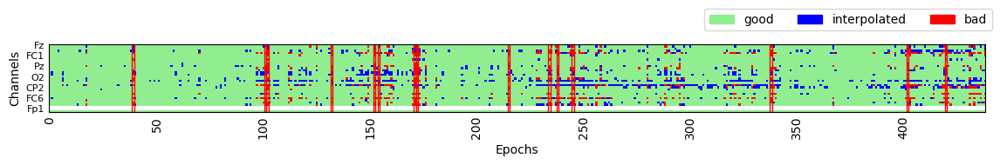

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.80 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


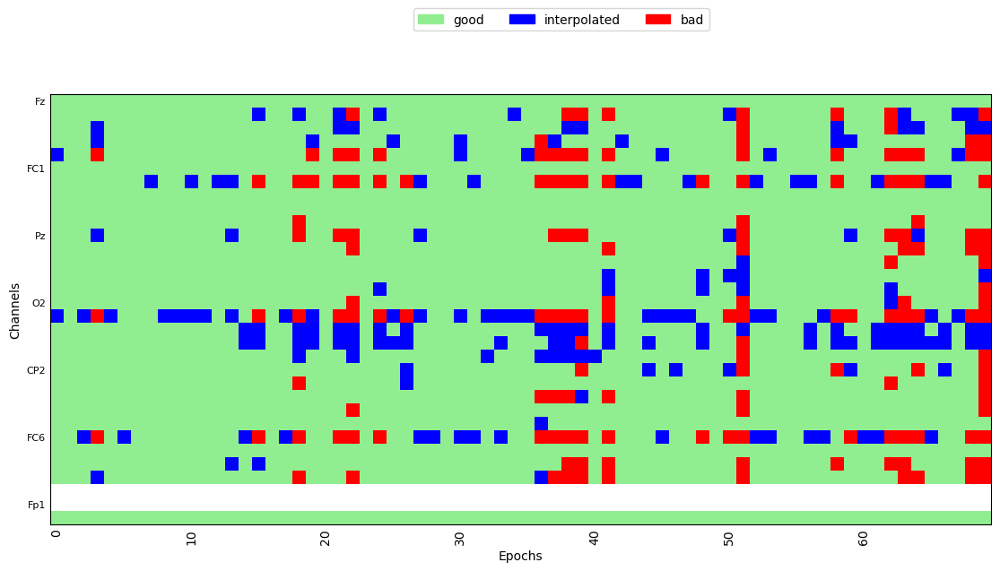

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/409 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/409 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=1


  0%|          | Repairing epochs : 0/409 [00:00<?,       ?it/s]

Dropped 29 epochs: 51, 53, 78, 121, 140, 176, 177, 179, 188, 189, 197, 198, 250, 251, 319, 322, 325, 345, 350, 385, 387, 388, 389, 390, 391, 401, 405, 406, 407


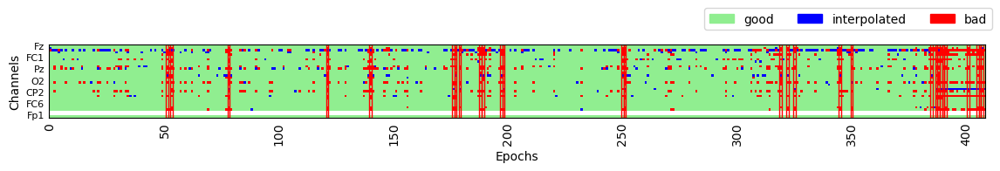

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 9, 11, 20, 59


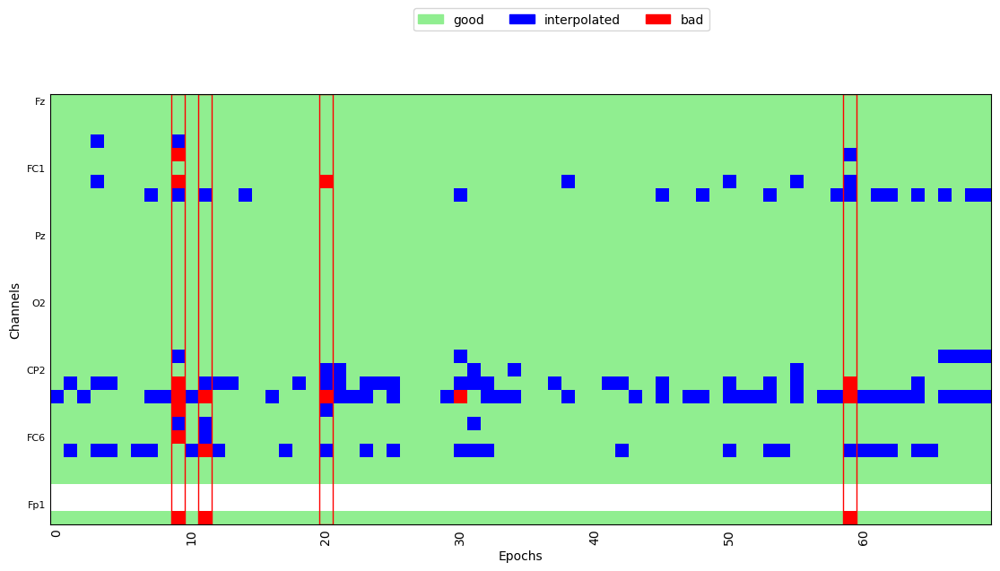

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/401 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/401 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=1


  0%|          | Repairing epochs : 0/401 [00:00<?,       ?it/s]

Dropped 7 epochs: 122, 210, 219, 357, 360, 361, 366


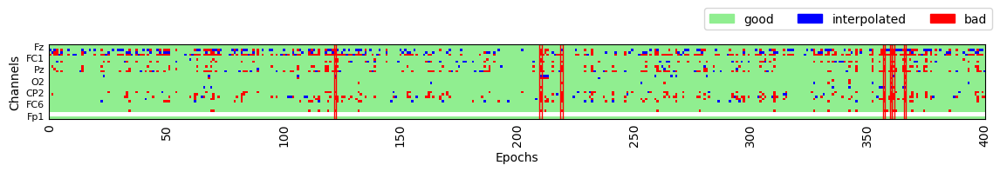

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=1


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


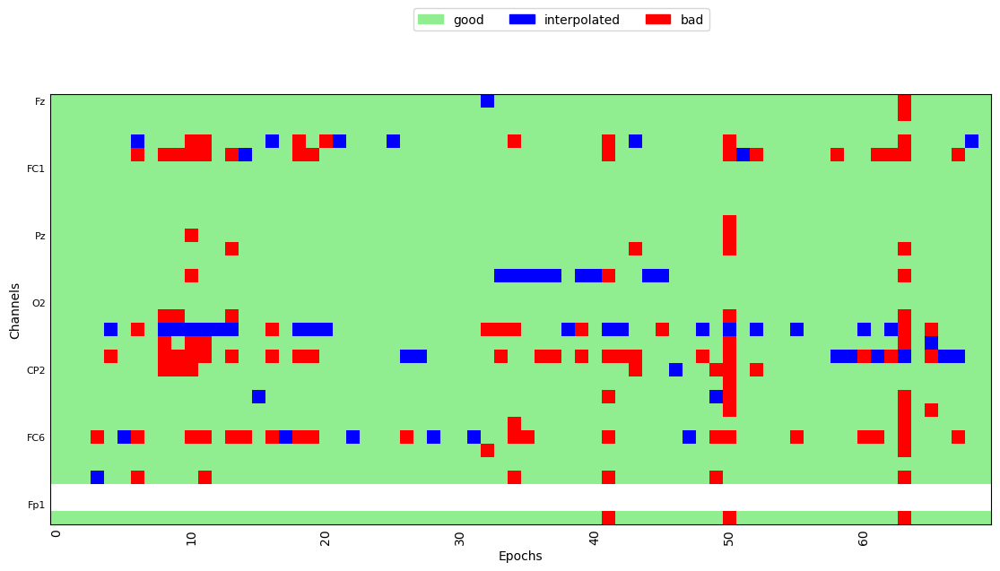

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/420 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/420 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=1


  0%|          | Repairing epochs : 0/420 [00:00<?,       ?it/s]

Dropped 14 epochs: 5, 8, 29, 33, 111, 139, 177, 217, 238, 256, 273, 282, 338, 406


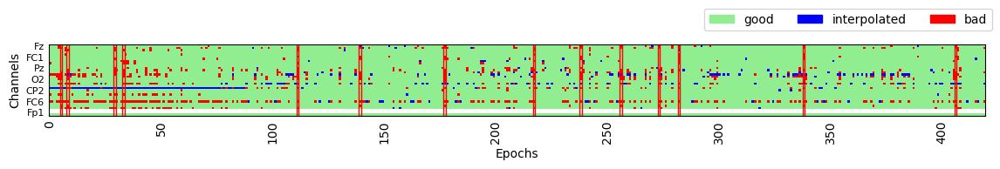

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


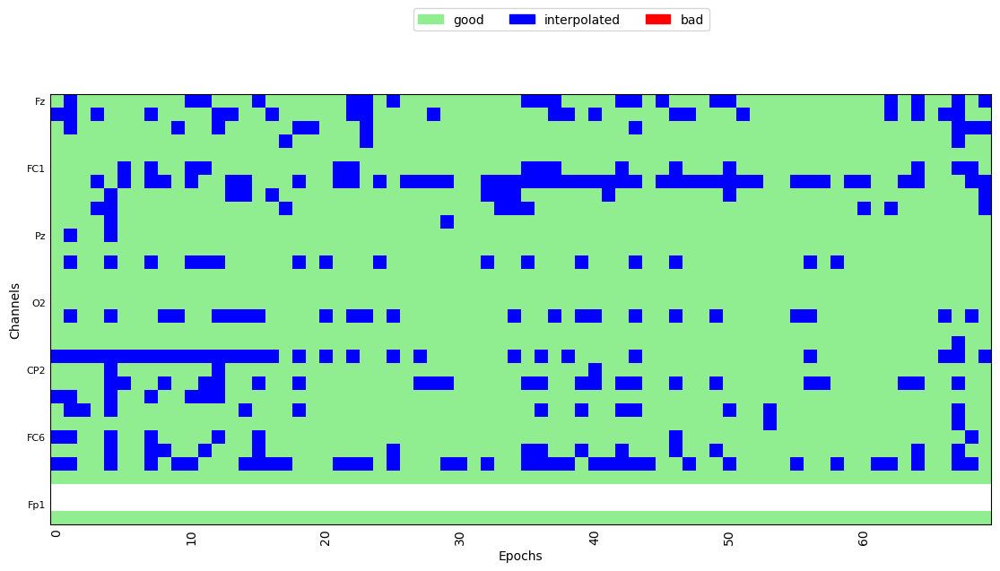

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0035_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0035_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1046744 =      0.000 ...  4186.976 secs
Ready.
Reading 0 ... 1046744  =      0.000 ...  4186.976 secs...
Not setting metadata
1976 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1976 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/436 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/436 [00:00<?,       ?it/s]

Dropped 15 epochs: 40, 168, 211, 251, 300, 301, 302, 340, 341, 360, 361, 423, 424, 425, 434


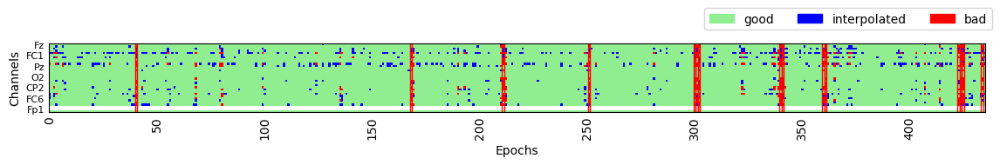

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 3 epochs: 18, 39, 47


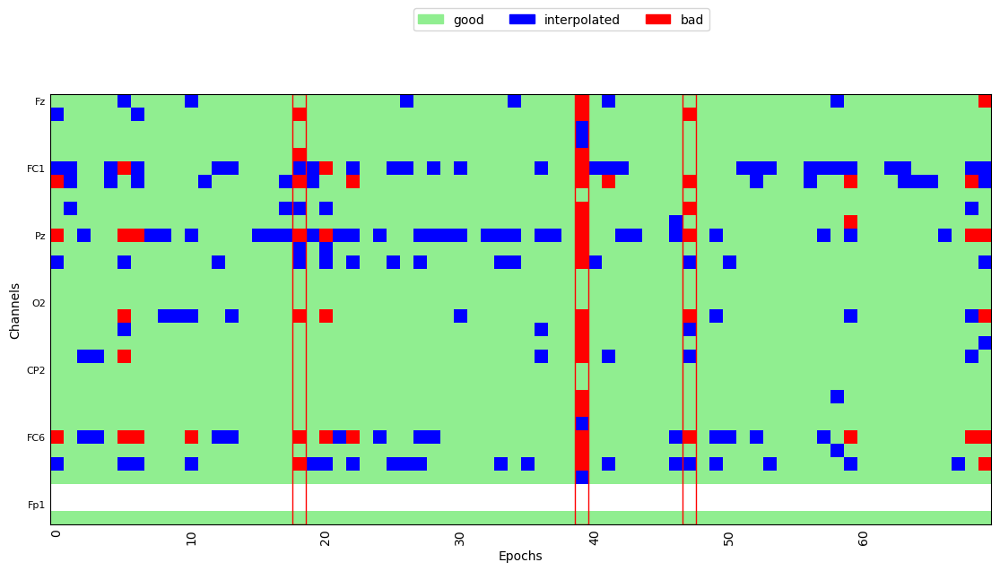

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/447 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/447 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/447 [00:00<?,       ?it/s]

Dropped 29 epochs: 0, 1, 3, 5, 6, 7, 8, 9, 10, 12, 27, 35, 43, 50, 66, 69, 165, 206, 207, 208, 215, 281, 282, 371, 378, 381, 415, 421, 444


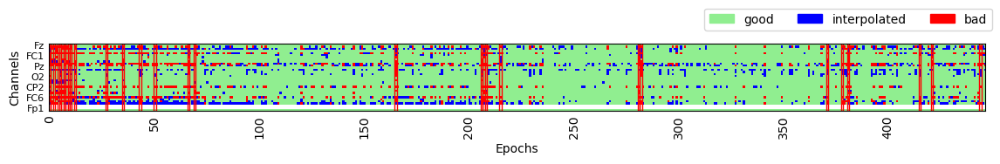

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 8 epochs: 0, 1, 2, 6, 9, 42, 43, 52


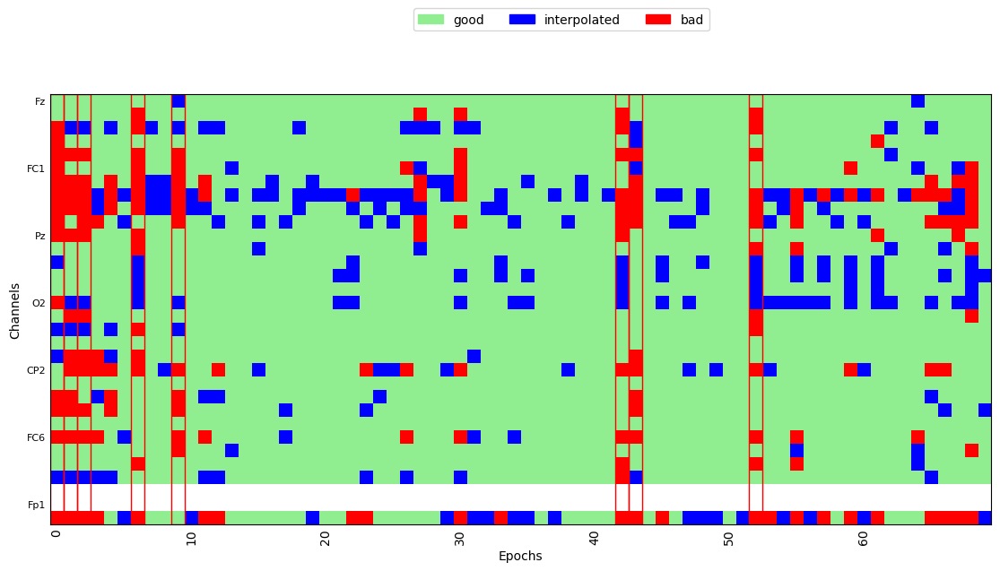

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/403 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/403 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/403 [00:00<?,       ?it/s]

Dropped 48 epochs: 78, 83, 91, 92, 93, 107, 108, 110, 117, 118, 119, 148, 149, 179, 180, 181, 226, 234, 235, 236, 238, 239, 257, 258, 286, 299, 300, 301, 302, 309, 310, 311, 360, 361, 362, 363, 364, 366, 367, 368, 369, 378, 394, 396, 397, 398, 399, 402


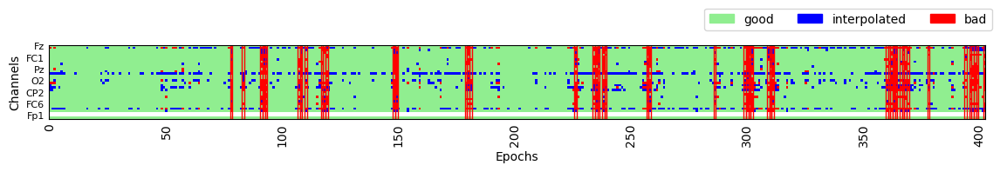

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 9 epochs: 9, 13, 30, 40, 51, 52, 63, 67, 68


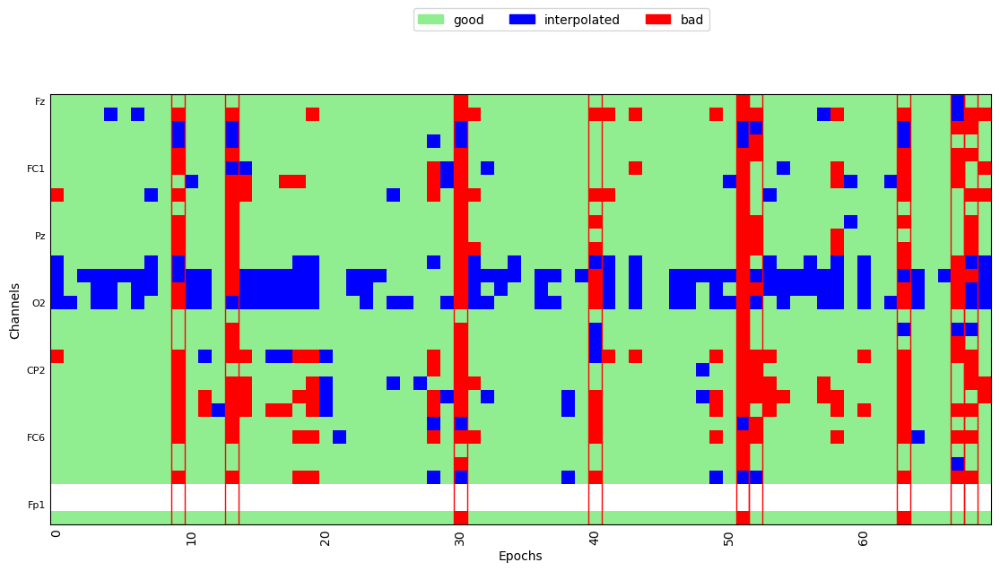

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/410 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/410 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=1


  0%|          | Repairing epochs : 0/410 [00:00<?,       ?it/s]

Dropped 46 epochs: 37, 39, 70, 71, 72, 135, 137, 140, 146, 147, 160, 162, 169, 170, 172, 173, 174, 185, 197, 210, 211, 212, 213, 215, 217, 218, 220, 221, 222, 245, 256, 259, 261, 262, 263, 284, 292, 300, 301, 302, 303, 338, 366, 368, 408, 409


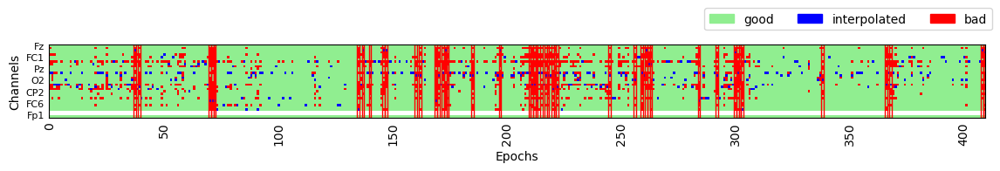

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 18 epochs: 7, 8, 12, 13, 25, 33, 34, 37, 38, 41, 42, 44, 48, 49, 51, 52, 60, 69


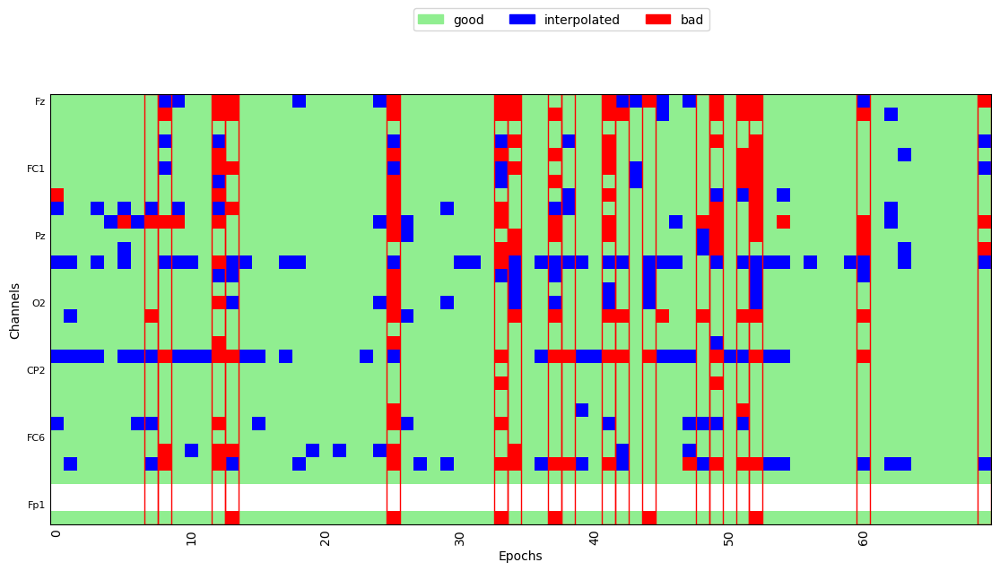

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0045_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0045_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1055834 =      0.000 ...  4223.336 secs
Ready.
Reading 0 ... 1055834  =      0.000 ...  4223.336 secs...
Not setting metadata
1990 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1990 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/441 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/441 [00:00<?,       ?it/s]

Dropped 66 epochs: 0, 5, 6, 7, 15, 59, 60, 63, 85, 86, 87, 88, 91, 92, 93, 94, 95, 96, 97, 100, 101, 102, 104, 119, 120, 121, 122, 123, 133, 191, 192, 193, 194, 198, 203, 240, 263, 264, 265, 266, 314, 315, 316, 317, 331, 332, 333, 334, 336, 337, 338, 339, 340, 349, 354, 355, 356, 360, 367, 387, 389, 405, 406, 416, 418, 422


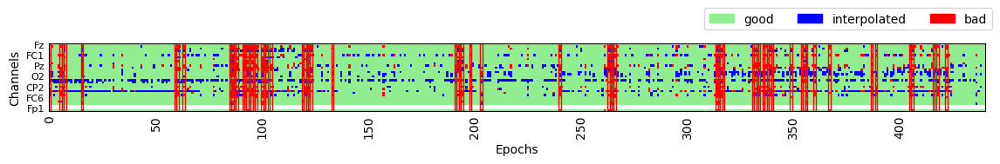

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


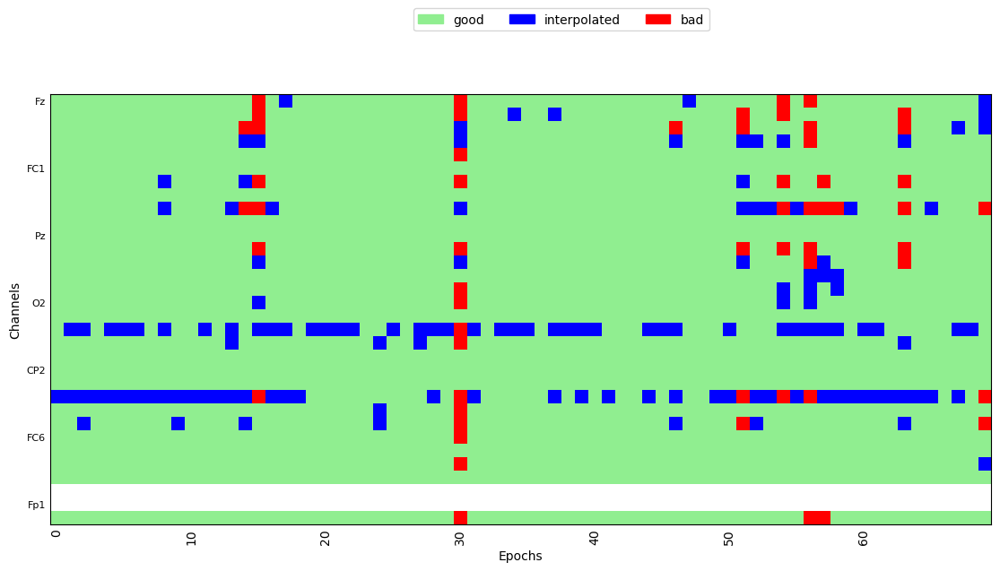

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/428 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/428 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/428 [00:00<?,       ?it/s]

Dropped 12 epochs: 14, 29, 32, 100, 101, 121, 122, 123, 311, 313, 375, 415


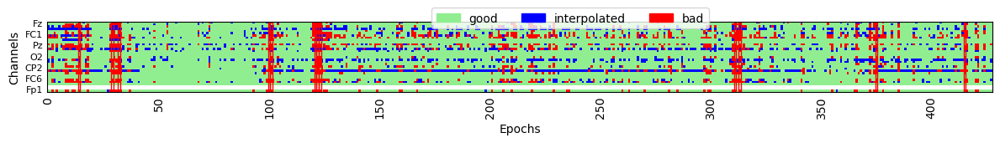

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 0, 3, 17, 34


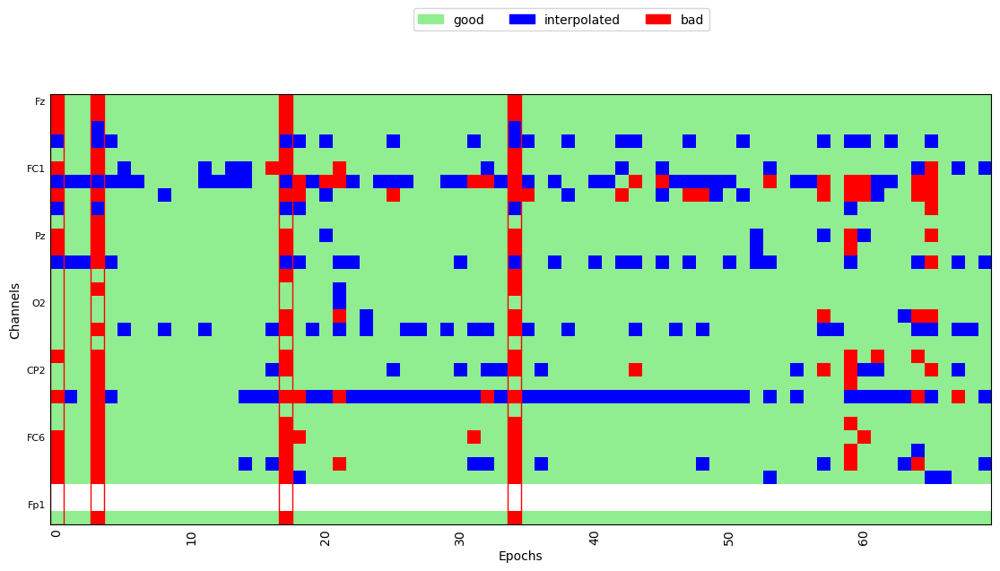

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/414 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/414 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/414 [00:00<?,       ?it/s]

Dropped 3 epochs: 144, 224, 338


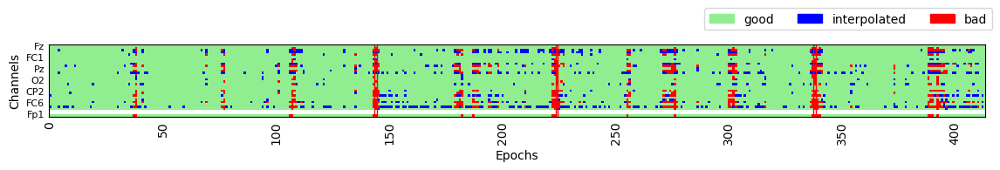

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


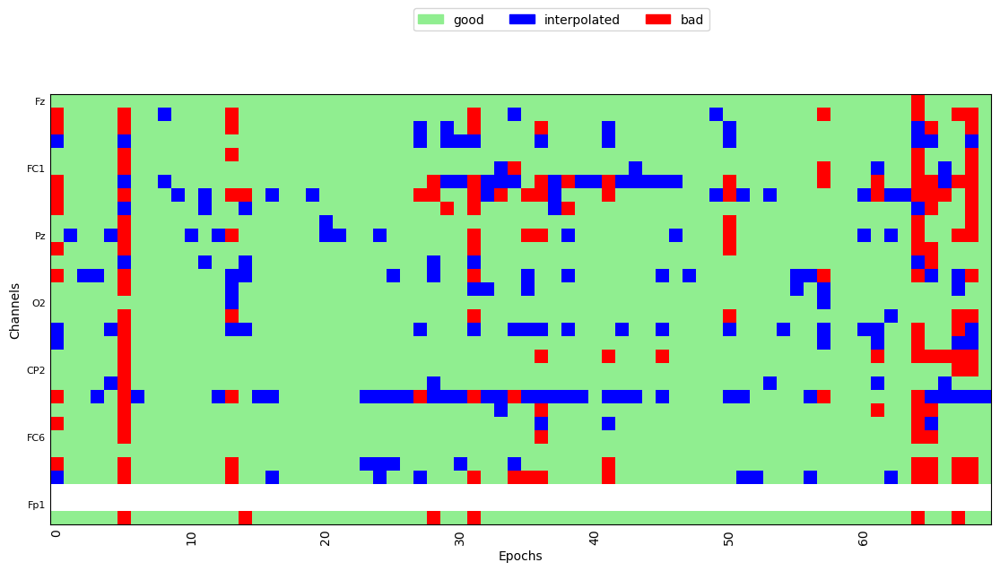

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/427 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/427 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/427 [00:00<?,       ?it/s]

Dropped 65 epochs: 0, 4, 34, 35, 40, 41, 42, 43, 47, 77, 84, 85, 92, 99, 109, 121, 127, 130, 143, 150, 168, 169, 170, 175, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 212, 214, 217, 247, 248, 249, 250, 265, 293, 300, 305, 306, 320, 333, 334, 335, 336, 337, 338, 341, 366, 374, 378, 380, 384, 389, 390, 396, 399, 414, 418


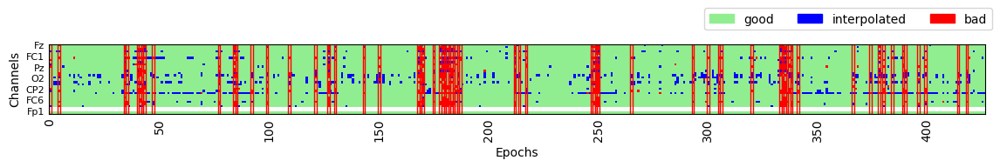

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 8 epochs: 5, 7, 12, 14, 18, 41, 48, 61


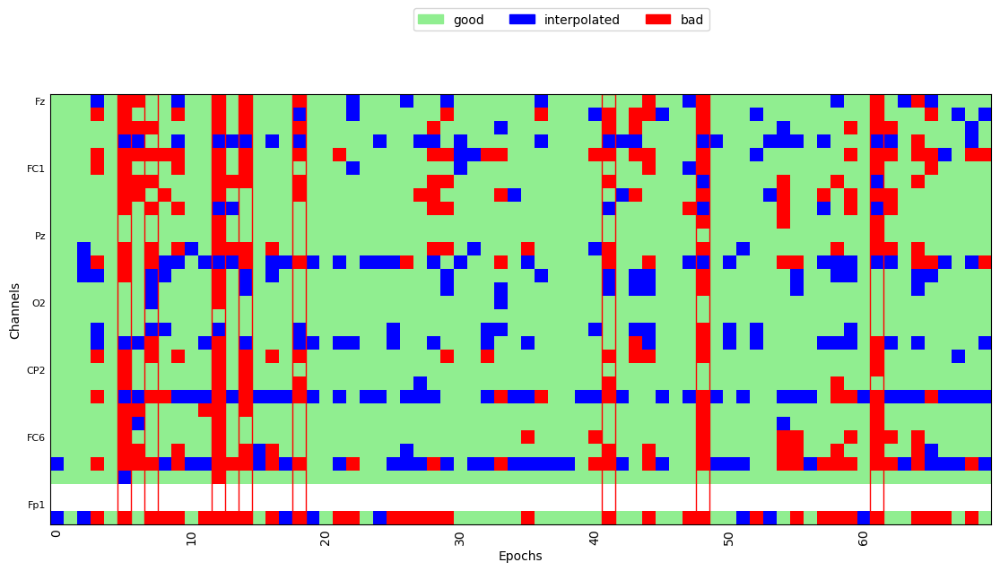

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0021_VOT_corr_prep_ica.fif...
    Range : 0 ... 1049609 =      0.000 ...  4198.436 secs
Ready.


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0021_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


Reading 0 ... 1049609  =      0.000 ...  4198.436 secs...
Not setting metadata
1994 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1994 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/435 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/435 [00:00<?,       ?it/s]

Dropped 5 epochs: 165, 207, 336, 339, 340


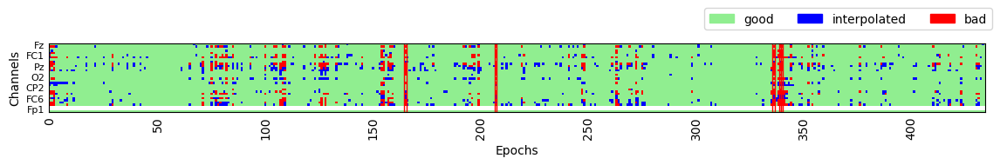

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=1


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 9 epochs: 10, 18, 20, 22, 23, 38, 54, 57, 66


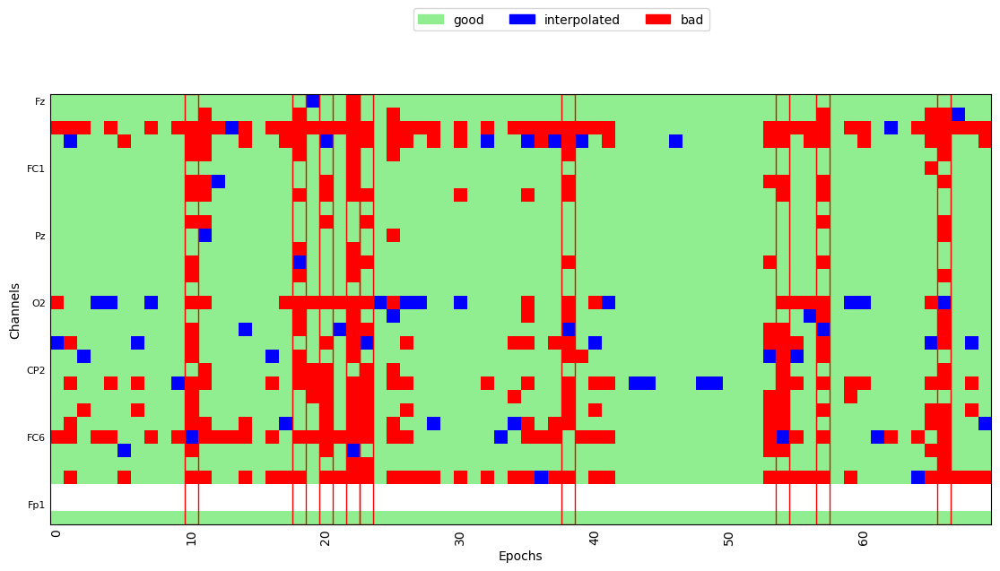

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/426 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/426 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/426 [00:00<?,       ?it/s]

Dropped 27 epochs: 0, 1, 2, 24, 42, 43, 44, 45, 46, 47, 99, 108, 112, 113, 141, 182, 184, 186, 187, 197, 198, 239, 268, 296, 312, 315, 418


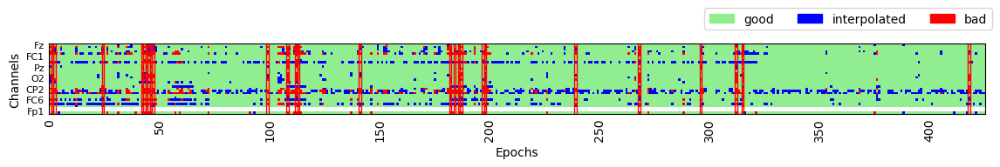

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 11 epochs: 2, 4, 7, 10, 13, 18, 30, 31, 42, 47, 50


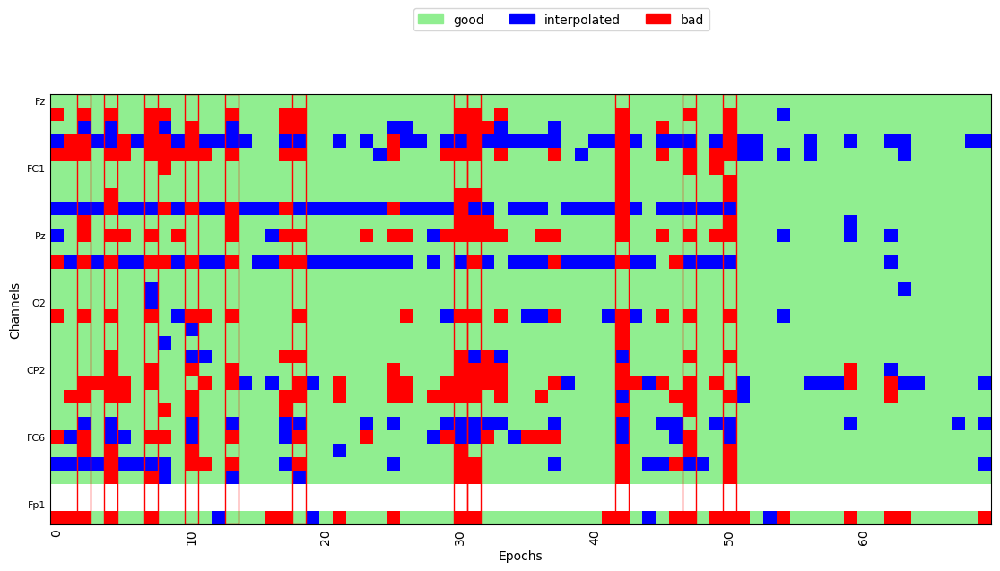

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/428 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/428 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/428 [00:00<?,       ?it/s]

Dropped 13 epochs: 117, 118, 119, 185, 256, 299, 310, 311, 318, 359, 365, 388, 414


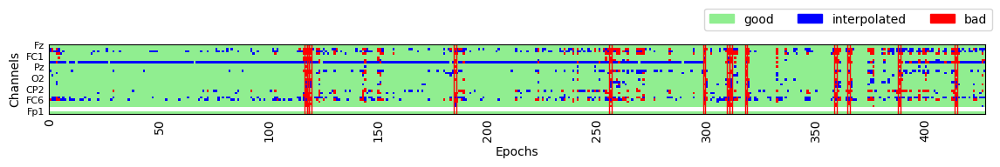

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 3 epochs: 48, 50, 62


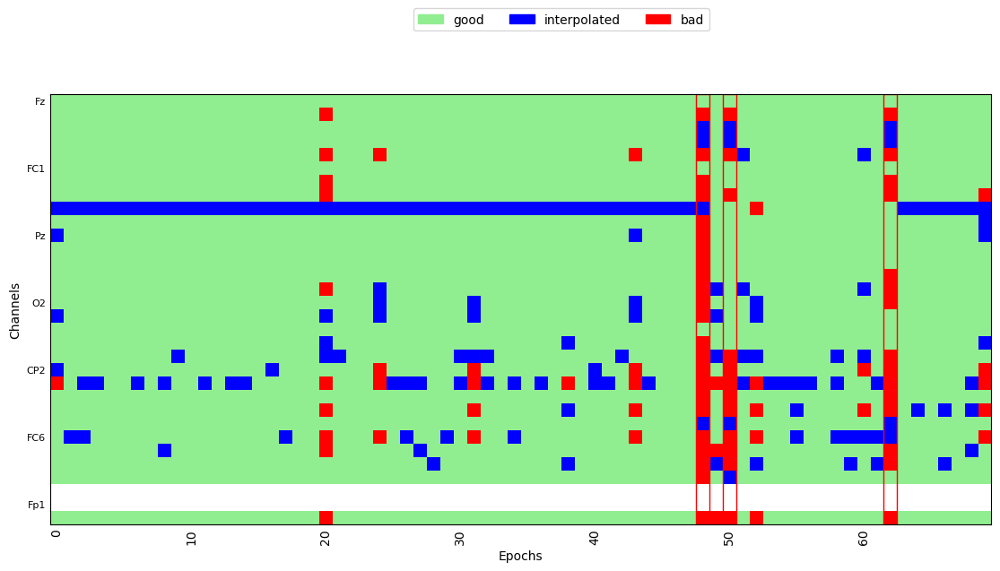

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/425 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/425 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=1


  0%|          | Repairing epochs : 0/425 [00:00<?,       ?it/s]

Dropped 16 epochs: 2, 16, 104, 106, 110, 165, 178, 180, 249, 282, 323, 324, 325, 326, 337, 419


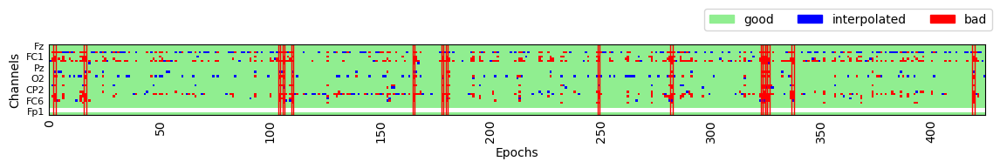

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.90 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


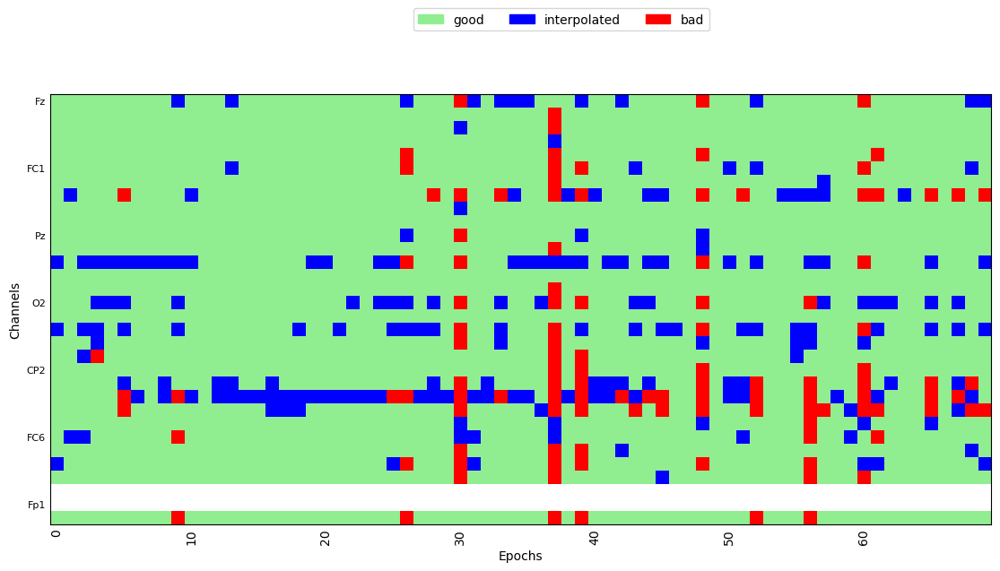

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0063_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0063_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1152499 =      0.000 ...  4609.996 secs
Ready.
Reading 0 ... 1152499  =      0.000 ...  4609.996 secs...
Not setting metadata
1942 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1942 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/418 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=1


  0%|          | Repairing epochs : 0/418 [00:00<?,       ?it/s]

Dropped 6 epochs: 0, 44, 142, 143, 146, 180


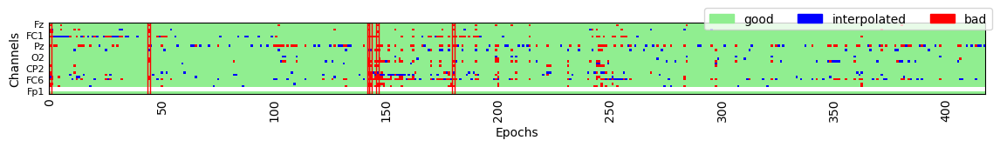

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 10 epochs: 20, 22, 23, 26, 30, 39, 44, 60, 61, 63


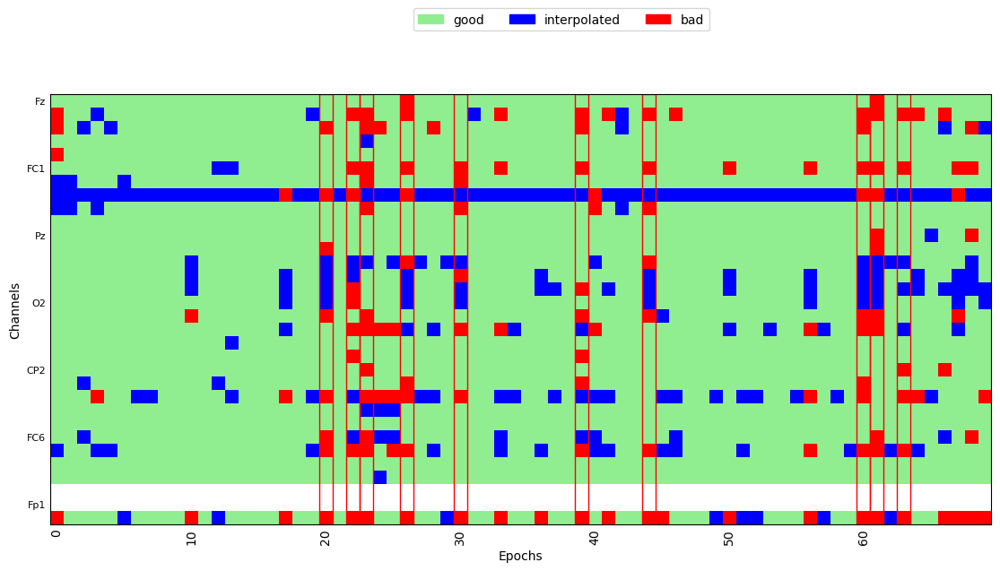

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/420 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/420 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.80 and n_interpolate=4


  0%|          | Repairing epochs : 0/420 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


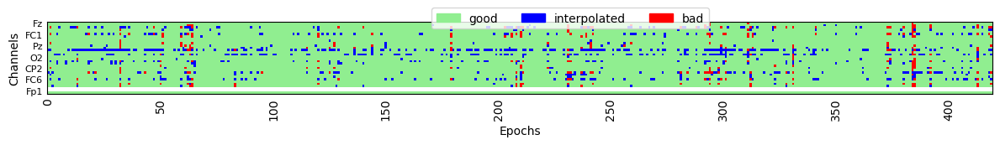

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=1


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


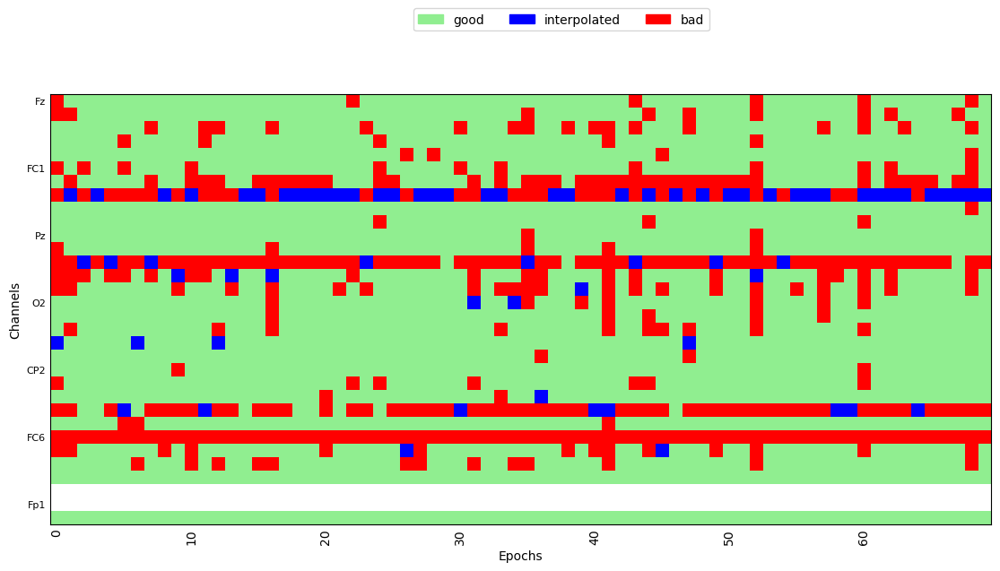

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/413 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/413 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.80 and n_interpolate=1


  0%|          | Repairing epochs : 0/413 [00:00<?,       ?it/s]

Dropped 3 epochs: 19, 20, 21


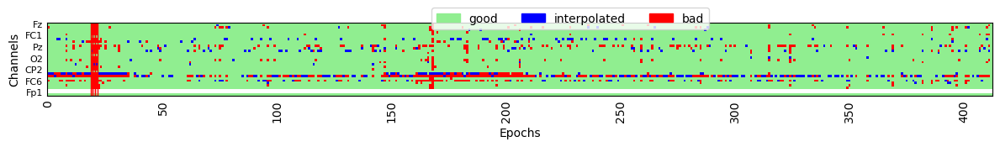

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 4


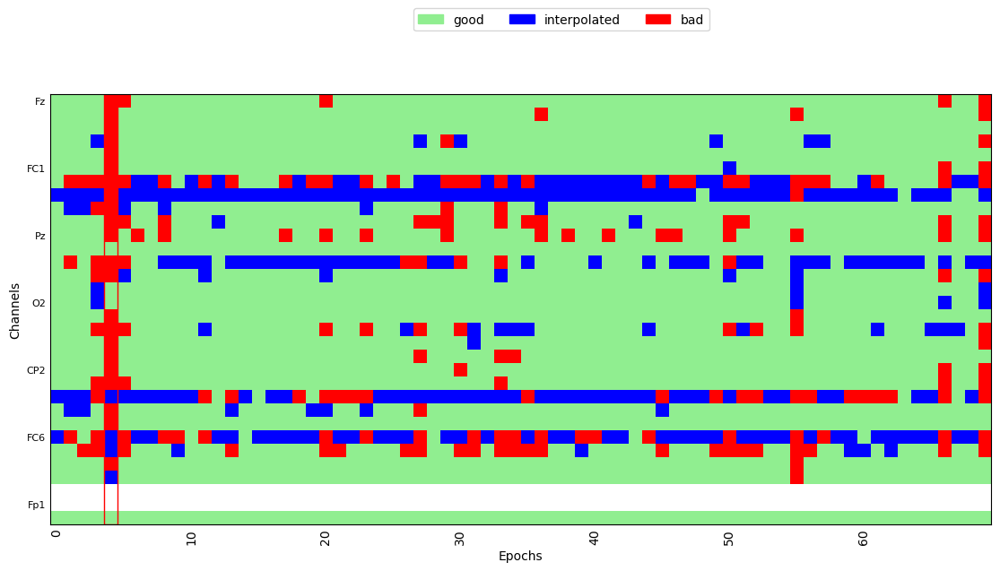

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/411 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/411 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=1


  0%|          | Repairing epochs : 0/411 [00:00<?,       ?it/s]

Dropped 33 epochs: 0, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 21, 24, 33, 48, 49, 50, 51, 53, 201, 202, 210, 247, 255, 270, 271, 361, 366, 367, 405


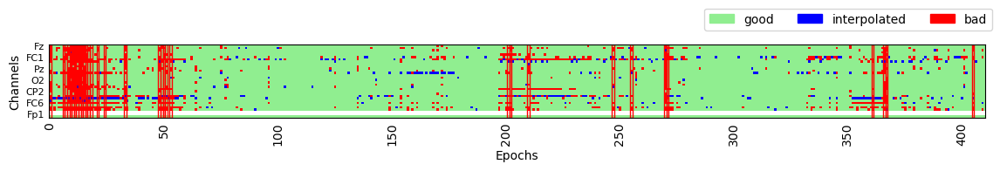

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 8 epochs: 0, 1, 2, 4, 44, 45, 61, 62


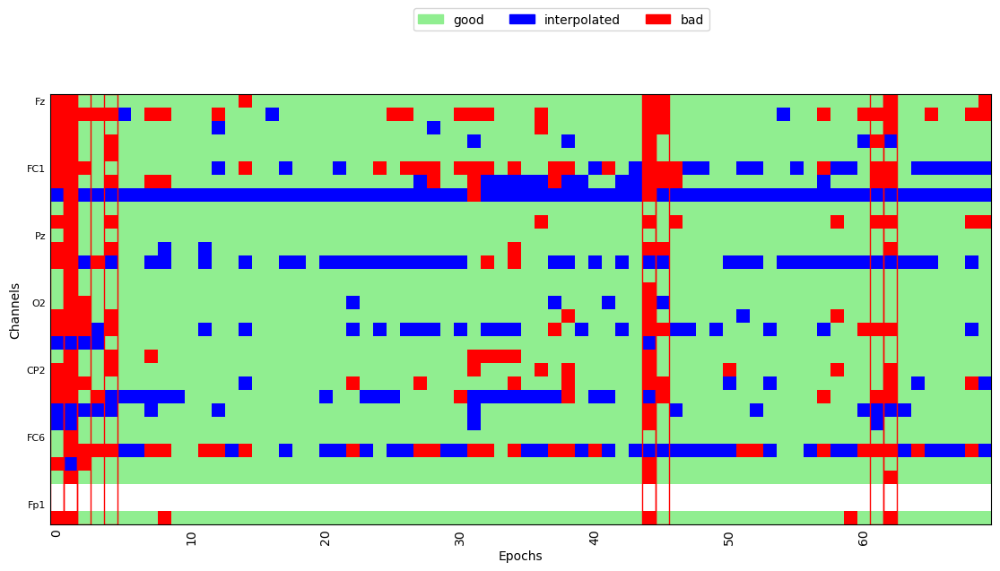

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0047_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0047_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1041889 =      0.000 ...  4167.556 secs
Ready.
Reading 0 ... 1041889  =      0.000 ...  4167.556 secs...
Not setting metadata
1968 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1968 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/424 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=1


  0%|          | Repairing epochs : 0/424 [00:00<?,       ?it/s]

Dropped 6 epochs: 172, 173, 290, 335, 337, 398


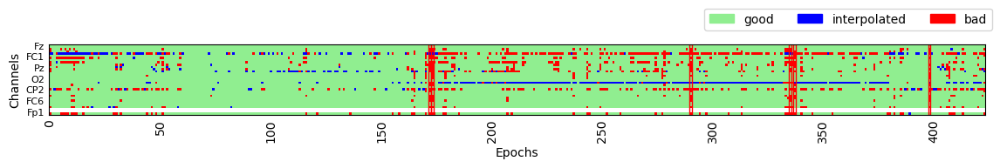

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 8, 56, 65, 66, 68


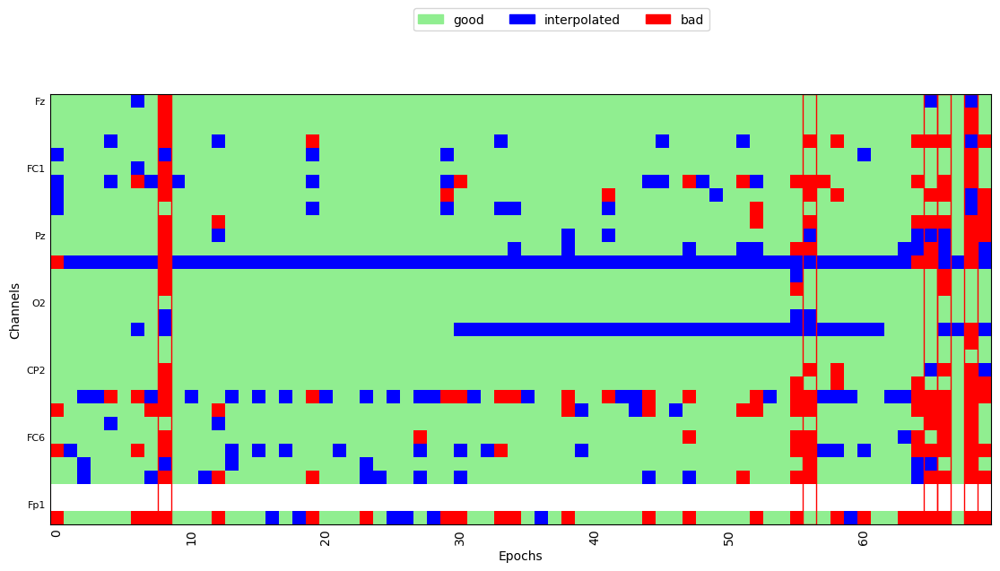

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/400 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/400 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=1


  0%|          | Repairing epochs : 0/400 [00:00<?,       ?it/s]

Dropped 7 epochs: 11, 12, 90, 177, 178, 335, 341


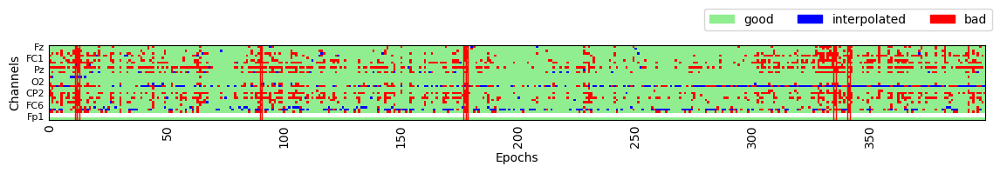

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


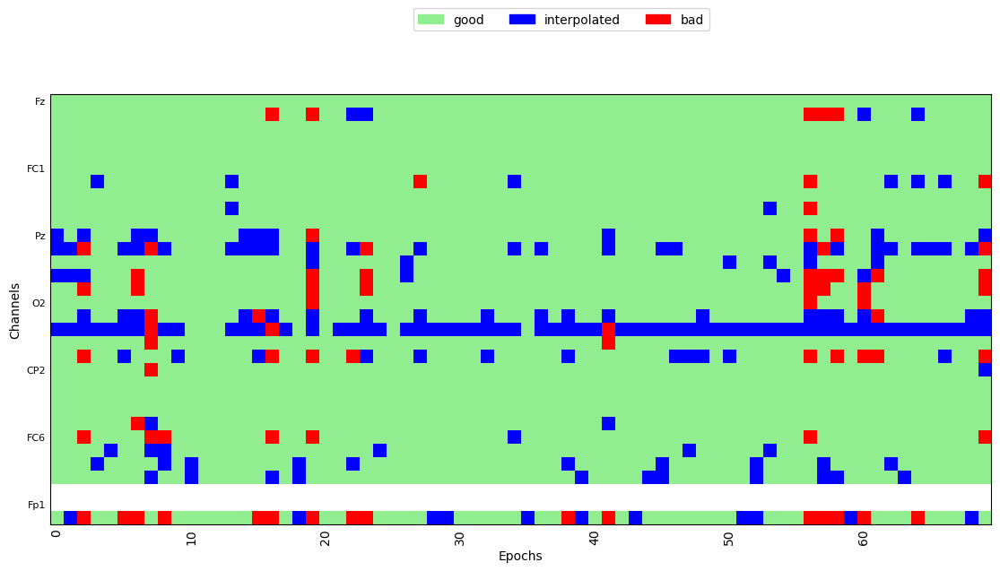

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/425 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/425 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.90 and n_interpolate=4


  0%|          | Repairing epochs : 0/425 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


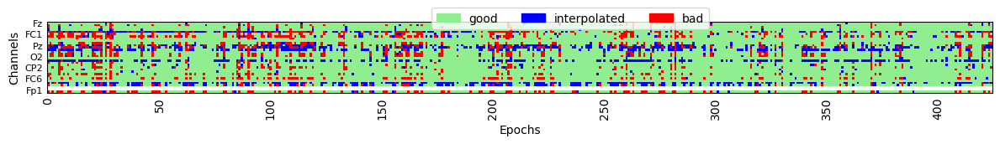

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 4, 14, 42, 45


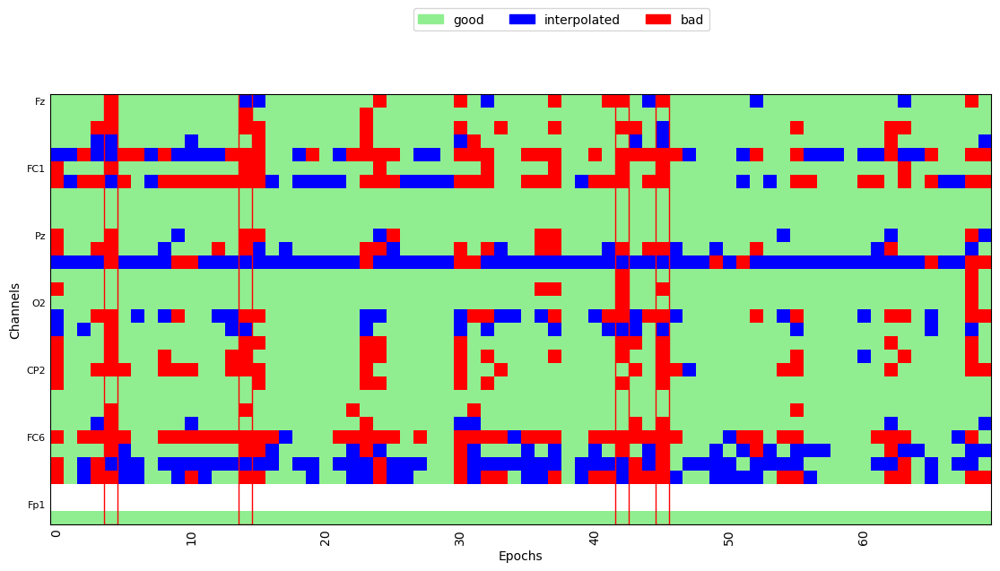

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/439 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/439 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/439 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


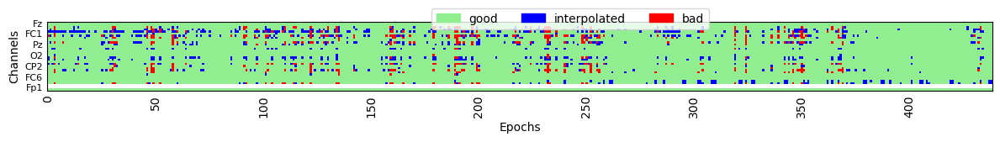

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


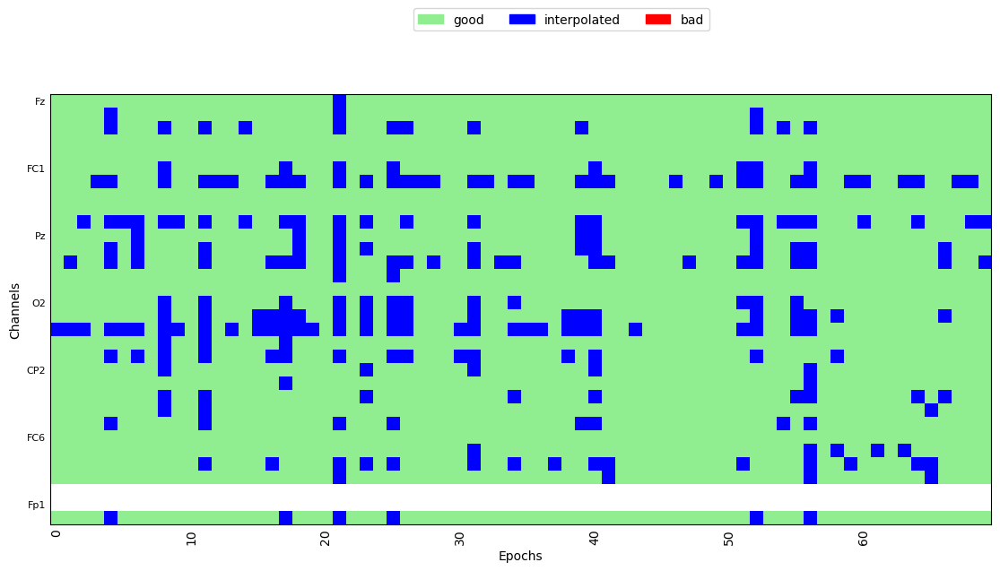

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0029_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0029_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1069244 =      0.000 ...  4276.976 secs
Ready.
Reading 0 ... 1069244  =      0.000 ...  4276.976 secs...
Not setting metadata
1997 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1997 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/437 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/437 [00:00<?,       ?it/s]

Dropped 10 epochs: 170, 331, 344, 355, 366, 386, 414, 424, 427, 428


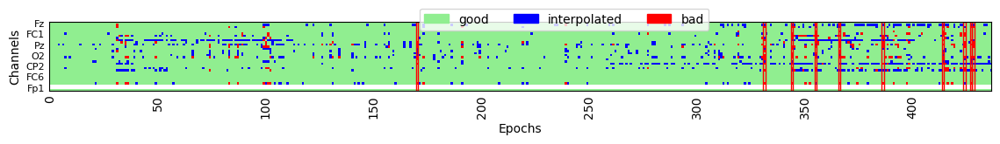

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


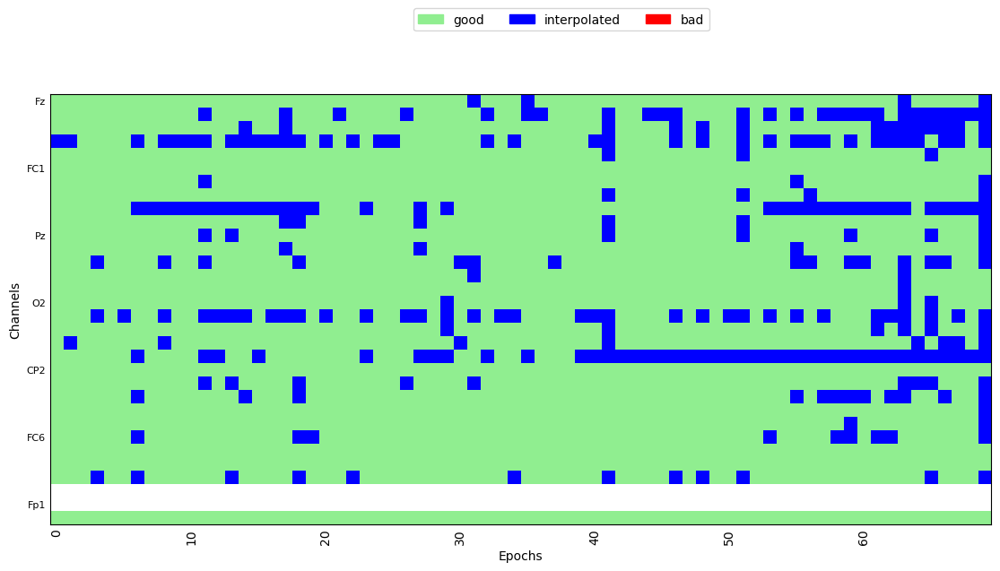

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/424 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/424 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=1


  0%|          | Repairing epochs : 0/424 [00:00<?,       ?it/s]

Dropped 7 epochs: 3, 16, 174, 211, 341, 375, 378


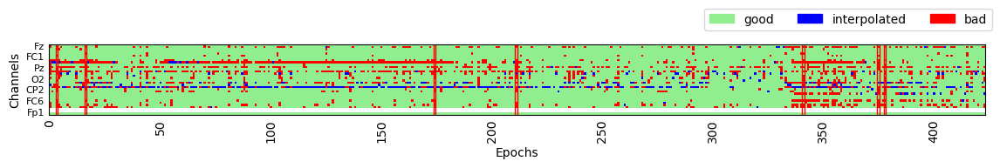

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

Dropped 2 epochs: 55, 56


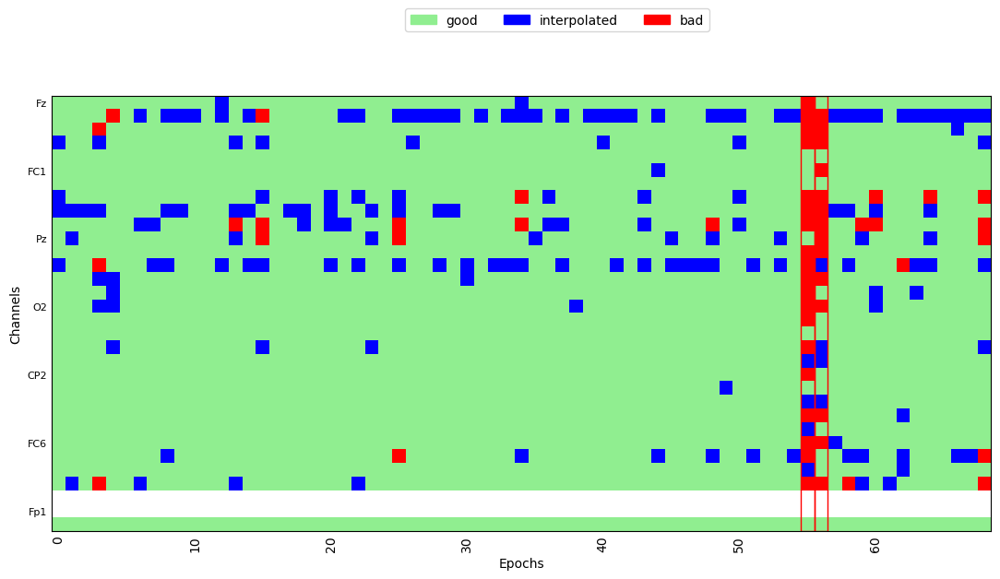

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/418 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/418 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=1


  0%|          | Repairing epochs : 0/418 [00:00<?,       ?it/s]

Dropped 1 epoch: 26


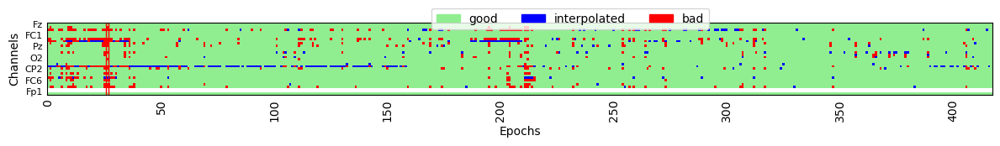

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 3


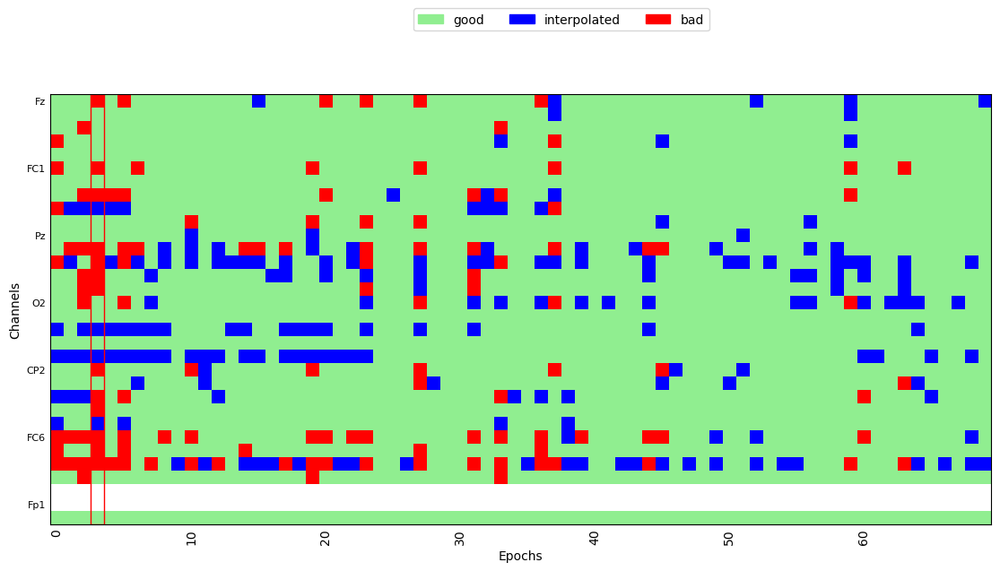

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/439 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/439 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/439 [00:00<?,       ?it/s]

Dropped 6 epochs: 14, 17, 187, 204, 257, 258


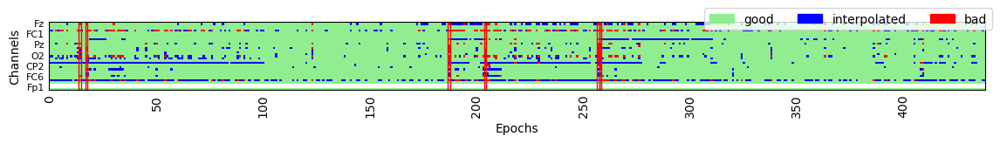

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


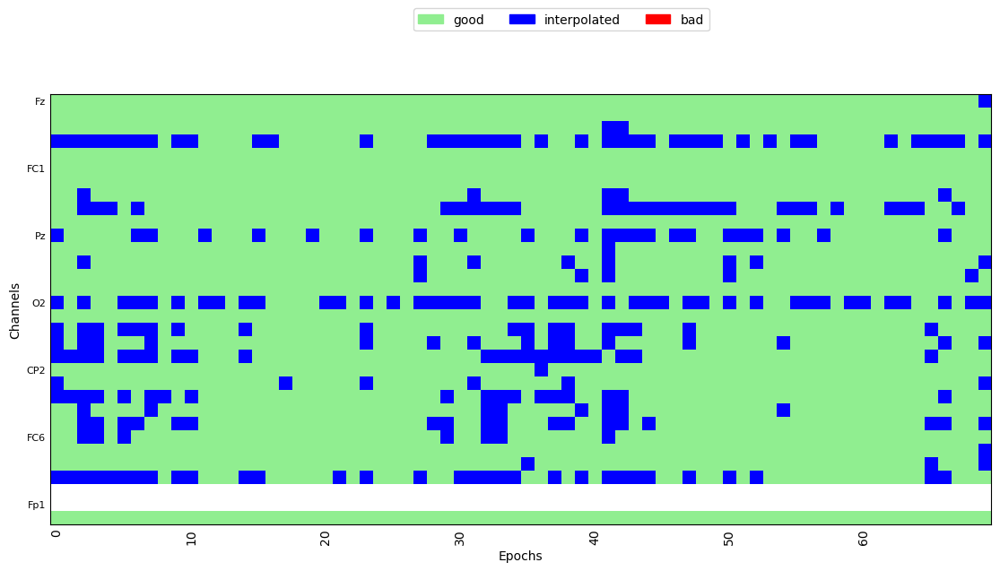

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0051_VOT_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:45: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/CUE2024_0051_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1062194 =      0.000 ...  4248.776 secs
Ready.
Reading 0 ... 1062194  =      0.000 ...  4248.776 secs...
Not setting metadata
2022 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 2022 events and 301 original time points ...
0 bad epochs dropped


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_89858/3253551493.py:51: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp2', 'Fp1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


Running autoreject on ch_type=eeg


...

  0%|          | Repairing epochs : 0/423 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.90 and n_interpolate=1


  0%|          | Repairing epochs : 0/423 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


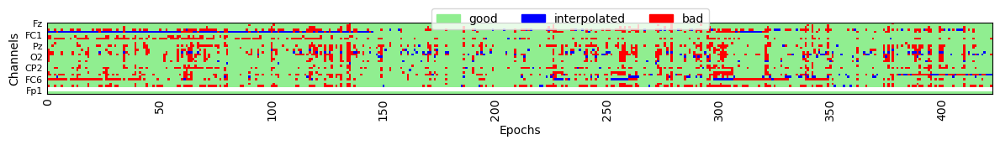

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 15 epochs: 1, 8, 12, 13, 14, 16, 23, 25, 49, 56, 57, 58, 59, 65, 67


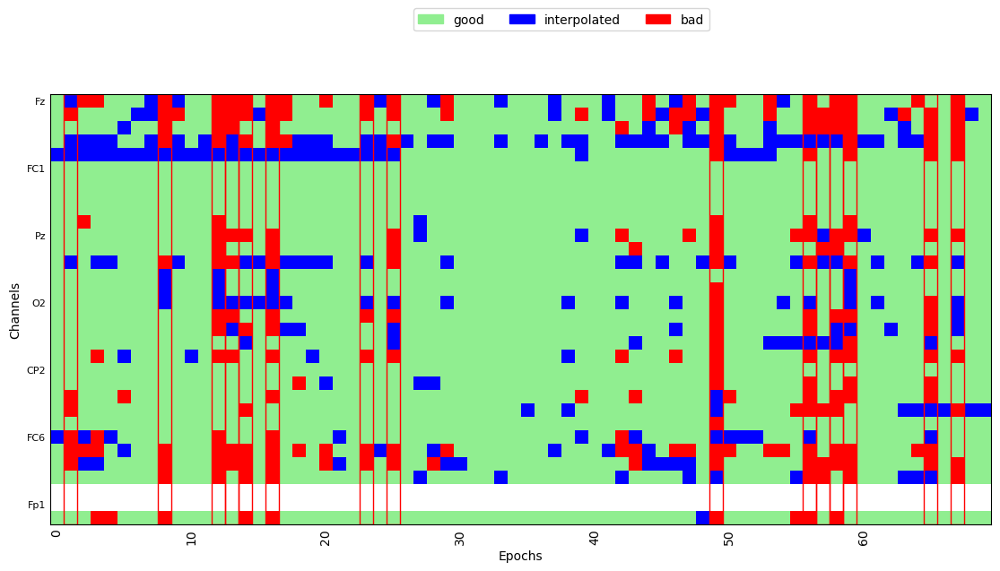

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/458 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/458 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=1


  0%|          | Repairing epochs : 0/458 [00:00<?,       ?it/s]

Dropped 1 epoch: 353


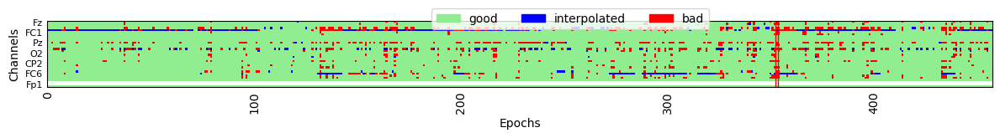

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 9 epochs: 18, 23, 27, 42, 45, 51, 56, 66, 69


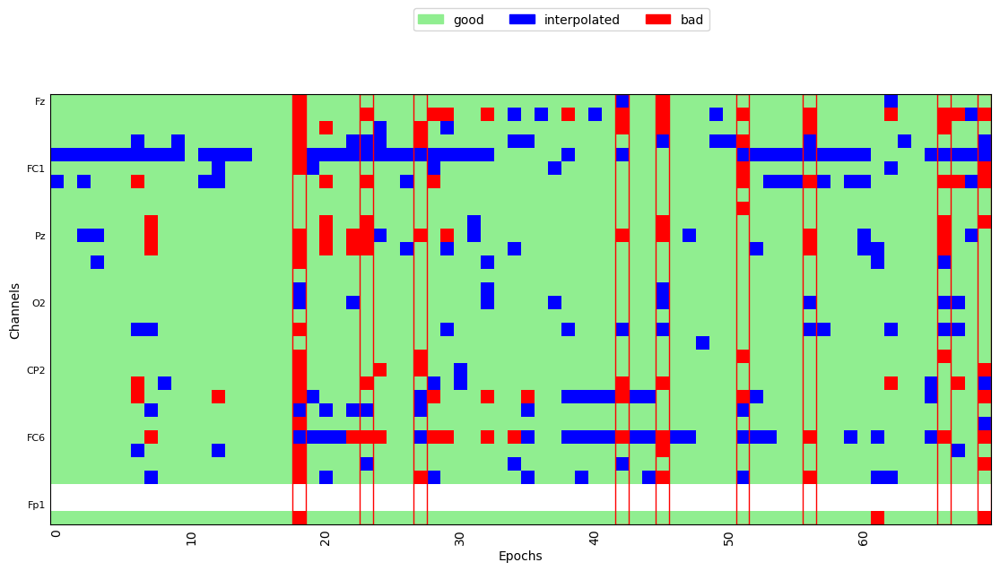

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/460 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/460 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/460 [00:00<?,       ?it/s]

Dropped 16 epochs: 9, 21, 29, 33, 37, 38, 44, 181, 205, 214, 219, 220, 274, 287, 289, 291


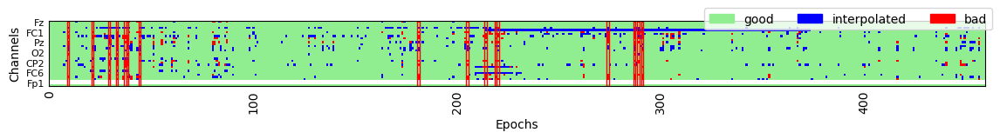

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=1


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 11, 32


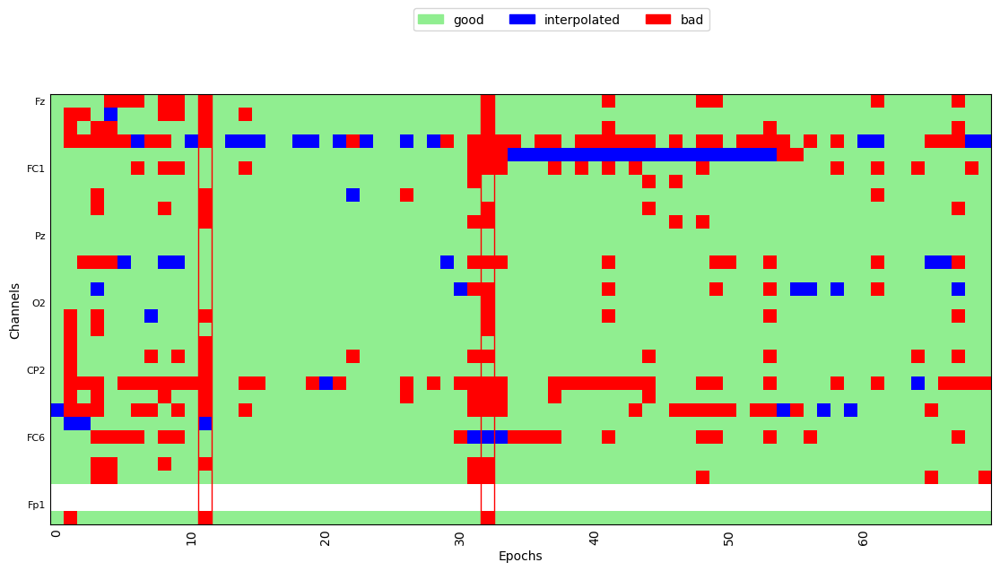

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/401 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/401 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/401 [00:00<?,       ?it/s]

Dropped 45 epochs: 10, 60, 64, 65, 66, 93, 100, 104, 107, 112, 113, 119, 120, 122, 123, 127, 133, 144, 231, 235, 238, 239, 244, 246, 247, 262, 268, 278, 279, 291, 296, 299, 306, 345, 347, 361, 371, 374, 380, 383, 392, 393, 394, 395, 399


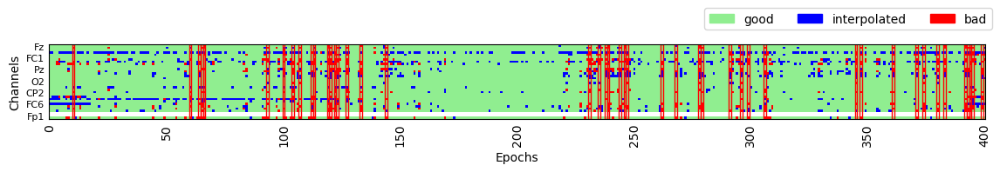

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

...

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 6, 15, 21, 42, 62


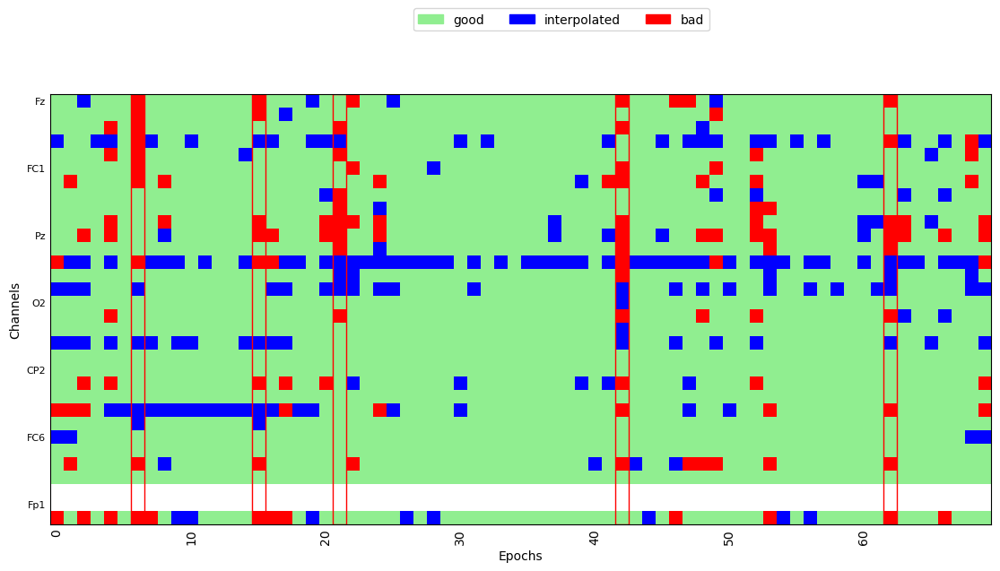

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.


In [42]:
#### parameters ####

# directory
input_dir = work_dir + 'eeg_preprocessed_2025-11-13/3_ica/0.5hf - ica_cont2cont/'
output_dir = work_dir + 'eeg_preprocessed_2025-11-13/4_evokeds/0.5hf - lof - ica_cont2cont - autoreject/FPasEOG/'
reject_log_dir = work_dir + 'eeg_preprocessed_2025-11-13/4_evokeds/0.5hf - lof - ica_cont2cont - autoreject/FPasEOG/reject_log/'

# epoch window: 
# erp_t_start = -0.1; erp_t_end = 0.7
erp_t_start = -0.2; erp_t_end = 1

# exclude participants
exclude_ppts = [
    'VOT_0008', # one bad channel not idenfified
    # 'F0_0043', # too many bad trials
    # 'VOT_0035', # too many bad trials
    'VOT_0037', # too many bad trials
]

# condition
conditions = [
    'dorsal_highStan_lowDevi_stan', 
    'dorsal_highStan_lowDevi_devi', 
    'dorsal_lowStan_highDevi_stan', 
    'dorsal_lowStan_highDevi_devi', 
    'glottal_highStan_lowDevi_stan', 
    'glottal_highStan_lowDevi_devi', 
    'glottal_lowStan_highDevi_stan', 
    'glottal_lowStan_highDevi_devi',
]

#### get epochs ####

# get file names
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)


# re-reference, then epoch
for file in all_input:
    
    if file.endswith("ica.fif") and (file.split('_')[2] + '_' + file.split('_')[1] + '_epo.fif' not in all_output):
        
        # read in data
        raw = mne.io.read_raw_fif(input_dir + file, preload = True)

        # set eog
        raw.set_channel_types({'Fp1':'eog', 'Fp2':'eog'})

        # read in channel location info
        raw.set_montage(montage)
        
        #### this is for source calculation ####
        # filter the data, optional
        # raw = raw.filter(l_freq=None, h_freq=30) 

        # sphere = mne.make_sphere_model('auto', 'auto', raw.info)
        # src = mne.setup_volume_source_space(sphere=sphere, exclude=30., pos=15.)
        # forward = mne.make_forward_solution(raw.info, trans=None, src=src, bem=sphere)
        # raw = raw.set_eeg_reference('REST', forward=forward)
        ########################################
        
        # get event info for segmentation
        events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
        
        # segmentation for ERP
        epochsArray = mne.Epochs(
            raw,
            events = events_from_annot, event_id = event_dict,
            tmin = erp_t_start, tmax = erp_t_end,
            # apply baseline correction
            # baseline = (None, 0),
            # remove epochs that meet the rejection criteria
            reject = None,
            preload = True,
        )

        ##### autoreject #####
        
        # get ppt info
        ppt = file.split('_')[2] + '_' + file.split('_')[1]

        # initialize evoked list
        evoked_list = []
        
        for cond in conditions:

            # extract epochs of that condition
            epochs = epochsArray[cond]

            # apply autoreject
            # set param
            ar = AutoReject(random_state=42)
            # apply
            epochs_ar, reject_log = ar.fit_transform(epochs, return_log=True)

            # save the reject log figure to a file
            reject_log.plot('horizontal').savefig(reject_log_dir + ppt + '_' + cond + '_reject.png', dpi=300, bbox_inches='tight')

            ##### log trial count #####
            n_totalEpochs = len(reject_log.bad_epochs)
            n_badEpochs = sum(reject_log.bad_epochs)

            # # remove 0-trial events
            # if trial_count==0:
            #     del epochs.event_id[k]
            
            # good trial rate
            badEpochs_rate = round(n_badEpochs/n_totalEpochs, 2)

            # log reject summary
            with open(output_dir + 'epoch_summary.txt', 'a+') as f:
                _ =f.write(ppt + '\t' + cond + '\t' + str(n_totalEpochs) + '\t' + str(badEpochs_rate) + '\n')

            # average-mastoids re-reference
            epochs_ar.set_eeg_reference(ref_channels = ['TP9', 'TP10'])
            
            # average | get ERP for each condition
            evoked = epochs_ar.average(picks=['eeg', 'eog'], by_event_type=False)

            # add condition label
            evoked.comment = cond

            # append
            evoked_list.append(evoked)
            
        # save
        mne.write_evokeds(output_dir + ppt + '_ave.fif', evoked_list)

## Evoked data quality check

Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/5_evokeds/F0_0001_ave.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms (dorsal_highStan_lowDevi_stan)
        0 CTF compensation matrices available
        nave = 335 - aspect type = 100
No projector specified for this dataset. Please consider the method self.add_proj.
Loaded Evoked data is baseline-corrected (baseline: [-0.1, 0] s)
<Info | 12 non-empty values
 bads: []
 ch_names: Fz, F3, F7, FT9, FC5, FC1, C3, T7, CP5, CP1, Pz, P3, P7, O1, Oz, ...
 chs: 30 EEG
 custom_ref_applied: True
 dig: 33 items (3 Cardinal, 30 EEG)
 file_id: 4 items (dict)
 highpass: 1.0 Hz
 lowpass: 100.0 Hz
 maxshield: False
 meas_date: 2024-07-17 11:57:26 UTC
 meas_id: 4 items (dict)
 nchan: 30
 projs: []
 sfreq: 250.0 Hz
>
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).


/opt/anaconda3/lib/python3.12/site-packages/mne/viz/utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


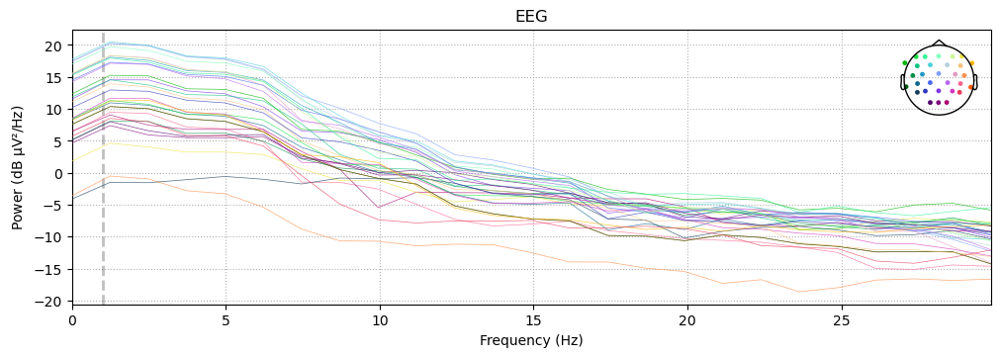

No projector specified for this dataset. Please consider the method self.add_proj.


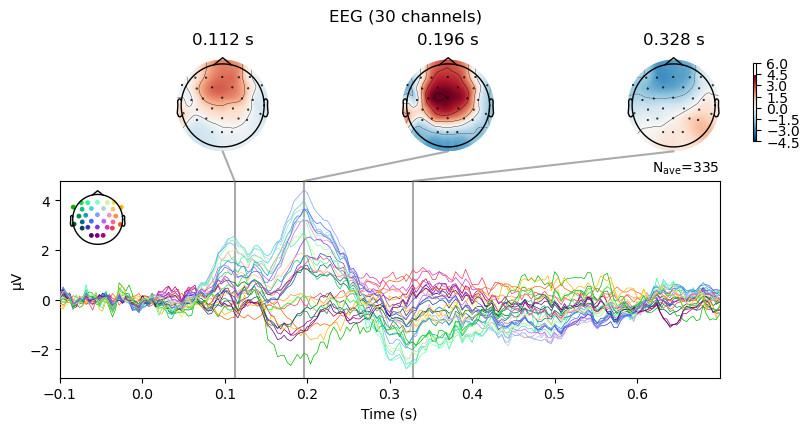

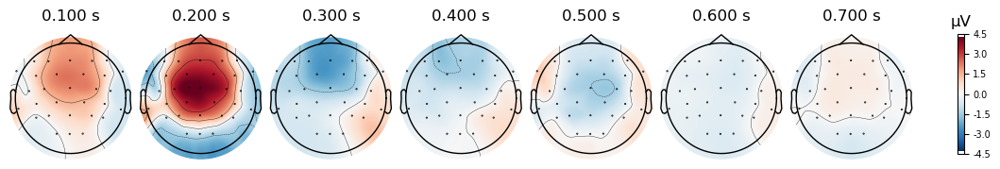

In [60]:
## parameters
# frequency of the eeg recording for audio downsampling
# eeg_freq = 500

# directory
input_dir = work_dir + '/data_preprocessed/5_evokeds/'

# file name
file = 'F0_0001_ave.fif'

# read in file
evokeds = mne.read_evokeds(input_dir + file, condition='dorsal_highStan_lowDevi_stan')

# check information
print(evokeds.info)

# plot spectrum of raw EEG
evokeds.compute_psd(fmax=30).plot()
plt.show()

# # if needed, plot a spectrum for each channel
# for ch_ind in epochs.info['ch_names']:
#     print('=====================')
#     print(ch_ind)
#     epochs.compute_psd(fmax=30, picks = ch_ind).plot(show=False, amplitude=False)
#     plt.show()

# butterfly plot
evokeds.plot_joint(picks="eeg")
evokeds.plot_topomap(times=[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7], ch_type="eeg")
plt.show()

# TRF
segmenting continuous EEG into epochs for ERSP analysis
- re-reference
- segmentation

In [18]:
# directory
input_dir = work_dir + 'data_preprocessed/3_ica/'
output_dir = work_dir + 'data_preprocessed/4_tfr_evokeds_unnormalized/'

# Epoch window: 
epoch_t_start = -1; epoch_t_end = 2

# criteria to reject epoch
reject_criteria = dict(eeg = 100e-6)       # 100 µV
# reject_criteria = dict(eeg = 150e-6)       # 150 µV
# reject_criteria = dict(eeg = 200e-6)       # 200 µV

exclude_ppts = [
    'F0_0059', # too noisy -> cells of 0 trial
]

tfr_method = 'morlet'

# frequencies
freq_start = 3
freq_end = 30
n_freq = 28
freqs = np.linspace(start=freq_start, stop=freq_end, num=n_freq)

# cycles
cycl_start = 3
cycl_step = 0.8
n_cycl = n_freq
n_cycles = np.linspace(start=cycl_start, stop=cycl_start+cycl_step*(n_cycl-1), num=n_cycl)

condition_list = [
    'dorsal_highStan_lowDevi_stan',
    'dorsal_lowStan_highDevi_stan',
    'glottal_highStan_lowDevi_stan',
    'glottal_lowStan_highDevi_stan',
]

# initialize a list for subjects with too many bad trials
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)


#### re-reference, and epoch ####
for file in all_input:
    
    if file.endswith("ica.fif"):

        # get participant info
        ppt = file.split('_')[2] + '_' + file.split('_')[1]

        # skip bad participants
        if (ppt + '_tfr.hdf5' in all_output) or (ppt in exclude_ppts):
            continue
        
        # read in data
        raw = mne.io.read_raw_fif(input_dir + file, preload = True)
        
        # average-mastoids re-reference
        raw.set_eeg_reference(ref_channels = ['TP9', 'TP10'])
        
        #### this is for source calculation ####
        # filter the data, optional
        # raw = raw.filter(l_freq=None, h_freq=30) 

        # sphere = mne.make_sphere_model('auto', 'auto', raw.info)
        # src = mne.setup_volume_source_space(sphere=sphere, exclude=30., pos=15.)
        # forward = mne.make_forward_solution(raw.info, trans=None, src=src, bem=sphere)
        # raw = raw.set_eeg_reference('REST', forward=forward)
        ########################################

        # pick EEG channels
        # picks = mne.pick_types(raw.info, eeg = True)
        
        # get event info for segmentation
        events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
        
        # segmentation for ERP
        epochs = mne.Epochs(
            raw,
            events = events_from_annot, event_id = event_dict,
            tmin = epoch_t_start, tmax = epoch_t_end,
            # apply baseline correction
            baseline = None,
            # remove epochs that meet the rejection criteria
            reject = reject_criteria,
            preload = True,
        )
        


        # for each event, remove 0 trial events, record info, and check if a subject is bad
        for k, v in event_dict.items():
            
            # good trial count
            trial_count = len(epochs[k])
            
            # remove 0 trial event
            if trial_count==0:
                del epochs.event_id[k]
                
            # good trial rate
            goodTrial_rate = round( trial_count/sum(events_from_annot[:,2]==v), 2 )
            
            # record epoch summary
            with open(output_dir + 'epoch_summary.txt', 'a+') as f:
                _ =f.write(ppt + '\t' + k + '\t' + str(trial_count) + '\t' + str(goodTrial_rate) + '\n')


        # ERSP

        # initialize tfrs list
        tfrs = []
        
        for condition in condition_list:
            # compute ERSP
            power = epochs[condition].compute_tfr(
                method=tfr_method,
                freqs=freqs,
                n_cycles=n_cycles,
                # return_itc=True,
            )
            
            # average
            power = power.average(method = 'mean', dim = 'epochs')

            # add comment
            power.comment = condition

            # append
            tfrs.append(power)
            
        # save single subject file
        mne.time_frequency.write_tfrs(fname=output_dir + ppt + '_tfr.hdf5', 
                                      tfr=tfrs)

        # release memory
        del power, tfrs

Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/3_ica/CUE2024_0020_F0_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_11350/3769507918.py:56: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/3_ica/CUE2024_0020_F0_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1033989 =      0.000 ...  4135.956 secs
Ready.
Reading 0 ... 1033989  =      0.000 ...  4135.956 secs...
EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Not setting metadata
1981 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 1981 events and 751 original time points ...
    Rejecting  epoch based on EEG : ['F8']
    Rejecting  epoch based on EEG : ['F8']
    Rejecting  epoch based on EEG : ['FT10', 'F8']
    Rejecting  epoch based on EEG : ['FT10', 'F8']
    Rejecting  epoch based on EEG : ['FT10', 'F8']
    Rejecting  epoch based on EEG : ['FT9', 'T7', 'CP5', 'P7', 'O1', 'Oz', 'T8', 'FT10', 'F8']
    Rejecting  epoch based on EEG : ['C3', 'CP5', 'CP6', 'T8', 'FT10', 'FC6', 'F8']
    Rejecting  epoch based on EEG : ['C3', 'CP5', 'CP6', 'T8', 'FT10', 'FC6', 'F8']
    Rejecting  epoch based on EEG : ['F3', 'FT9', 'FC5', 'FC1', 'C3', 'T7', 'CP5', 'CP1', 'P3', 'P7', 'CP

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    2.3s
[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    2.3s
[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    2.0s
[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    2.0s


Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/3_ica/CUE2024_0018_F0_corr_prep_ica.fif...


...

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    3.0s
[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    2.4s
[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    2.3s
[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    2.1s


Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/3_ica/CUE2024_0022_F0_corr_prep_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_11350/3769507918.py:56: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/3_ica/CUE2024_0022_F0_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 1859 ... 1019640 =      7.436 ...  4078.560 secs
Ready.
Reading 0 ... 1017781  =      0.000 ...  4071.124 secs...
EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Not setting metadata
1932 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 1932 events and 751 original time points ...
    Rejecting  epoch based on EEG : ['F4']
    Rejecting  epoch based on EEG : ['F4']
    Rejecting  epoch based on EEG : ['F3', 'F4']
    Rejecting  epoch based on EEG : ['F3', 'F4']
    Rejecting  epoch based on EEG : ['F4']
    Rejecting  epoch based on EEG : ['F4']
    Rejecting  epoch based on EEG : ['F7', 'FT9', 'O1', 'Oz', 'O2', 'FT10', 'F4']
    Rejecting  epoch based on EEG : ['F7', 'FT9', 'O1', 'Oz', 'O2', 'FT10', 'F4']
    Rejecting  epoch based on EEG : ['O1']
    Rejecting  epoch based on EEG : ['O1']
10 bad epochs dropped


[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    3.1s
[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    2.3s
[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    2.1s
[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    2.3s


# Data for GAM

In [2]:
# directory
input_dir = work_dir + 'data_preprocessed/3_ica/'
output_dir = work_dir + 'data_analysis/gam/'
# create a folder if the folder doesn't exist
# os.makedirs(output_dir, exist_ok=True)


# epoch window: 
erp_t_start = -0.2; erp_t_end = 0.8
# baseline
epoch_baseline = (-0.2, 0)

# criteria to reject epoch
reject_criteria = dict(eeg = 100e-6)       # 100 µV


#### get data ####

# get file names
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)


# re-reference, then epoch
for file in all_input:
    
    if file.endswith("ica.fif") and (file.split('_')[2] + '_' + file.split('_')[1] + '_gam.csv' not in all_output):
        
        # read in data
        raw = mne.io.read_raw_fif(input_dir + file, preload = True)
        
        # average-mastoids re-reference
        raw.set_eeg_reference(ref_channels = ['TP9', 'TP10'])
        
        # get event info for segmentation
        events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
        
        # segmentation for ERP
        epochs = mne.Epochs(
            raw,
            events = events_from_annot, event_id = event_dict,
            tmin = erp_t_start, tmax = erp_t_end,
            # apply baseline correction
            baseline = epoch_baseline,
            # remove epochs that meet the rejection criteria
            reject = reject_criteria,
            preload = True,
        )

        # get participant label
        ppt = file.split('_')[2] + '_' + file.split('_')[1]

        ##########################################################
        #### remove 0-trial events, and log epoch info ####
        for k, v in event_dict.items():
            
            # good trial count
            trial_count = len(epochs[k])
            
            # remove 0 trial event
            if trial_count==0:
                del epochs.event_id[k]
                
            # good trial rate
            goodTrial_rate = round( trial_count/sum(events_from_annot[:,2]==v), 2 )
            
            # record epoch summary
            with open(output_dir + 'epoch_summary.txt', 'a+') as f:
                _ =f.write(ppt + '\t' + k + '\t' + str(trial_count) + '\t' + str(goodTrial_rate) + '\n')
        ##########################################################
        
        # apply baseline
        epochs.apply_baseline(baseline=epoch_baseline, verbose='WARNING')

        # extract data
        df = epochs.to_data_frame(time_format='ms')

        # add info of group, ppt, and item
        df['participant'] = ppt
            
        # save
        df.to_csv(output_dir + ppt + '_gam.csv', index=False)
        
        # reduce memory usage
        del df

Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/3_ica/CUE2024_0064_VOT_corr_prep_ica.fif...
    Range : 0 ... 1004589 =      0.000 ...  4018.356 secs
Ready.


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_22332/1331711903.py:30: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/3_ica/CUE2024_0064_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


Reading 0 ... 1004589  =      0.000 ...  4018.356 secs...
EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Not setting metadata
1886 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1886 events and 251 original time points ...
    Rejecting  epoch based on EEG : ['F3']
    Rejecting  epoch based on EEG : ['Fz', 'F3', 'F7', 'FT9', 'FC5', 'FC1', 'C3', 'T7', 'CP5', 'P3', 'P7', 'O1', 'P8', 'CP6', 'C4', 'F8']
    Rejecting  epoch based on EEG : ['F3', 'P7']
    Rejecting  epoch based on EEG : ['O1', 'Oz']
    Rejecting  epoch based on EEG : ['P7']
    Rejecting  epoch based on EEG : ['F3']
    Rejecting  epoch based on EEG : ['F3', 'F7', 'FC5', 'CP5']
    Rejecting  epoch based on EEG : ['F3', 'F7']
    Rejecting  epoch based on EEG : ['F3', 'F7']
    Rejecting  epoch based on EEG : ['F3', 'F7']
    Rejecting  epoch based on EEG : ['F3', 'F7', 'FC5']
    Rejecting  epoch based on 

/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_22332/1331711903.py:30: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/3_ica/CUE2024_0058_F0_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Not setting metadata
1915 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1915 events and 251 original time points ...
    Rejecting  epoch based on EEG : ['F4']
    Rejecting  epoch based on EEG : ['FC6']
    Rejecting  epoch based on EEG : ['FC6']
    Rejecting  epoch based on EEG : ['FC6']
    Rejecting  epoch based on EEG : ['Fz', 'F3', 'F7', 'FT9', 'FC5', 'FC1', 'C3', 'T7', 'CP5', 'P3', 'P7', 'O1', 'Oz', 'CP2', 'Cz', 'C4', 'FC6', 'FC2', 'F4', 'F8']
    Rejecting  epoch based on EEG : ['F7', 'FT9', 'FC1', 'P7', 'O1', 'Oz', 'O2', 'C4', 'F8']
    Rejecting  epoch based on EEG : ['FT9']
    Rejecting  epoch based on EEG : ['F4']
    Rejecting  epoch based on EEG : ['F4']
    Rejecting  epoch based on EEG : ['F4']
    Rejecting  epoch based on EEG : ['FT9', 'FC6']
    Rejecting  epoch based on EEG : ['F3', 'F7', 'FT9', 'T7', '

...

    Range : 13115 ... 1067170 =     52.460 ...  4268.680 secs
Ready.
Reading 0 ... 1054055  =      0.000 ...  4216.220 secs...
EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Not setting metadata
1997 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1997 events and 251 original time points ...
    Rejecting  epoch based on EEG : ['CP5']
    Rejecting  epoch based on EEG : ['CP6', 'C4', 'FT10', 'FC6', 'F4']
    Rejecting  epoch based on EEG : ['FT10']
    Rejecting  epoch based on EEG : ['CP5', 'CP6', 'C4', 'FT10', 'FC6', 'F4']
    Rejecting  epoch based on EEG : ['CP5']
    Rejecting  epoch based on EEG : ['C4', 'FT10', 'FC6', 'F4']
    Rejecting  epoch based on EEG : ['C4']
    Rejecting  epoch based on EEG : ['CP6', 'C4', 'FT10']
    Rejecting  epoch based on EEG : ['F3', 'F7', 'FT9', 'C3', 'T7', 'CP5', 'CP1', 'P3', 'P7', 'CP6', 'CP2', 'C4', 'FT10', 'FC6', 'FC2', 'F4', 'F8

/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_22332/1331711903.py:30: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/3_ica/CUE2024_0051_VOT_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


Reading 0 ... 1062194  =      0.000 ...  4248.776 secs...
EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Not setting metadata
2022 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 2022 events and 251 original time points ...
    Rejecting  epoch based on EEG : ['O1']
    Rejecting  epoch based on EEG : ['FC6']
    Rejecting  epoch based on EEG : ['FC6']
    Rejecting  epoch based on EEG : ['FC6']
    Rejecting  epoch based on EEG : ['FC6']
    Rejecting  epoch based on EEG : ['FC6']
    Rejecting  epoch based on EEG : ['FC6']
    Rejecting  epoch based on EEG : ['FC6']
    Rejecting  epoch based on EEG : ['FC6']
    Rejecting  epoch based on EEG : ['FC6']
    Rejecting  epoch based on EEG : ['O1']
    Rejecting  epoch based on EEG : ['FC6']
    Rejecting  epoch based on EEG : ['FC2', 'F4']
    Rejecting  epoch based on EEG : ['T8']
    Rejecting  epoch based on EEG : ['O1']

/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_22332/1331711903.py:30: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/3_ica/CUE2024_0022_F0_corr_prep_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


Reading 0 ... 1017781  =      0.000 ...  4071.124 secs...
EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Not setting metadata
1932 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1932 events and 251 original time points ...
    Rejecting  epoch based on EEG : ['F3', 'F4']
    Rejecting  epoch based on EEG : ['F7', 'FT9', 'O1', 'Oz', 'O2', 'FT10', 'F4']
2 bad epochs dropped
